# 14 · Bayes' Rule, Base Rates & Decisions Under Uncertainty
*AI Foundations · Notebook 14 of 19*

Sooner or later every deployed model raises its hand and says *"this one looks bad"*: a crack detector flags a bridge joint, an email filter holds a message in quarantine, a satellite model warns about crop disease. What should happen next? The alarm itself is not the answer. To act well you have to make two conversions. First, turn the model's **reliability** ("it catches 94% of cracks") into the quantity you actually need ("how likely is *this* joint to be cracked?"). Second, turn that **belief**, together with the very different costs of the two kinds of mistakes, into an **action**. This notebook builds both conversions from the ground up: **Bayes' rule** to update beliefs, and **decision theory** to act on them.

Along the way you will see why a detector that is right 96% of the time can be wrong most of the times it fires, why numbers measured on a balanced validation set can mislead you after deployment, how to pick a decision threshold from costs *and* a limited review budget, how to fuse several alarms, and how to decide whether an extra measurement is worth paying for.

**What you will learn**
- Conditional probability, the multiplication rule, the law of total probability, and Bayes' theorem in four equivalent forms: probabilities, natural frequencies, odds with likelihood ratios, and additive log-odds.
- The diagnostic vocabulary (sensitivity = recall = TPR, specificity = TNR, FPR, FNR, prevalence, PPV = precision, NPV) and the **base-rate fallacy**.
- Why a balanced validation set tells you sensitivity and specificity but **not** deployment precision, and how to correct predicted probabilities when the class prior changes.
- Expected confusion-matrix counts in deployment, expected cost with asymmetric errors, alert-capacity constraints, choosing a threshold on a ROC curve, and the Bayes-optimal posterior threshold $p^{*} = C_{FP}/(C_{FP}+C_{FN})$.
- Combining alarms with **naive Bayes** (likelihood ratios multiply) and what goes wrong when the conditional-independence assumption fails.
- Expected utility, decision trees solved by backward induction, the expected value of perfect information (EVPI) and of sample information (EVSI), and sequential testing.
- Discrete random variables (PMF, CDF, mean, variance), Bayesian updating of a **whole distribution**, and why $\mathbb{E}[C(X)] \ne C(\mathbb{E}[X])$ changes decisions.

Every key analytic result in this notebook is double-checked by a Monte Carlo simulation, and the notebook ends with 12 exam-style questions.

**Prerequisites:** basic probability (events, "and", "or", "not"), fractions and logarithms, Python and NumPy. Having met logistic regression helps in Section 4.6 but is not required.      **Estimated time:** ~5 h

**How to use this notebook:** run cells top to bottom (Runtime → Run all works). Exercises are marked ✏️, and each has an automatic checker and a hidden solution (click "Solution" to expand). Quick-check questions have hidden answers.

**Notation:** $P(A)$ is the probability of event $A$. $\bar A$ ("A-bar") is the event "not $A$", $A \cap B$ means "$A$ and $B$", and $P(A \mid B)$ is "the probability of $A$ given $B$". $\ln$ is the natural logarithm. Costs are in abstract *cost units*.

**Contents**
1. An alarm is not an answer
2. The probability toolkit
3. Bayes' theorem, four ways
4. Diagnostic metrics and the base-rate fallacy
5. From rates to deployment: expected counts, costs and capacity
6. Combining evidence: conditional independence and naive Bayes
7. Decisions under uncertainty: expected utility and the value of information
8. Beliefs about a count: updating a whole distribution
9. Exam-style practice
10. Summary and going further

In [1]:
# Setup: imports, reproducibility, plotting style, a fixed color palette and a tiny test harness.
import math
import random
import sys
from fractions import Fraction
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from cycler import cycler
from IPython.display import display
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch
from scipy import optimize, special, stats
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import BernoulliNB

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# Everything here is simulated or computed from small tables written inline, so nothing is
# downloaded. DATA_DIR is defined only for consistency with the rest of the series.
DATA_DIR = Path("data")

# One fixed, colorblind-checked categorical order, always used in this order.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
MAGENTA, GREEN, VIOLET, RED = "#e87ba4", "#008300", "#4a3aa7", "#e34948"
INK2, MUTED, LIGHT = "#52514e", "#898781", "#e1e0d9"   # secondary text, muted text, light fill

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 100, "figure.figsize": (7, 4),
    "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 11,
})
plt.rcParams["axes.prop_cycle"] = cycler(color=[BLUE, ORANGE, AQUA, YELLOW, MAGENTA, GREEN, VIOLET, RED])
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)

print(f"Python {sys.version.split()[0]} | numpy {np.__version__} | pandas {pd.__version__} | "
      f"scipy {scipy.__version__} | scikit-learn {sklearn.__version__} | matplotlib {matplotlib.__version__}")


def run_check(name, test_fn):
    """Run test_fn() and print a friendly status instead of crashing the notebook."""
    try:
        test_fn()
    except NotImplementedError:
        print(f"⏳ {name}: not implemented yet. Fill in the function and re-run this cell.")
    except AssertionError as err:
        print(f"❌ {name}: {err}")
    else:
        print(f"✅ {name}: all checks passed!")

Python 3.13.15 | numpy 2.5.3 | pandas 2.3.3 | scipy 1.18.1 | scikit-learn 1.9.1 | matplotlib 3.11.2


## 1. An alarm is not an answer

### 1.1 A thought experiment

An inspection drone flies under a highway bridge and photographs every expansion joint. An onboard model flags the joints that look cracked. Years of testing tell you three things:

- Among joints that **really are cracked**, the model flags **94%**.
- Among joints that are **sound**, it (wrongly) flags **4%**.
- On bridges of this age, about **3%** of joints are cracked at any given inspection.

The drone has just flagged joint #217. **How likely is it that joint #217 is really cracked?**

Take ten seconds and write down your guess before you read on.

Most people answer "about 94%" (the hit rate), or "96%, because the false-alarm rate is only 4%". The correct answer is **about 42%**: the flagged joint is *more likely to be sound than cracked*. Nothing is wrong with the detector. The surprise comes entirely from the **3% base rate**, and learning to see it is the first goal of this notebook.

### 1.2 Count, don't calculate

The quickest way to see the answer is to stop thinking about probabilities and imagine a concrete crowd: **10,000 joints**. Psychologists call these counts *natural frequencies*.

```
                          10,000 joints
                    /                      \
          300 cracked (3%)            9,700 sound (97%)
           /           \               /              \
    282 flagged     18 missed     388 flagged     9,312 cleared
     (94% of 300)   (6% of 300)   (4% of 9,700)   (96% of 9,700)
```

The drone raises 282 + 388 = **670** flags, and only **282** of them sit on cracked joints:

$$
P(\text{cracked} \mid \text{flagged}) = \frac{282}{670} \approx 0.421 .
$$

The 94% hit rate is applied to a *small* group (300 cracked joints), and the 4% false-alarm rate is applied to a *huge* group (9,700 sound joints). A small slice of a huge group (388) outnumbers a big slice of a small group (282). The cell below does the same arithmetic in code and draws every one of the 10,000 joints as a little square.

In [2]:
# 10,000 imaginary joints, split by the truth (cracked or not) and by the drone's verdict.
N_JOINTS = 10_000
prior_crack, sens_drone, fpr_drone = 0.03, 0.94, 0.04

n_cracked = N_JOINTS * prior_crack              # 300
n_sound = N_JOINTS - n_cracked                  # 9,700
tp = n_cracked * sens_drone                     # cracked and flagged   (true positives)
fn = n_cracked * (1 - sens_drone)               # cracked but missed    (false negatives)
fp = n_sound * fpr_drone                        # sound but flagged     (false positives)
tn = n_sound * (1 - fpr_drone)                  # sound and cleared     (true negatives)

for label, value in [("cracked & flagged (TP)", tp), ("cracked & missed  (FN)", fn),
                     ("sound   & flagged (FP)", fp), ("sound   & cleared (TN)", tn)]:
    print(f"{label:<24s} {value:>7,.0f}")
print(f"\nflags raised: {tp + fp:,.0f}   ->   P(cracked | flagged) = {tp:.0f}/{tp + fp:.0f} = {tp / (tp + fp):.4f}")

cracked & flagged (TP)       282
cracked & missed  (FN)        18
sound   & flagged (FP)       388
sound   & cleared (TN)     9,312

flags raised: 670   ->   P(cracked | flagged) = 282/670 = 0.4209


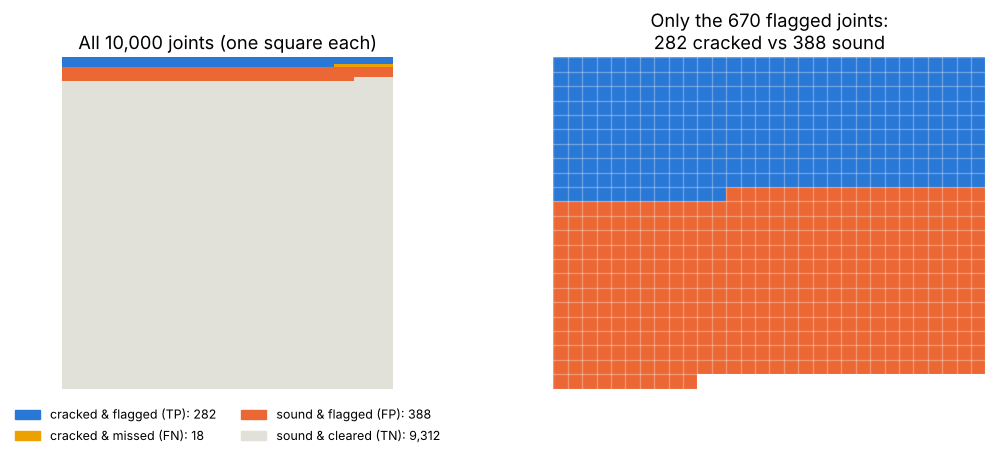

In [3]:
def waffle(ax, groups, ncols, title, gaps=False):
    """Draw one small square per item. `groups` is a list of (label, count, color)."""
    total = int(round(sum(count for _, count, _ in groups)))
    nrows = math.ceil(total / ncols)
    codes = np.zeros(nrows * ncols, dtype=int)          # 0 = empty cell
    start = 0
    for code, (_, count, _) in enumerate(groups, start=1):
        codes[start:start + int(round(count))] = code
        start += int(round(count))
    cmap = ListedColormap(["white"] + [color for _, _, color in groups])
    ax.imshow(codes.reshape(nrows, ncols), cmap=cmap, vmin=0, vmax=len(groups), interpolation="nearest")
    ax.set_title(title)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    if gaps:                                            # thin white lines between the squares
        ax.set_xticks(np.arange(-0.5, ncols, 1), minor=True)
        ax.set_yticks(np.arange(-0.5, nrows, 1), minor=True)
        ax.grid(which="minor", color="white", linewidth=1.0)
        ax.tick_params(which="minor", length=0)
    for side in ax.spines.values():
        side.set_visible(False)


groups_all = [("cracked & flagged (TP)", tp, BLUE), ("cracked & missed (FN)", fn, YELLOW),
              ("sound & flagged (FP)", fp, ORANGE), ("sound & cleared (TN)", tn, LIGHT)]
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), gridspec_kw={"width_ratios": [1.15, 1]})
waffle(axes[0], groups_all, ncols=100, title="All 10,000 joints (one square each)")
waffle(axes[1], [groups_all[0], groups_all[2]], ncols=30, gaps=True,
       title=f"Only the {tp + fp:.0f} flagged joints:\n{tp:.0f} cracked vs {fp:.0f} sound")
axes[0].legend(handles=[Patch(color=c, label=f"{lab}: {n:,.0f}") for lab, n, c in groups_all],
               loc="upper center", bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

Look at the right panel: once you *know* a joint was flagged, the world shrinks to those 670 squares, and the blue ones are a minority. That shrinking is exactly what "conditioning on the evidence" means, and Section 2 turns it into a formula.

> **Key idea.** "94% of cracked joints get flagged" and "94% of flagged joints are cracked" are *different statements about different groups*. The first is a property of the detector. The second also depends on how common cracks are. Confusing them is the single most common error in probabilistic reasoning. Swapping the two conditional probabilities is called the *inverse fallacy*. It goes hand in hand with the **base-rate fallacy**, ignoring how common cracks are, because the base rate is exactly what separates the two numbers.

### 1.3 The road map: from evidence to belief to action

Knowing that joint #217 is cracked with probability 0.42 still does not tell you what to do. Should you close the lane, send an engineer with an ultrasonic probe, or reinforce the joint right away? That depends on what each mistake costs. The whole notebook follows one pipeline:

```
  prior belief  --->  evidence (alarm, test)  --->  posterior belief  --->  + costs  --->  action
     P(H)            likelihoods P(E | H)             P(H | E)              C(a, h)     minimize expected cost
  (base rate)       (the sensor's spec sheet)      (Bayes' rule)       (what mistakes cost)  (decision theory)
```

- Sections 2–4 and 6 build the **belief** half: Bayes' rule, the diagnostic metrics, base rates, combining several alarms.
- Sections 5 and 7 build the **action** half: expected costs, thresholds, capacity limits, decision trees and the value of information.
- Section 8 puts both halves together for a quantity that is a *count* rather than a yes/no hypothesis.

## 2. The probability toolkit

Bayes' rule is not a new axiom. It falls out of three small tools: **conditional probability**, the **multiplication rule** and the **law of total probability**. This section builds them carefully on the bridge example, because every later section is just these three tools used cleverly.

### 2.1 Events and the joint probability table

A **sample space** $\Omega$ lists everything that can happen in one trial. Here a trial is "inspect one joint". An **event** is a set of outcomes we can ask about. We use two events:

- $C$: the joint is cracked (so $\bar C$: the joint is sound).
- $F$: the drone flags the joint (so $\bar F$: no flag).

Probabilities obey a few rules everyone agrees on: $0 \le P(A) \le 1$, $P(\Omega) = 1$, and for events that cannot happen together (disjoint events) $P(A \cup B) = P(A) + P(B)$. Two consequences you will use constantly are $P(\bar A) = 1 - P(A)$ and $P(A \cup B) = P(A) + P(B) - P(A \cap B)$.

With two yes/no events there are exactly four "atoms", and their probabilities form the **joint probability table**. Dividing the counts of Section 1.2 by 10,000:

| | flagged $F$ | not flagged $\bar F$ | row total |
|---|---|---|---|
| cracked $C$ | $P(C \cap F) = 0.0282$ | $P(C \cap \bar F) = 0.0018$ | $P(C) = 0.03$ |
| sound $\bar C$ | $P(\bar C \cap F) = 0.0388$ | $P(\bar C \cap \bar F) = 0.9312$ | $P(\bar C) = 0.97$ |
| column total | $P(F) = 0.067$ | $P(\bar F) = 0.933$ | $1$ |

The four inner numbers add up to 1, and **every question about $C$ and $F$ can be answered from them**. The row and column totals are called **marginal** probabilities because they live in the margins of the table.

### 2.2 Conditional probability: shrink the world, then renormalize

**Definition.** For an event $B$ with $P(B) > 0$,

$$
P(A \mid B) = \frac{P(A \cap B)}{P(B)} .
$$

Read it as: *throw away every outcome where $B$ did not happen, then ask what fraction of the survivors also have $A$.* In counts: (number of cases with $A$ and $B$) divided by (number of cases with $B$). The right panel of the waffle chart was exactly this operation.

For the bridge, both famous conditional probabilities share the same numerator $P(C \cap F) = 0.0282$ but divide by different things:

$$
P(F \mid C) = \frac{P(C \cap F)}{P(C)} = \frac{0.0282}{0.03} = 0.94,
\qquad
P(C \mid F) = \frac{P(C \cap F)}{P(F)} = \frac{0.0282}{0.067} \approx 0.4209 .
$$

One divides by a **row** total (all cracked joints), the other by a **column** total (all flagged joints). That is the entire difference between "the detector catches 94% of cracks" and "a flag means a crack 42% of the time".

Two facts worth checking on the table:

- For a fixed condition, $P(\cdot \mid B)$ is a genuine probability distribution: $P(C \mid F) + P(\bar C \mid F) = 0.4209 + 0.5791 = 1$.
- Swapping what sits on the two sides of the bar gives numbers that need **not** add to 1: $P(F \mid C) + P(F \mid \bar C) = 0.94 + 0.04 = 0.98$. These describe two different groups of joints.

> **Common pitfall.** Treating $P(A \mid B)$ and $P(B \mid A)$ as interchangeable is called the *inverse fallacy* (in courtrooms, the *prosecutor's fallacy*: "the chance of this evidence if the defendant were innocent is 1 in 1,000, so the chance he is innocent is 1 in 1,000"). Nearly every Bayes mistake in exams is this confusion in disguise.

### 2.3 The multiplication rule and the chain rule

Multiply the definition through by $P(B)$ and you get the **multiplication rule**, which works in both directions:

$$
P(A \cap B) = P(B)\,P(A \mid B) = P(A)\,P(B \mid A).
$$

In words: *to get both, get one, then get the other given the first.* Applied repeatedly it becomes the **chain rule**:

$$
P(A_1 \cap A_2 \cap \dots \cap A_n) = P(A_1)\,P(A_2 \mid A_1)\,P(A_3 \mid A_1 \cap A_2) \cdots P(A_n \mid A_1 \cap \dots \cap A_{n-1}).
$$

*Example.* Suppose a flagged joint is then examined with an ultrasonic probe that confirms 93% of real cracks (event $U$). The probability that a random joint is cracked, flagged **and** confirmed is

$$
P(C \cap F \cap U) = P(C)\,P(F \mid C)\,P(U \mid C \cap F) = 0.03 \times 0.94 \times 0.93 = 0.026226 .
$$

We silently used $P(U \mid C \cap F) = P(U \mid C) = 0.93$: once we know the joint is cracked, the probe's chance of confirming it does not depend on what the drone said. This assumption, **conditional independence given the true state**, is what makes multi-sensor reasoning tractable. Section 6 studies it, and what happens when it fails.

### 2.4 The law of total probability

Events $B_1, \dots, B_k$ form a **partition** if exactly one of them happens in every trial (they are mutually exclusive and together cover everything). Then

$$
P(A) = \sum_{i=1}^{k} P(A \mid B_i)\,P(B_i).
$$

*Why it is true:* $A$ splits into the disjoint pieces $A \cap B_1, \dots, A \cap B_k$, so $P(A) = \sum_i P(A \cap B_i)$, and the multiplication rule rewrites each piece as $P(A \mid B_i)\,P(B_i)$. It is a weighted average of the conditional probabilities, weighted by how common each case is.

*Example: where did the 3% come from?* Suppose the joints on the bridge network are 60% steel, 30% concrete and 10% timber, with crack rates of 2%, 4% and 6% respectively. Then

$$
P(C) = 0.02 \times 0.60 + 0.04 \times 0.30 + 0.06 \times 0.10 = 0.012 + 0.012 + 0.006 = 0.030 .
$$

The most important special case uses the partition $\{C, \bar C\}$, and it gives the overall flag rate:

$$
P(F) = P(F \mid C)\,P(C) + P(F \mid \bar C)\,P(\bar C) = 0.94 \times 0.03 + 0.04 \times 0.97 = 0.0282 + 0.0388 = 0.067 .
$$

Remember this number: it is the denominator of Bayes' rule in the next section.

The same table also answers the *reverse* question "given that a joint is cracked, what is it made of?": divide each joint probability by the total.

In [4]:
materials = pd.DataFrame({
    "P(material)": [0.60, 0.30, 0.10],
    "P(crack | material)": [0.02, 0.04, 0.06],
}, index=pd.Index(["steel", "concrete", "timber"], name="material"))
materials["P(crack and material)"] = materials["P(material)"] * materials["P(crack | material)"]
p_crack = materials["P(crack and material)"].sum()                      # law of total probability
materials["P(material | crack)"] = materials["P(crack and material)"] / p_crack
display(materials)
print(f"P(crack) = {p_crack:.3f}   (sum of the third column)")

,P(material),P(crack | material),P(crack and material),P(material | crack)
material,,,,
steel,0.6,0.02,0.012,0.4
concrete,0.3,0.04,0.012,0.4
timber,0.1,0.06,0.006,0.2


P(crack) = 0.030   (sum of the third column)


Timber makes up only 10% of joints but **20%** of the cracked ones, because its crack rate (6%) is twice the network-wide rate (3%): $P(\text{timber} \mid \text{crack}) = P(\text{timber}) \times \frac{P(\text{crack} \mid \text{timber})}{P(\text{crack})} = 0.10 \times \frac{0.06}{0.03} = 0.20$. Steel goes the other way: its 2% rate is two-thirds of the network-wide rate, so its share falls from 60% of the joints to 40% of the cracks. Reversing a conditional probability like this, from $P(\text{crack} \mid \text{material})$ to $P(\text{material} \mid \text{crack})$, *is* Bayes' rule. We just have not given it its name yet.

### 2.5 Independence

Events $A$ and $B$ are **independent** if $P(A \cap B) = P(A)\,P(B)$, which (when $P(B) > 0$) is the same as $P(A \mid B) = P(A)$: learning that $B$ happened does not change the probability of $A$.

The drone's flag and the crack are, thankfully, very **dependent**: $P(F \mid C) = 0.94$ while $P(F) = 0.067$. A detector whose flags were independent of the truth would be useless, since then $P(C \mid F) = P(C)$: the flag would teach you nothing.

> **Common pitfall.** Independent is not the same as *disjoint*. Disjoint events with positive probabilities are as dependent as events can be: if one happens, you know for sure that the other did not.

### 2.6 Checking everything by simulation

Throughout this notebook we will verify each formula by brute force: simulate many random trials with NumPy, then *count*. If a formula and a simulation disagree, one of them is wrong. Here we simulate one million joints (material, then crack, then flag) and compare frequencies with the exact values from Sections 2.2–2.4.

In [5]:
rng_sim = np.random.default_rng(SEED)
n = 1_000_000
p_material = materials["P(material)"].to_numpy()
p_crack_given_material = materials["P(crack | material)"].to_numpy()

mat = rng_sim.choice(3, size=n, p=p_material)                # 0 = steel, 1 = concrete, 2 = timber
cracked = rng_sim.random(n) < p_crack_given_material[mat]    # cracks depend on the material
flagged = np.where(cracked, rng_sim.random(n) < 0.94,        # the drone catches 94% of cracks ...
                   rng_sim.random(n) < 0.04)                 # ... and flags 4% of sound joints

check = pd.DataFrame([
    ("P(cracked)", 0.03, cracked.mean()),
    ("P(timber | cracked)", 0.20, (mat[cracked] == 2).mean()),
    ("P(flagged)", 0.067, flagged.mean()),
    ("P(flagged | cracked)", 0.94, flagged[cracked].mean()),
    ("P(cracked | flagged)", 141 / 335, cracked[flagged].mean()),
], columns=["quantity", "exact", "simulated"]).set_index("quantity")
display(check)

,exact,simulated
quantity,,
P(cracked),0.0300,0.0301
P(timber | cracked),0.2000,0.2029
P(flagged),0.0670,0.0672
P(flagged | cracked),0.9400,0.9400
P(cracked | flagged),0.4209,0.4206


Every simulated frequency lands within a few thousandths of the exact value, the size of fluctuation you expect from a million random trials.

Notice how the conditional probabilities were simulated: `cracked[flagged].mean()` *keeps only the flagged joints* and then averages. Boolean indexing is literally "shrink the world to $B$, then count".

**Quick check.**
1. If the drone flagged *every* joint, what would $P(C \mid F)$ be?
2. In a factory, 30% of parts come from machine X, which produces 5% defects, and the other 70% come from machine Y, which produces 1% defects. What fraction of all parts is defective, and what fraction of defective parts comes from X?
3. Are "the joint is steel" and "the joint is timber" independent?

<details>
<summary>Answer</summary>

1. $P(C \mid F) = P(C) = 0.03$. A flag that is always raised carries no information, so the belief stays at the base rate.
2. $P(D) = 0.05 \times 0.30 + 0.01 \times 0.70 = 0.015 + 0.007 = 0.022$, and $P(X \mid D) = 0.015 / 0.022 \approx 0.682$. Machine X makes only 30% of the parts but about 68% of the defects.
3. No. They are disjoint, so $P(\text{steel} \cap \text{timber}) = 0 \ne 0.6 \times 0.1$. Learning that the joint is steel tells you for certain that it is not timber.
</details>

## 3. Bayes' theorem, four ways

### 3.1 Deriving the theorem

Let $H$ be a hypothesis (the joint is cracked) and $E$ the evidence (the drone flagged it). Write the multiplication rule both ways round:

$$
P(H \cap E) = P(H)\,P(E \mid H) = P(E)\,P(H \mid E).
$$

Divide by $P(E)$, and expand $P(E)$ with the law of total probability over the partition $\{H, \bar H\}$:

$$
\boxed{\;P(H \mid E) = \frac{P(E \mid H)\,P(H)}{P(E)} = \frac{P(E \mid H)\,P(H)}{P(E \mid H)\,P(H) + P(E \mid \bar H)\,P(\bar H)}\;}
$$

That is all of Bayes' theorem. Each ingredient has a name worth memorizing:

| symbol | name | bridge value | what it describes |
|---|---|---|---|
| $P(H)$ | **prior** | $P(C) = 0.03$ | belief before the evidence: the base rate in the population |
| $P(E \mid H)$ | **likelihood** | $P(F \mid C) = 0.94$ | how expected the evidence is *if* $H$ is true: the sensor's hit rate |
| $P(E \mid \bar H)$ | likelihood under the alternative | $P(F \mid \bar C) = 0.04$ | how expected the evidence is if $H$ is false: the false-alarm rate |
| $P(E)$ | **evidence** (marginal likelihood) | $P(F) = 0.067$ | how common the evidence is overall |
| $P(H \mid E)$ | **posterior** | $P(C \mid F) \approx 0.4209$ | belief after the evidence |

In one breath: **posterior = likelihood × prior / evidence.** The numerator says how well $H$ explains what we saw *and* how plausible $H$ was to begin with. The denominator is the same expression summed over every competing hypothesis, which rescales the result so the posteriors add up to 1.

With more than two hypotheses $H_1, \dots, H_k$ forming a partition, nothing changes except the sum:

$$
P(H_i \mid E) = \frac{P(E \mid H_i)\,P(H_i)}{\sum_{j=1}^{k} P(E \mid H_j)\,P(H_j)} .
$$

Section 8 uses this version with five hypotheses at once. Below are four ways to *compute* the same posterior. They are mathematically identical, but each one makes a different aspect easy to see.

### 3.2 Form 1: plug into the formula

In [6]:
def bayes_posterior(prior, p_e_given_h, p_e_given_not_h):
    """P(H | E) for a binary hypothesis, from the prior and the two likelihoods."""
    numerator = p_e_given_h * prior
    return numerator / (numerator + p_e_given_not_h * (1 - prior))


post_float = bayes_posterior(0.03, 0.94, 0.04)
post_exact = bayes_posterior(Fraction(3, 100), Fraction(94, 100), Fraction(4, 100))   # exact arithmetic
print(f"P(cracked | flagged) = {post_float:.6f}   (exactly {post_exact})")

P(cracked | flagged) = 0.420896   (exactly 141/335)


Python's `Fraction` type does exact rational arithmetic, which is handy for checking hand calculations: the posterior is exactly $141/335$.

### 3.3 Form 2: natural frequencies

The recipe from Section 1.2, written as a general method:

1. Pick a large round population, say $N = 10{,}000$.
2. Split it by the **prior**: $300$ cracked, $9{,}700$ sound.
3. Split each group by the **likelihoods**: $282 / 18$ and $388 / 9{,}312$.
4. Keep only the column that matches the **evidence** you actually observed, and read off the fraction.

| | flagged | not flagged | total |
|---|---|---|---|
| cracked | **282** | 18 | 300 |
| sound | **388** | 9,312 | 9,700 |
| total | **670** | 9,330 | 10,000 |

$$
P(C \mid F) = \frac{282}{282 + 388} = \frac{282}{670} \approx 0.4209 .
$$

Experiments in cognitive psychology (Gigerenzer and Hoffrage, 1995) found that people solve this kind of problem far more accurately when it is phrased in natural frequencies than in conditional probabilities. Nothing is lost by thinking this way: the counts are just probabilities multiplied by $N$, so they may even be fractional ("expected counts").

> **Olympiad tip.** When a Bayes question feels slippery, draw the 2×2 table of counts for an imaginary population. Choose $N$ so the counts come out as whole numbers. The FPR multiplies the **negative row**, the sensitivity multiplies the **positive row**, and the answer lives in a **column**.

### 3.4 Form 3: odds and likelihood ratios

The **odds** of an event are $O(H) = P(H) / P(\bar H) = p / (1-p)$, and you convert back with $p = O / (1 + O)$. Probability $0.5$ is odds $1$ ("1 to 1"), probability $0.2$ is odds $0.25$ ("1 to 4"), and the bridge prior $0.03$ is odds $3/97 \approx 0.0309$.

Write Bayes' theorem for $H$ and for $\bar H$ and divide one by the other. The awkward denominator $P(E)$ cancels:

$$
\underbrace{\frac{P(H \mid E)}{P(\bar H \mid E)}}_{\text{posterior odds}}
= \underbrace{\frac{P(H)}{P(\bar H)}}_{\text{prior odds}} \times \underbrace{\frac{P(E \mid H)}{P(E \mid \bar H)}}_{\text{likelihood ratio } \Lambda(E)} .
$$

The **likelihood ratio** (LR) measures the strength of the evidence: how many times more likely the evidence is under $H$ than under $\bar H$. For a test with sensitivity $s$ and specificity $c$ there is one LR per possible result:

$$
\Lambda_{+} = \frac{P(+ \mid H)}{P(+ \mid \bar H)} = \frac{s}{1 - c}, \qquad
\Lambda_{-} = \frac{P(- \mid H)}{P(- \mid \bar H)} = \frac{1 - s}{c} .
$$

For the drone, $\Lambda_+ = 0.94 / 0.04 = 23.5$: a flag is 23.5 times more likely to come from a cracked joint than from a sound one. Then

$$
O(C \mid F) = \frac{3}{97} \times 23.5 = \frac{70.5}{97} \approx 0.7268,
\qquad
P(C \mid F) = \frac{0.7268}{1 + 0.7268} \approx 0.4209 .
$$

The odds form cleanly separates the **population** (prior odds) from the **sensor** (likelihood ratio). Move the same drone to an older bridge where 10% of joints are cracked and only the prior changes: $O = (1/9) \times 23.5 \approx 2.611$, so $P \approx 0.723$.

In [7]:
def to_odds(p):
    return p / (1 - p)


def from_odds(o):
    return o / (1 + o)


lr_pos = 0.94 / 0.04          # Λ+ = sensitivity / false-positive rate
lr_neg = 0.06 / 0.96          # Λ- = miss rate / specificity
for bridge, prior in [("this bridge (3% cracked)", 0.03), ("older bridge (10% cracked)", 0.10)]:
    post_odds = to_odds(prior) * lr_pos
    print(f"{bridge:<27s} prior odds {to_odds(prior):.4f} x LR {lr_pos:.1f} = {post_odds:.4f}"
          f"  ->  P(cracked | flag) = {from_odds(post_odds):.4f}")

this bridge (3% cracked)    prior odds 0.0309 x LR 23.5 = 0.7268  ->  P(cracked | flag) = 0.4209
older bridge (10% cracked)  prior odds 0.1111 x LR 23.5 = 2.6111  ->  P(cracked | flag) = 0.7231


### 3.5 Form 4: log-odds, where evidence adds up

Take the logarithm of the odds form. Products become sums:

$$
\operatorname{logit} P(H \mid E) = \operatorname{logit} P(H) + \ln \Lambda(E),
\qquad \text{where } \operatorname{logit}(p) = \ln \frac{p}{1-p} .
$$

The inverse of the logit is the **sigmoid** $\sigma(z) = 1/(1 + e^{-z})$, the same function that sits at the end of a logistic regression. For the bridge:

$$
\underbrace{\ln\tfrac{3}{97}}_{-3.476} + \underbrace{\ln 23.5}_{+3.157} = -0.319,
\qquad \sigma(-0.319) \approx 0.4209 .
$$

Measured in **bits** (base-2 logarithms), the prior sits at $\log_2(3/97) \approx -5.01$ bits and the flag contributes $\log_2 23.5 \approx +4.55$ bits of evidence. Not quite enough to climb above zero, which is why the posterior stays below one half.

This additive picture is how you should *think* about evidence: every observation pushes the log-odds up or down by a fixed amount, its log-likelihood ratio, no matter where you start. In probability units the same push looks very different at different starting points, as the plot below shows.

> **Going deeper.** Logistic regression models $\operatorname{logit} P(y=1 \mid \mathbf{x}) = b + \mathbf{w}^\top \mathbf{x}$: an intercept that plays the role of the prior log-odds plus a sum of evidence terms $w_j x_j$. When the features are conditionally independent given the class and each class-conditional distribution belongs to a common exponential family (for example Gaussians with a shared variance, or Bernoulli features), the exact Bayes posterior has precisely this form. That is one reason logistic regression is such a natural model.

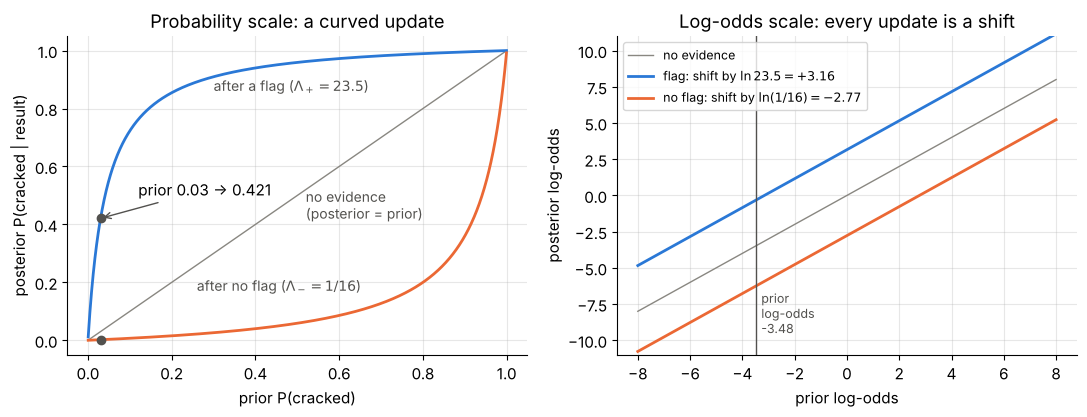

In [8]:
grid_p = np.linspace(0.0005, 0.9995, 1000)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))

ax = axes[0]
ax.plot(grid_p, grid_p, color=MUTED, lw=1)
ax.plot(grid_p, from_odds(to_odds(grid_p) * lr_pos), lw=2, color=BLUE)
ax.plot(grid_p, from_odds(to_odds(grid_p) * lr_neg), lw=2, color=ORANGE)
ax.plot([0.03, 0.03], [from_odds(to_odds(0.03) * lr_neg), from_odds(to_odds(0.03) * lr_pos)], "o", color=INK2, ms=6)
ax.annotate("prior 0.03 -> 0.421", xy=(0.03, 0.4209), xytext=(0.12, 0.50), arrowprops=dict(arrowstyle="->", color=INK2))
# direct labels next to each curve instead of a legend box
ax.text(0.30, 0.86, r"after a flag ($\Lambda_+ = 23.5$)", color=INK2, fontsize=10)
ax.text(0.52, 0.42, "no evidence\n(posterior = prior)", color=INK2, fontsize=10, ha="left")
ax.text(0.26, 0.17, r"after no flag ($\Lambda_- = 1/16$)", color=INK2, fontsize=10)
ax.set(xlabel="prior P(cracked)", ylabel="posterior P(cracked | result)", title="Probability scale: a curved update")

ax = axes[1]
z = np.linspace(-8, 8, 200)
ax.plot(z, z, color=MUTED, lw=1, label="no evidence")
ax.plot(z, z + np.log(lr_pos), lw=2, color=BLUE, label=r"flag: shift by $\ln 23.5 = +3.16$")
ax.plot(z, z + np.log(lr_neg), lw=2, color=ORANGE, label=r"no flag: shift by $\ln(1/16) = -2.77$")
ax.axvline(special.logit(0.03), color=INK2, lw=1)
ax.text(special.logit(0.03) + 0.2, -9.5, "prior\nlog-odds\n-3.48", color=INK2, fontsize=9)
ax.set(xlabel="prior log-odds", ylabel="posterior log-odds", title="Log-odds scale: every update is a shift", ylim=(-11, 11))
ax.legend(loc="upper left", fontsize=9)
plt.tight_layout()
plt.show()

On the left, the same flag lifts a prior of 0.03 to 0.42, but a prior of 0.5 only to 0.96: in probability units the effect of evidence depends on where you start. On the right, the identical update is a **constant vertical shift** of $+3.16$ (flag) or $-2.77$ (no flag). The likelihood ratio is the sensor's fingerprint, and the prior decides where on the curve you sit.

### 3.6 Silence is evidence too

What if the drone does **not** flag a joint? Use $\Lambda_- = (1 - 0.94) / 0.96 = 0.0625 = 1/16$:

$$
O(C \mid \bar F) = \frac{3}{97} \times \frac{1}{16} = \frac{3}{1552},
\qquad
P(C \mid \bar F) = \frac{3}{1555} \approx 0.00193 .
$$

An unflagged joint is about 15 times less likely to be cracked than a random joint (0.19% instead of 3%). Equivalently, the probability that an unflagged joint is sound, the *negative predictive value*, is $1 - 0.00193 = 0.99807$.

### 3.7 Updating in sequence: today's posterior is tomorrow's prior

Suppose the drone makes a **second pass** from a different angle, and the two passes make errors independently once the true state of the joint is fixed (conditional independence). Each pass multiplies the odds by its own likelihood ratio:

| evidence | odds | probability |
|---|---|---|
| none (prior) | $3/97 = 0.0309$ | $0.0300$ |
| flag | $0.0309 \times 23.5 = 0.7268$ | $0.4209$ |
| flag, flag | $0.0309 \times 23.5^2 = 17.08$ | $0.9447$ |
| flag, no flag | $0.0309 \times 23.5 \times \tfrac{1}{16} = 0.0454$ | $0.0435$ |

Three facts follow directly from multiplication:

- **Order does not matter.** "Flag then no flag" and "no flag then flag" give the same posterior.
- **Batch equals sequential.** Updating on both passes at once gives the same answer as updating on the first and then using that posterior as the prior for the second.
- **The evidence must be new.** Re-running the *same* image through the *same* model twice is not two independent passes. It repeats one piece of evidence. Section 6.6 shows how badly double counting can mislead.

In [9]:
# Monte Carlo check of sequential updating: two passes with conditionally independent errors.
rng_mc = np.random.default_rng(SEED + 1)
n = 1_000_000
crack = rng_mc.random(n) < 0.03
pass1 = np.where(crack, rng_mc.random(n) < 0.94, rng_mc.random(n) < 0.04)
pass2 = np.where(crack, rng_mc.random(n) < 0.94, rng_mc.random(n) < 0.04)   # fresh, independent errors

rows = []
for label, mask, lrs in [("flag", pass1, [lr_pos]),
                         ("flag, flag", pass1 & pass2, [lr_pos, lr_pos]),
                         ("flag, no flag", pass1 & ~pass2, [lr_pos, lr_neg]),
                         ("no flag, flag", ~pass1 & pass2, [lr_neg, lr_pos]),
                         ("no flag, no flag", ~pass1 & ~pass2, [lr_neg, lr_neg])]:
    exact = from_odds(to_odds(0.03) * np.prod(lrs))
    rows.append((label, int(mask.sum()), exact, crack[mask].mean()))
display(pd.DataFrame(rows, columns=["evidence", "joints", "exact posterior", "simulated"]).set_index("evidence"))

,joints,exact posterior,simulated
evidence,,,
flag,66706,0.4209,0.4183
"flag, flag",27785,0.9447,0.9448
"flag, no flag",38921,0.0435,0.0423
"no flag, flag",38791,0.0435,0.0445
"no flag, no flag",894503,0.0001,0.0001


The simulation agrees with the odds calculation in every row, including the symmetric pair "flag, no flag" and "no flag, flag".

> **Common pitfall.** Four classic Bayes errors, each of which appears among the quiz distractors in Section 9:
> 1. *Prior neglect* (the base-rate fallacy): answering $0.94/(0.94 + 0.04) \approx 0.959$, which is the posterior only when the prior is exactly 50%.
> 2. *Inverse fallacy:* reporting the likelihood $P(F \mid C) = 0.94$ as the posterior $P(C \mid F)$.
> 3. *Reading a likelihood ratio as a probability:* "LR = 23.5, so it is 23.5 times more likely to be cracked" (true for the *odds* versus the prior odds, not for the probability).
> 4. *Double counting:* multiplying in the same evidence twice.

✏️ **Exercise 1: posterior after a binary test.** Implement `posterior_after_test(prior, sens, spec, positive)`, returning $P(H \mid \text{result})$ for a test with the given sensitivity and specificity, where `positive` says whether the result was positive. It must work when `prior` is a NumPy array, including the edge cases `prior = 0` and `prior = 1` (careful: the odds $p/(1-p)$ are infinite at $p = 1$).

In [10]:
# ✏️ Exercise 1: posterior after a binary test
def posterior_after_test(prior, sens, spec, positive=True):
    """Return P(H | test result). `prior` may be a float or a NumPy array."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    out = posterior_after_test(0.03, 0.94, 0.96, positive=True)
    assert np.isclose(out, 141 / 335), f"flagged joint: expected 0.42090, got {out}"
    out = posterior_after_test(0.03, 0.94, 0.96, positive=False)
    assert np.isclose(out, 3 / 1555), f"unflagged joint: expected 0.0019293, got {out}"
    out = posterior_after_test(np.array([0.01, 0.5]), 0.9, 0.8, positive=True)
    assert np.allclose(out, [0.009 / 0.207, 0.45 / 0.55]), f"vectorized priors: got {out}"
    out = posterior_after_test(np.array([0.0, 1.0]), 0.9, 0.8, positive=True)
    assert np.allclose(out, [0.0, 1.0]), f"edge cases: priors of exactly 0 and 1 must stay 0 and 1, got {out}"
    out = posterior_after_test(0.2, 0.7, 0.9, positive=False)
    assert np.isclose(out, 0.06 / 0.78), f"negative result: got {out}"


run_check("Exercise 1", _test)

⏳ Exercise 1: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def posterior_after_test(prior, sens, spec, positive=True):
    prior = np.asarray(prior, dtype=float)
    if positive:
        numerator = sens * prior                         # P(+ | H) P(H)
        denominator = numerator + (1 - spec) * (1 - prior)   # + P(+ | not H) P(not H)
    else:
        numerator = (1 - sens) * prior                   # P(- | H) P(H)
        denominator = numerator + spec * (1 - prior)         # + P(- | not H) P(not H)
    return numerator / denominator
```
A negative result uses the *miss rate* $1 - s$ for $H$ and the *specificity* $c$ for $\bar H$, and mixing these up is the most common bug. Because this form never divides by $1 - p$, it also handles the priors 0 and 1 without special cases. The odds form needs one at $p = 1$.
</details>

✏️ **Exercise 2: evidence in log-odds.** Implement `likelihood_ratios(sens, spec)`, returning the pair $(\Lambda_+, \Lambda_-)$, and `posterior_from_lrs(prior, lrs)`, which combines a prior with any list of likelihood ratios from conditionally independent observations. Work in log-odds so that thousands of observations neither overflow nor underflow. (Hint: `math.log1p`, `np.log` and `special.expit` are your friends.)

In [11]:
# ✏️ Exercise 2: evidence in log-odds
def likelihood_ratios(sens, spec):
    """Return (LR for a positive result, LR for a negative result)."""
    # YOUR CODE HERE
    raise NotImplementedError


def posterior_from_lrs(prior, lrs):
    """Combine a prior probability with a list of likelihood ratios, and return the posterior probability."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    lp, ln = likelihood_ratios(0.94, 0.96)
    assert np.isclose(lp, 23.5) and np.isclose(ln, 0.0625), f"likelihood_ratios(0.94, 0.96) gave {(lp, ln)}"
    assert np.isclose(posterior_from_lrs(0.03, [23.5]), 141 / 335), "one flag on the bridge joint"
    assert np.isclose(posterior_from_lrs(0.03, [23.5, 23.5]), 0.94468995), "two independent flags"
    assert np.isclose(posterior_from_lrs(0.03, [23.5, 0.0625]),
                      posterior_from_lrs(0.03, [0.0625, 23.5])), "order must not matter"
    assert np.isclose(posterior_from_lrs(0.4, []), 0.4), "no evidence -> posterior equals prior"
    hi, lo = posterior_from_lrs(0.5, [1.5] * 3000), posterior_from_lrs(0.5, [0.5] * 3000)
    assert np.isfinite(hi) and np.isfinite(lo) and hi > 0.999999 and lo < 1e-6, \
        f"long evidence lists must not overflow: got {hi}, {lo}"


run_check("Exercise 2", _test)

⏳ Exercise 2: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def likelihood_ratios(sens, spec):
    return sens / (1 - spec), (1 - sens) / spec

def posterior_from_lrs(prior, lrs):
    log_odds = math.log(prior) - math.log1p(-prior)                  # logit of the prior
    log_odds += float(np.sum(np.log(np.asarray(lrs, dtype=float))))  # add each log-LR
    return float(special.expit(log_odds))                           # stable sigmoid
```
Multiplying 3,000 likelihood ratios of 1.5 directly gives $1.5^{3000} \approx 10^{528}$, which overflows a float. Adding logarithms keeps every intermediate number small, and `special.expit` evaluates the sigmoid without overflow at either end.
</details>

**Quick check.**
1. A test has sensitivity 0.80 and specificity 0.95. What are its likelihood ratios $\Lambda_+$ and $\Lambda_-$?
2. The prior odds are 1 to 4, and that test comes back positive. What are the posterior odds and the posterior probability?
3. How much does the positive result add on the log-odds scale, in natural units and in bits?

<details>
<summary>Answer</summary>

1. $\Lambda_+ = 0.80 / 0.05 = 16$ and $\Lambda_- = 0.20 / 0.95 \approx 0.211$.
2. Posterior odds $= 0.25 \times 16 = 4$ ("4 to 1"), so $P = 4/5 = 0.8$.
3. $\ln 16 \approx 2.77$, or exactly $\log_2 16 = 4$ bits.
</details>

## 4. Diagnostic metrics and the base-rate fallacy

Machine-learning papers, medical tests and alarm systems all describe their errors with the same small vocabulary. It looks like a zoo of names, but there are really only two families, and Bayes' rule is the bridge between them.

### 4.1 The confusion matrix and its two families of rates

Cross the truth $y$ (1 = positive, e.g. cracked) with the alarm $\hat y$ (1 = alarm raised) and count:

| | alarm ($\hat y = 1$) | no alarm ($\hat y = 0$) | row total |
|---|---|---|---|
| **positive** ($y = 1$) | TP (true positive) | FN (false negative) | TP + FN |
| **negative** ($y = 0$) | FP (false positive) | TN (true negative) | FP + TN |
| column total | TP + FP | FN + TN | $n$ |

**Family 1: divide by a row total** (condition on the *truth*). These describe the detector itself:

| metric | formula | as a probability | other names |
|---|---|---|---|
| sensitivity | $\frac{TP}{TP + FN}$ | $P(\hat y = 1 \mid y = 1)$ | recall, true positive rate (TPR), hit rate |
| false negative rate (FNR) | $\frac{FN}{TP + FN}$ | $P(\hat y = 0 \mid y = 1)$ | miss rate, which equals $1 -$ sensitivity |
| specificity | $\frac{TN}{FP + TN}$ | $P(\hat y = 0 \mid y = 0)$ | true negative rate (TNR) |
| false positive rate (FPR) | $\frac{FP}{FP + TN}$ | $P(\hat y = 1 \mid y = 0)$ | false-alarm rate, fall-out, which equals $1 -$ specificity |

**Family 2: divide by a column total** (condition on the *alarm*). These describe what an alarm, or its absence, means:

| metric | formula | as a probability | other names |
|---|---|---|---|
| positive predictive value (PPV) | $\frac{TP}{TP + FP}$ | $P(y = 1 \mid \hat y = 1)$ | precision |
| false discovery rate (FDR) | $\frac{FP}{TP + FP}$ | $P(y = 0 \mid \hat y = 1)$ | equals $1 -$ PPV |
| negative predictive value (NPV) | $\frac{TN}{TN + FN}$ | $P(y = 0 \mid \hat y = 0)$ | |
| false omission rate (FOR) | $\frac{FN}{TN + FN}$ | $P(y = 1 \mid \hat y = 0)$ | equals $1 -$ NPV |

Two more numbers use the whole table: the **prevalence** $\pi = (TP + FN)/n = P(y = 1)$, and the **accuracy** $(TP + TN)/n$.

> **Key idea.** Family 1 rates are **likelihoods**: they look *backwards* from the truth to the alarm, and they are properties of the detector. Family 2 rates are **posteriors**: they look *forwards* from the alarm to the truth, and they also depend on the prevalence. Bayes' rule turns Family 1 plus the prevalence into Family 2.

In [12]:
def metrics_table(tp, fn, fp, tn):
    """All the standard rates of a 2x2 confusion matrix, as a one-column DataFrame."""
    n = tp + fn + fp + tn
    rows = {
        "prevalence": (tp + fn) / n,
        "sensitivity (recall, TPR)": tp / (tp + fn),
        "false negative rate (FNR)": fn / (tp + fn),
        "specificity (TNR)": tn / (fp + tn),
        "false positive rate (FPR)": fp / (fp + tn),
        "PPV (precision)": tp / (tp + fp),
        "NPV": tn / (tn + fn),
        "accuracy": (tp + tn) / n,
    }
    return pd.DataFrame({"value": rows})


display(metrics_table(tp=282, fn=18, fp=388, tn=9312))      # the bridge joints of Section 1

,value
prevalence,0.0300
"sensitivity (recall, TPR)",0.9400
false negative rate (FNR),0.0600
specificity (TNR),0.9600
false positive rate (FPR),0.0400
PPV (precision),0.4209
NPV,0.9981
accuracy,0.9594


✏️ **Exercise 3: the confusion-matrix zoo.** Implement `diagnostic_metrics(tp, fn, fp, tn)` returning a dictionary with the keys `"prevalence"`, `"sensitivity"`, `"specificity"`, `"fpr"`, `"fnr"`, `"ppv"`, `"npv"` and `"accuracy"`. (Yes, the cell above does this. Write it yourself from the definitions without peeking.)

In [13]:
# ✏️ Exercise 3: the confusion-matrix zoo
def diagnostic_metrics(tp, fn, fp, tn):
    """Return a dict with prevalence, sensitivity, specificity, fpr, fnr, ppv, npv, accuracy."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    m = diagnostic_metrics(282, 18, 388, 9312)
    want = {"prevalence": 0.03, "sensitivity": 0.94, "specificity": 0.96, "fpr": 0.04, "fnr": 0.06,
            "ppv": 282 / 670, "npv": 9312 / 9330, "accuracy": 0.9594}
    for k, v in want.items():
        assert k in m, f"missing key '{k}'"
        assert np.isclose(m[k], v), f"{k}: expected {v:.6f}, got {m[k]}"
    m = diagnostic_metrics(40, 10, 30, 920)
    assert np.isclose(m["ppv"], 40 / 70) and np.isclose(m["specificity"], 920 / 950), "second table is wrong"


run_check("Exercise 3", _test)

⏳ Exercise 3: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def diagnostic_metrics(tp, fn, fp, tn):
    n = tp + fn + fp + tn
    return {"prevalence": (tp + fn) / n,
            "sensitivity": tp / (tp + fn), "fnr": fn / (tp + fn),    # divide by the positive row
            "specificity": tn / (tn + fp), "fpr": fp / (tn + fp),    # divide by the negative row
            "ppv": tp / (tp + fp), "npv": tn / (tn + fn),            # divide by a column
            "accuracy": (tp + tn) / n}
```
Every rate is "a cell divided by the total of its row or of its column". Decide which group you are talking about, and the denominator follows.
</details>

### 4.2 PPV and NPV from sensitivity, specificity and prevalence

Write $s$ for sensitivity, $c$ for specificity and $\pi$ for prevalence. Bayes' rule with "alarm" (or "no alarm") as the evidence gives

$$
\text{PPV} = \frac{s\,\pi}{s\,\pi + (1 - c)(1 - \pi)},
\qquad
\text{NPV} = \frac{c\,(1 - \pi)}{c\,(1 - \pi) + (1 - s)\,\pi} .
$$

Sensitivity and specificity appear here as *inputs*, and the prevalence decides how they combine. In odds form, $\text{PPV}/(1 - \text{PPV}) = \frac{\pi}{1 - \pi} \times \Lambda_+$. When the positive class is rare and $\pi \Lambda_+$ is small, this gives a handy rule of thumb:

$$
\text{PPV} \approx \pi \times \Lambda_+ \qquad (\text{rare events}),
$$

so a detector with $\Lambda_+ = 20$ looking for something that occurs once in a thousand cases has a precision of only about 2%.

### 4.3 Precision collapses as the base rate falls

The next cell plots PPV against prevalence for four detectors. The prevalence axis is logarithmic because the interesting action happens between one in ten thousand and one in ten.

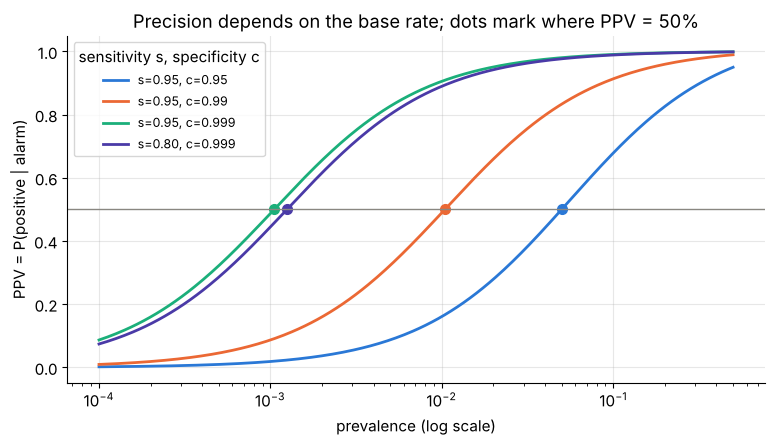

,PPV @ 0.01%,PPV @ 0.1%,PPV @ 1%,PPV @ 10%,PPV @ 50%,prevalence for PPV = 50%
"s=0.95, c=0.95",0.0019,0.0187,0.1610,0.6786,0.9500,0.0500
"s=0.95, c=0.99",0.0094,0.0868,0.4897,0.9135,0.9896,0.0104
"s=0.95, c=0.999",0.0868,0.4874,0.9056,0.9906,0.9989,0.0011
"s=0.80, c=0.999",0.0741,0.4447,0.8899,0.9889,0.9988,0.0012


In [14]:
def ppv_from_rates(prev, sens, spec):
    return sens * prev / (sens * prev + (1 - spec) * (1 - prev))


detectors = {"s=0.95, c=0.95": (0.95, 0.95), "s=0.95, c=0.99": (0.95, 0.99),
             "s=0.95, c=0.999": (0.95, 0.999), "s=0.80, c=0.999": (0.80, 0.999)}
prev_grid = np.logspace(-4, np.log10(0.5), 300)

fig, ax = plt.subplots(figsize=(9, 4.5))
for (name, (s, c)), color in zip(detectors.items(), [BLUE, ORANGE, AQUA, VIOLET]):
    ax.plot(prev_grid, ppv_from_rates(prev_grid, s, c), lw=2, color=color, label=name)
    pi_half = (1 - c) / (s + 1 - c)                       # prevalence where PPV = 50% (TP = FP)
    ax.plot(pi_half, 0.5, "o", color=color, ms=7)
ax.axhline(0.5, color=MUTED, lw=1)
ax.set_xscale("log")
ax.set(xlabel="prevalence (log scale)", ylabel="PPV = P(positive | alarm)",
       title="Precision depends on the base rate, and dots mark where PPV = 50%")
ax.legend(title="sensitivity s, specificity c", fontsize=9, loc="upper left")
plt.show()

table = pd.DataFrame({name: [ppv_from_rates(p, s, c) for p in (1e-4, 1e-3, 1e-2, 0.1, 0.5)]
                      + [(1 - c) / (s + 1 - c)] for name, (s, c) in detectors.items()},
                     index=["PPV @ 0.01%", "PPV @ 0.1%", "PPV @ 1%", "PPV @ 10%", "PPV @ 50%", "prevalence for PPV = 50%"]).T
display(table.round(4))

Read the table row by row:

- A "95% sensitive, 95% specific" detector, which sounds excellent, has a precision of about **16%** at 1% prevalence and below **2%** at 0.1%.
- PPV crosses 50% exactly when true positives equal false positives, $s\,\pi = (1-c)(1-\pi)$, that is at $\pi_{1/2} = (1-c)/(s + 1 - c)$.
- For rare events, **specificity dominates**. Improving specificity from 0.99 to 0.999 moves $\pi_{1/2}$ tenfold (from 1.04% to 0.105%), while cutting sensitivity from 0.95 to 0.80 barely matters (0.105% to 0.125%). The false-positive rate multiplies the huge negative group, so that is where the leverage is.

### 4.4 The accuracy paradox

Accuracy is a prevalence-weighted average of the two Family 1 rates:

$$
\text{accuracy} = s\,\pi + c\,(1 - \pi).
$$

When positives are rare, it is almost entirely specificity. A "detector" that **never** raises an alarm has accuracy $1 - \pi$, which is 99% at 1% prevalence. The bridge drone has accuracy $0.03 \times 0.94 + 0.97 \times 0.96 = 0.9594$, *lower* than the 0.97 of a drone that never flags anything, yet the drone finds 94% of the cracks and the do-nothing drone finds none.

> **Common pitfall.** Accuracy counts mistakes but does not *weigh* them. Missing a cracked joint and closing a sound one are counted as equally bad, which they are not. Section 5 replaces accuracy with expected **cost**.

✏️ **Exercise 4: PPV, NPV and the prevalence you need.** Implement `ppv_npv(prevalence, sens, spec)` (returning the pair PPV, NPV and working with NumPy arrays) and `prevalence_for_ppv(target, sens, spec)`, the smallest prevalence at which PPV reaches `target`. Derive the second formula by solving $\text{PPV}(\pi) = t$ for $\pi$.

In [15]:
# ✏️ Exercise 4: PPV, NPV and the prevalence you need
def ppv_npv(prevalence, sens, spec):
    """Return (PPV, NPV). `prevalence` may be a float or a NumPy array."""
    # YOUR CODE HERE
    raise NotImplementedError


def prevalence_for_ppv(target, sens, spec):
    """Smallest prevalence at which the PPV equals `target`."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    ppv, npv = ppv_npv(0.03, 0.94, 0.96)
    assert np.isclose(ppv, 141 / 335) and np.isclose(npv, 9312 / 9330), f"bridge: got {(ppv, npv)}"
    ppv, npv = ppv_npv(np.array([0.001, 0.5]), 0.95, 0.99)
    assert np.allclose(ppv, [0.08683729, 0.95 / 0.96]), f"vectorized PPV: got {ppv}"
    assert np.isclose(prevalence_for_ppv(0.5, 0.95, 0.95), 0.05), "PPV = 50% for a 95%/95% detector"
    pi = prevalence_for_ppv(0.9, 0.94, 0.96)
    assert np.isclose(pi, 0.036 / 0.13), f"PPV = 90% for the drone: got {pi}"
    assert np.isclose(ppv_npv(pi, 0.94, 0.96)[0], 0.9), "plugging the answer back in must give PPV = 0.9"


run_check("Exercise 4", _test)

⏳ Exercise 4: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def ppv_npv(prevalence, sens, spec):
    pi = np.asarray(prevalence, dtype=float)
    ppv = sens * pi / (sens * pi + (1 - spec) * (1 - pi))
    npv = spec * (1 - pi) / (spec * (1 - pi) + (1 - sens) * pi)
    return ppv, npv

def prevalence_for_ppv(target, sens, spec):
    fpr = 1 - spec
    return target * fpr / (sens * (1 - target) + target * fpr)
```
From $s\pi = t\,[s\pi + f(1-\pi)]$ with $f = 1 - c$: $\;s\pi(1-t) = t f (1 - \pi)$, so $\pi\,[s(1-t) + t f] = t f$. For the drone to be right 90% of the time when it flags, cracks would have to affect about 27.7% of joints.
</details>

### 4.5 Balanced validation sets: what transfers to deployment and what does not

Here is a situation every ML engineer meets. A solar-farm operator wants a detector for **hot-spot defects** in panels, using features extracted from drone thermal images. In the field only about **1%** of panels are defective. With so few positives, a random sample would contain hardly any defects, so the team deliberately builds **balanced** datasets: 2,000 defective plus 2,000 healthy panels for training, and 1,000 plus 1,000 for validation. That is a sensible choice, but it changes which validation numbers can be trusted.

The key assumption is called **prior shift** (or label shift): the way each class *looks*, the class-conditional distribution $p(\mathbf{x} \mid y)$, is the same in the validation set and in the field. Only the class proportions $P(y)$ differ. Under that assumption:

- Family 1 rates (sensitivity, specificity, FPR, FNR, and the whole ROC curve) are computed *within* a class, so they **transfer** unchanged.
- Family 2 rates (PPV, NPV) and anything else that mixes the classes (accuracy, F1) inherit the validation set's 50% prevalence, so they **do not transfer**.

Let's watch this happen. Each panel gets two standardized thermal features (think "peak temperature excess" and "hot-spot contrast"). Healthy and defective panels have Gaussian feature distributions with different means. We train a logistic regression on the balanced training set, use the usual threshold of 0.5, and evaluate on the balanced validation set and on 200,000 field panels.

In [16]:
rng_solar = np.random.default_rng(SEED)
MU_HEALTHY, MU_DEFECT = np.array([0.0, 0.0]), np.array([1.8, 1.4])
COV = np.array([[1.0, 0.3], [0.3, 1.0]])
CHOL = np.linalg.cholesky(COV)


def panels_balanced(n_per_class, rng):
    """n_per_class healthy (y=0) followed by n_per_class defective (y=1) panels."""
    y = np.r_[np.zeros(n_per_class, int), np.ones(n_per_class, int)]
    x = rng.standard_normal((2 * n_per_class, 2)) @ CHOL.T + np.where(y[:, None] == 1, MU_DEFECT, MU_HEALTHY)
    return x, y


def panels_field(n, prevalence, rng):
    """n panels as they occur in the field: each is defective with probability `prevalence`."""
    y = (rng.random(n) < prevalence).astype(int)
    x = rng.standard_normal((n, 2)) @ CHOL.T + np.where(y[:, None] == 1, MU_DEFECT, MU_HEALTHY)
    return x, y


X_train, y_train = panels_balanced(2000, rng_solar)
X_val, y_val = panels_balanced(1000, rng_solar)
X_field, y_field = panels_field(200_000, 0.01, rng_solar)

model = LogisticRegression(C=100.0).fit(X_train, y_train)   # large C = almost no regularization
p_val = model.predict_proba(X_val)[:, 1]
p_field = model.predict_proba(X_field)[:, 1]


def rates(y, alarm):
    tp = np.sum((y == 1) & alarm); fn = np.sum((y == 1) & ~alarm)
    fp = np.sum((y == 0) & alarm); tn = np.sum((y == 0) & ~alarm)
    return {"prevalence": (tp + fn) / len(y), "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
            "PPV": tp / (tp + fp), "NPV": tn / (tn + fn), "accuracy": (tp + tn) / len(y)}


solar = pd.DataFrame({"balanced validation": rates(y_val, p_val > 0.5),
                      "field (1% defective)": rates(y_field, p_field > 0.5)})
display(solar.round(4))
v = solar["balanced validation"]
print(f"Bayes' prediction of field PPV from validation sens/spec: "
      f"{ppv_from_rates(0.01, v['sensitivity'], v['specificity']):.4f}")

,balanced validation,field (1% defective)
prevalence,0.5000,0.0103
sensitivity,0.8410,0.8399
specificity,0.8400,0.8430
PPV,0.8402,0.0526
NPV,0.8408,0.9980
accuracy,0.8405,0.8430


Bayes' prediction of field PPV from validation sens/spec: 0.0504


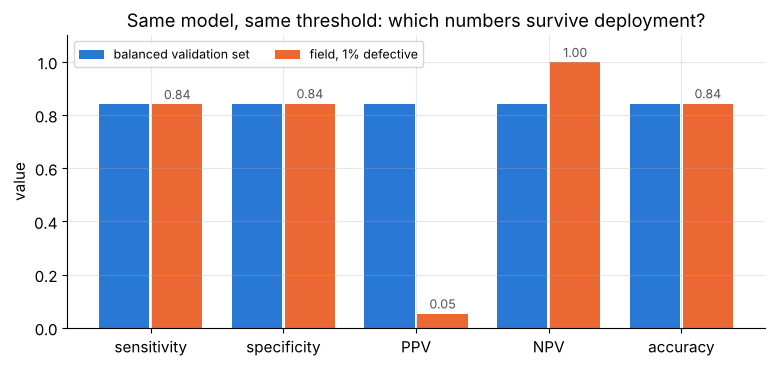

In [17]:
fig, ax = plt.subplots(figsize=(9, 3.8))
names = ["sensitivity", "specificity", "PPV", "NPV", "accuracy"]
xpos = np.arange(len(names))
ax.bar(xpos - 0.2, solar.loc[names, "balanced validation"], width=0.38, color=BLUE, label="balanced validation set")
ax.bar(xpos + 0.2, solar.loc[names, "field (1% defective)"], width=0.38, color=ORANGE, label="field, 1% defective")
for i, name in enumerate(names):
    ax.text(i + 0.2, solar.loc[name, "field (1% defective)"] + 0.02, f"{solar.loc[name, 'field (1% defective)']:.2f}",
            ha="center", fontsize=9, color=INK2)
ax.set_xticks(xpos, names)
ax.set(ylim=(0, 1.1), ylabel="value", title="Same model, same threshold: which numbers survive deployment?")
ax.legend(loc="upper left", ncol=2, fontsize=9)
plt.show()

Sensitivity and specificity barely move (differences are sampling noise), exactly as promised. **Precision collapses** from about 0.84 to about 0.05: in the field roughly 19 of every 20 alarms are false. Accuracy does not collapse at all, because it is dominated by the abundant healthy panels. Best of all, Bayes' rule fed with the *validation* sensitivity and specificity and the *field* prevalence predicted the field precision (about 0.050) before a single field panel was inspected.

> **Common pitfall.** Reporting "precision 84%" from a balanced test set as if it described deployment. Precision, NPV, accuracy and F1 measured on a resampled dataset describe *that dataset's* class mix. To predict deployment precision, carry over sensitivity and specificity, then apply Bayes' rule with the deployment prevalence.

### 4.6 Correcting predicted probabilities for a new prior

The model also outputs *probabilities*, and those are wrong in the field too. A logistic regression trained on balanced data learns $P_{\text{train}}(y = 1 \mid \mathbf{x})$ in a world where half the panels are defective. Let's correct it with the odds form of Bayes' rule.

Let $\Lambda(\mathbf{x}) = p(\mathbf{x} \mid y = 1) / p(\mathbf{x} \mid y = 0)$ be the likelihood ratio of the features. In the training world with prevalence $\pi_t$, and in the deployment world with prevalence $\pi_d$,

$$
O_t(\mathbf{x}) = \frac{\pi_t}{1 - \pi_t}\,\Lambda(\mathbf{x}),
\qquad
O_d(\mathbf{x}) = \frac{\pi_d}{1 - \pi_d}\,\Lambda(\mathbf{x}).
$$

Under prior shift $\Lambda(\mathbf{x})$ is the same in both worlds, so dividing the two equations eliminates it:

$$
O_d(\mathbf{x}) = O_t(\mathbf{x}) \times \frac{\pi_d / (1 - \pi_d)}{\pi_t / (1 - \pi_t)}
\quad\Longleftrightarrow\quad
\operatorname{logit} p_d(\mathbf{x}) = \operatorname{logit} p_t(\mathbf{x}) - \operatorname{logit} \pi_t + \operatorname{logit} \pi_d .
$$

*Example.* The model says $p_t = 0.80$ for a panel. With $\pi_t = 0.5$ and $\pi_d = 0.01$, the odds go from $4$ to $4 \times \frac{1}{99} \approx 0.0404$, so the field probability is about **0.039**, not 0.80.

For logistic regression the correction is simply an **intercept shift**, $b_d = b_t + \operatorname{logit}\pi_d - \operatorname{logit}\pi_t$: the weights, which encode $\Lambda(\mathbf{x})$, stay as they are. Because we generated the data ourselves we also know the exact field posterior, so we can check the correction against the truth.

In [18]:
def shift_prior_probs(p, pi_train, pi_deploy):
    """Prior-shift correction: add logit(pi_deploy) - logit(pi_train) to the log-odds."""
    return special.expit(special.logit(p) - special.logit(pi_train) + special.logit(pi_deploy))


p_field_adj = shift_prior_probs(p_field, 0.5, 0.01)

# The exact field posterior, available here only because we know the generating Gaussians.
inv_cov = np.linalg.inv(COV)
w_true = inv_cov @ (MU_DEFECT - MU_HEALTHY)
b_true = -0.5 * (MU_DEFECT @ inv_cov @ MU_DEFECT - MU_HEALTHY @ inv_cov @ MU_HEALTHY)
p_field_true = special.expit(X_field @ w_true + b_true + special.logit(0.01))

summary = pd.DataFrame({
    "mean predicted P(defect)": [p_field.mean(), p_field_adj.mean(), p_field_true.mean()],
    "log-loss": [-np.mean(y_field * np.log(q) + (1 - y_field) * np.log(1 - q))
                 for q in (p_field, p_field_adj, p_field_true)],
}, index=["raw model output", "prior-shift corrected", "exact posterior"])
display(summary.round(4))
print(f"actual defect rate in the field sample: {y_field.mean():.4f}")
print(f"intercept: trained {model.intercept_[0]:.3f} -> corrected {model.intercept_[0] + special.logit(0.01):.3f}")
corrected_rule = rates(y_field, p_field_adj > 0.5)
print(f"corrected probabilities thresholded at 0.5: {np.sum(p_field_adj > 0.5)} alarms, "
      f"sensitivity {corrected_rule['sensitivity']:.3f}, precision {corrected_rule['PPV']:.3f}")

,mean predicted P(defect),log-loss
raw model output,0.2266,0.3538
prior-shift corrected,0.0104,0.0381
exact posterior,0.0100,0.0380


actual defect rate in the field sample: 0.0103
intercept: trained -2.061 -> corrected -6.656
corrected probabilities thresholded at 0.5: 355 alarms, sensitivity 0.113, precision 0.654


The raw outputs claim that the average panel has a 22.7% chance of being defective, while the truth is about 1%. After the correction the average prediction matches the actual rate, and the log-loss (the cross-entropy of Notebook 07) drops from 0.354 to 0.038, essentially the value achieved by the exact posterior.

A **reliability diagram** shows calibration bin by bin: group panels by predicted probability, then compare the average prediction in each group (x-axis) with the fraction of the group that is actually defective (y-axis). A calibrated model lies on the diagonal. We use the same groups of panels for both curves, so the observed rates are identical and only the predictions move.

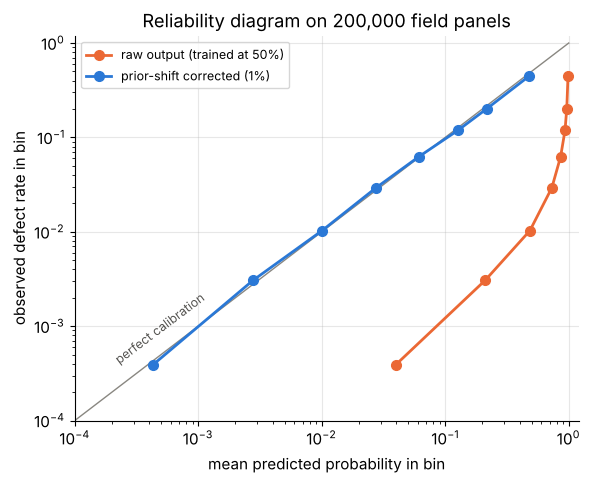

,panels,mean raw p,mean corrected p,observed defect rate
0,100000,0.0398,0.0004,0.0004
1,50000,0.2104,0.0028,0.0031
2,30000,0.4852,0.0101,0.0103
3,10000,0.7300,0.0275,0.0293
4,6000,0.8594,0.0611,0.0625
5,2000,0.9332,0.1269,0.1190
6,1000,0.9641,0.2177,0.2020
7,1000,0.9867,0.4775,0.4460


In [19]:
quantiles = [0, 0.5, 0.75, 0.9, 0.95, 0.98, 0.99, 0.995, 1.0]     # finer bins where the defects are
edges = np.quantile(p_field, quantiles)
bin_id = np.clip(np.searchsorted(edges, p_field, side="right") - 1, 0, len(edges) - 2)
rel = pd.DataFrame({"panels": np.bincount(bin_id),
                    "mean raw p": [p_field[bin_id == k].mean() for k in range(len(edges) - 1)],
                    "mean corrected p": [p_field_adj[bin_id == k].mean() for k in range(len(edges) - 1)],
                    "observed defect rate": [y_field[bin_id == k].mean() for k in range(len(edges) - 1)]})

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.plot([1e-4, 1], [1e-4, 1], color=MUTED, lw=1)
ax.text(2e-4, 4e-4, "perfect calibration", rotation=37, color=INK2, fontsize=9)
ax.plot(rel["mean raw p"], rel["observed defect rate"], "o-", color=ORANGE, lw=2, ms=7, label="raw output (trained at 50%)")
ax.plot(rel["mean corrected p"], rel["observed defect rate"], "o-", color=BLUE, lw=2, ms=7, label="prior-shift corrected (1%)")
ax.set(xscale="log", yscale="log", xlim=(1e-4, 1.2), ylim=(1e-4, 1.2),
       xlabel="mean predicted probability in bin", ylabel="observed defect rate in bin",
       title="Reliability diagram on 200,000 field panels")
ax.legend(loc="upper left", fontsize=9)
plt.show()
display(rel.round(5))

The raw curve sits far to the right of the diagonal: in every bin the model overstates the risk by a factor of roughly 99 in odds (one factor of $\frac{0.5}{0.5} \big/ \frac{0.01}{0.99}$). The corrected curve hugs the diagonal across three orders of magnitude (bin averages from about 0.0004 to 0.5).

Correct probabilities change *which threshold makes sense*. Thresholding the corrected probabilities at 0.5 would raise an alarm only for panels that are more likely defective than not: sensitivity falls to about 0.11 and precision rises to about 0.65. Is that better or worse than the raw threshold? Neither question has an answer until we know what a missed defect and a needless inspection each *cost*. That is the subject of Section 5, and the right order of operations is: **first calibrate the probabilities, then choose the threshold from the costs.**

> **Common pitfall.** The correction is valid only under **pure prior shift**. If field panels look different from the training panels (a new camera, different weather, a new panel model), then $p(\mathbf{x} \mid y)$ has changed and the model must be re-validated on field data. Also note that $\pi_t$ is the *effective* training prevalence: class weights or oversampling to balance the classes amount to $\pi_t = 0.5$ even if the raw data were imbalanced.

> **Going deeper.** The field prevalence $\pi_d$ is not always known. It can be estimated from a small random audit, or from the unlabeled field predictions themselves with a short EM algorithm that alternates between correcting the probabilities and re-estimating the prevalence (Saerens, Latinne and Decaestecker, 2002).

✏️ **Exercise 5: prior-shift correction.** Implement `shift_prior(p, pi_train, pi_deploy)` without looking at `shift_prior_probs` above. It must work element-wise on NumPy arrays.

In [20]:
# ✏️ Exercise 5: prior-shift correction
def shift_prior(p, pi_train, pi_deploy):
    """Convert probabilities calibrated for prevalence pi_train into ones calibrated for pi_deploy."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    out = shift_prior(0.5, 0.5, 0.01)
    assert np.isclose(out, 0.01), f"an undecided model output must map to the new prior: got {out}"
    out = shift_prior(np.array([0.2, 0.9, 0.99]), 0.5, 0.5)
    assert np.allclose(out, [0.2, 0.9, 0.99]), "no prior change -> no change in output"
    out = shift_prior(0.8, 0.5, 0.05)
    assert np.isclose(out, 0.17391304), f"0.8 calibrated at 50% -> 5%: got {out}"
    out = shift_prior(0.6, 0.25, 0.4)
    assert np.isclose(out, 0.75), f"0.6 calibrated at 25% -> 40%: got {out}"
    back = shift_prior(shift_prior(0.37, 0.5, 0.02), 0.02, 0.5)
    assert np.isclose(back, 0.37), "shifting there and back must return the original value"


run_check("Exercise 5", _test)

⏳ Exercise 5: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def shift_prior(p, pi_train, pi_deploy):
    p = np.asarray(p, dtype=float)
    z = special.logit(p) - special.logit(pi_train) + special.logit(pi_deploy)
    return special.expit(z)
```
Equivalently in odds: multiply $p/(1-p)$ by $\frac{\pi_d/(1-\pi_d)}{\pi_t/(1-\pi_t)}$ and convert back. For the fourth test case: odds $1.5 \times \frac{0.4/0.6}{0.25/0.75} = 1.5 \times 2 = 3$, so $p = 0.75$.
</details>

**Quick check.**
1. A detector has sensitivity 0.90 and specificity 0.90. At what prevalence is its PPV exactly 50%?
2. A model shows precision 0.80 on a test set with 50% positives. Can you recover its sensitivity from this number? Can you predict its precision at 2% prevalence, assuming pure prior shift?
3. True or false: a detector that never raises an alarm has a specificity of 1.

<details>
<summary>Answer</summary>

1. $\pi_{1/2} = (1 - c)/(s + 1 - c) = 0.1 / 1.0 = 0.10$. Check with 1,000 cases: 100 positives give 90 true alarms, and 900 negatives give 90 false alarms.
2. Sensitivity: no. On a balanced set the precision odds equal the likelihood ratio, so you learn only $\Lambda_+ = s/(1-c) = \text{PPV}/(1 - \text{PPV}) = 0.80/0.20 = 4$, one equation in two unknowns. Deployment precision: yes, because it depends on $s$ and $c$ only through $\Lambda_+$: the odds are $4 \times 0.02/0.98 \approx 0.0816$, so the precision is about 0.075.
3. True: it produces no false positives, so $TN/(TN + FP) = 1$. Its sensitivity is 0, which is why no single rate can describe a detector.
</details>

## 5. From rates to deployment: expected counts, costs and capacity

Section 4 turned a detector's rates into the meaning of *one* alarm. Operations teams think in totals instead: *how many alerts will land in the queue tomorrow, how many attacks will slip through, and what will it all cost?* This section answers those questions and then uses the answers to choose a decision threshold.

### 5.1 The scenario: a phishing quarantine

A company's mail gateway scores every incoming message with a phishing classifier and moves high scorers into a quarantine folder, where a security analyst reviews them by hand. The facts:

- About **20,000** messages arrive per day, and about **0.6%** of them are phishing (roughly 120 per day).
- The model was validated on a **balanced** set (equal numbers of phishing and legitimate messages) at two candidate thresholds:

| threshold | sensitivity $s$ | specificity $c$ | FPR $= 1 - c$ |
|---|---|---|---|
| lenient (low threshold) | 0.98 | 0.94 | 0.06 |
| strict (high threshold) | 0.90 | 0.996 | 0.004 |

- A phishing message that reaches an inbox (a **false negative**) costs about **300** units on average (account takeovers, cleanup). A legitimate message stuck in quarantine (a **false positive**) costs about **2** units (analyst time plus a delayed email). Correct decisions cost nothing extra.
- The analysts can review at most **200** quarantined messages per day: an **alert budget**.

By Section 4.5 the balanced validation set gives trustworthy sensitivity and specificity, but its precision is meaningless here. We need deployment numbers.

### 5.2 Expected confusion counts

Treat each of the $N$ messages as an independent trial. A message is a true positive with probability $\pi s$, a false negative with probability $\pi(1-s)$, and so on. Because expectation is linear, the expected count in each cell is simply $N$ times that cell's probability:

$$
\mathbb{E}[TP] = N\pi s, \qquad \mathbb{E}[FN] = N\pi(1-s), \qquad \mathbb{E}[FP] = N(1-\pi)(1-c), \qquad \mathbb{E}[TN] = N(1-\pi)\,c .
$$

By hand for the **strict** threshold: there are $N\pi = 20{,}000 \times 0.006 = 120$ phishing messages and $19{,}880$ legitimate ones.

| | quarantined | delivered | total |
|---|---|---|---|
| phishing | $120 \times 0.90 = 108$ | $120 \times 0.10 = 12$ | 120 |
| legitimate | $19{,}880 \times 0.004 = 79.52$ | $19{,}880 \times 0.996 = 19{,}800.48$ | 19,880 |
| total | **187.52** | 19,812.48 | 20,000 |

So the deployment precision is $108 / 187.52 \approx 0.576$. Fractional counts are fine: they are averages over many days.

> **Common pitfall.** Apply each rate to **its own group**. The FPR multiplies the *legitimate* messages (19,880), never the phishing ones (120) and never the total. A classic wrong answer computes "false positives $= 120 \times 0.004 = 0.48$" and concludes that the strict threshold almost never bothers anyone.

In [21]:
N_MSG, PREV_PHISH = 20_000, 0.006            # messages per day, fraction that is phishing
C_FN_MAIL, C_FP_MAIL, CAPACITY = 300, 2, 200  # cost of a miss, cost of a false alarm, reviews per day
operating_points = {"lenient": (0.98, 0.94), "strict": (0.90, 0.996)}   # (sensitivity, specificity)


def deployment_counts(n, prevalence, sens, spec):
    """Expected TP, FN, FP, TN when n cases with the given prevalence meet a detector."""
    pos, neg = n * prevalence, n * (1 - prevalence)
    return {"TP": pos * sens, "FN": pos * (1 - sens), "FP": neg * (1 - spec), "TN": neg * spec}


rows = {}
for name, (s, c) in operating_points.items():
    d = deployment_counts(N_MSG, PREV_PHISH, s, c)
    d["alerts (TP + FP)"] = d["TP"] + d["FP"]
    d["PPV"] = d["TP"] / d["alerts (TP + FP)"]
    d["cost of misses"] = C_FN_MAIL * d["FN"]
    d["cost of false alarms"] = C_FP_MAIL * d["FP"]
    d["expected cost"] = d["cost of misses"] + d["cost of false alarms"]
    rows[name] = d
deploy = pd.DataFrame(rows)
display(deploy.round(4))

,lenient,strict
TP,117.6000,108.0000
FN,2.4000,12.0000
FP,1192.8000,79.5200
TN,18687.2000,19800.4800
alerts (TP + FP),1310.4000,187.5200
PPV,0.0897,0.5759
cost of misses,720.0000,3600.0000
cost of false alarms,2385.6000,159.0400
expected cost,3105.6000,3759.0400


### 5.3 Expected cost: weigh the mistakes, don't just count them

Give each cell of the confusion matrix a cost per case, $C_{TP}, C_{FN}, C_{FP}, C_{TN}$. The expected total cost is the sum of (expected count) × (cost per case):

$$
\mathbb{E}[\text{cost}] = C_{TP}\,\mathbb{E}[TP] + C_{FN}\,\mathbb{E}[FN] + C_{FP}\,\mathbb{E}[FP] + C_{TN}\,\mathbb{E}[TN] .
$$

Here $C_{TP} = C_{TN} = 0$, so the strict threshold costs $300 \times 12 + 2 \times 79.52 = 3{,}600 + 159.04 = 3{,}759.04$ units per day, and the lenient one costs $300 \times 2.4 + 2 \times 1{,}192.8 = 720 + 2{,}385.6 = 3{,}105.6$.

Compare how the two thresholds *feel* with how they actually compare. The lenient threshold has a dismal precision of 9%: more than 9 in 10 quarantined messages are legitimate. Yet it is **cheaper**. Relative to the strict threshold it catches $117.6 - 108 = 9.6$ more phishing messages per day, saving $9.6 \times 300 = 2{,}880$ units, and raises $1{,}192.8 - 79.52 = 1{,}113.28$ more false alarms, costing $1{,}113.28 \times 2 = 2{,}226.56$ units. Net saving: $653.44$. Precision alone cannot rank thresholds, but costs can.

### 5.4 The alert budget

There is a catch. The lenient threshold sends about **1,310** messages per day to a team that can review **200**. It is not an option at all, however cheap it looks on paper. With a capacity limit the decision problem becomes

$$
\min_{\text{threshold}} \ \mathbb{E}[\text{cost}] \qquad \text{subject to} \qquad \mathbb{E}[\text{alerts}] = N\,\big[\pi s + (1-\pi)(1-c)\big] \le \text{capacity}.
$$

The strict threshold, with 187.52 expected alerts, is feasible, so between these two candidates **the strict threshold wins**, even though it costs more when capacity is ignored.

"Feasible on average" is not "feasible every day", though. Each message independently triggers an alert with probability $p_{\text{alert}} = \pi s + (1-\pi)(1-c) = 0.009376$, so the daily number of alerts follows a **binomial distribution** $\text{Bin}(N, p_{\text{alert}})$ with mean $187.52$ and standard deviation $\sqrt{N p_{\text{alert}}(1 - p_{\text{alert}})} \approx 13.6$. The budget of 200 sits less than one standard deviation above the mean, so the queue will overflow on a noticeable fraction of days. The next cell computes that fraction exactly, and checks every expected count and cost above by simulating 2,000 days.

,lenient,strict
mean TP (sim),117.6730,107.8190
mean FP (sim),1193.0245,79.4080
mean alerts (sim),1310.6975,187.2270
sd alerts (sim),35.2436,13.6857
mean cost (sim),3095.5490,3763.9160
P(alerts > 200) exact,1.0000,0.1701
share of days > 200 (sim),1.0000,0.1665


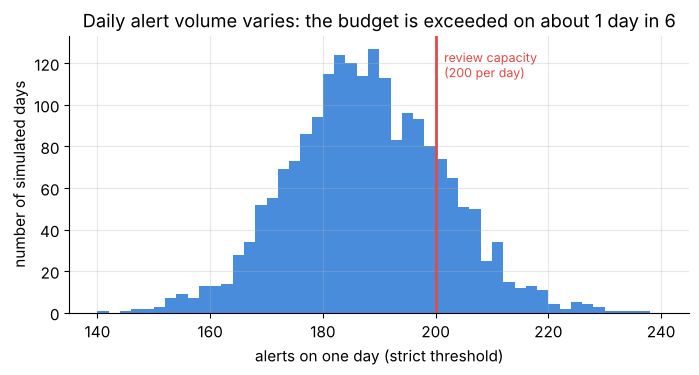

In [22]:
rng_days = np.random.default_rng(SEED)
n_days = 2_000
sim_rows = {}
daily_alerts = {}
for name, (s, c) in operating_points.items():
    n_phish = rng_days.binomial(N_MSG, PREV_PHISH, size=n_days)        # phishing messages each day
    tp_day = rng_days.binomial(n_phish, s)                             # caught
    fp_day = rng_days.binomial(N_MSG - n_phish, 1 - c)                 # legitimate but quarantined
    alerts_day = tp_day + fp_day
    cost_day = C_FN_MAIL * (n_phish - tp_day) + C_FP_MAIL * fp_day
    p_alert = PREV_PHISH * s + (1 - PREV_PHISH) * (1 - c)
    daily_alerts[name] = alerts_day
    sim_rows[name] = {
        "mean TP (sim)": tp_day.mean(), "mean FP (sim)": fp_day.mean(),
        "mean alerts (sim)": alerts_day.mean(), "sd alerts (sim)": alerts_day.std(),
        "mean cost (sim)": cost_day.mean(),
        "P(alerts > 200) exact": stats.binom.sf(CAPACITY, N_MSG, p_alert),
        "share of days > 200 (sim)": (alerts_day > CAPACITY).mean(),
    }
display(pd.DataFrame(sim_rows).round(4))

fig, ax = plt.subplots(figsize=(8, 3.6))
bins = np.arange(140, 241, 2)
ax.hist(daily_alerts["strict"], bins=bins, color=BLUE, alpha=0.85)
ax.axvline(CAPACITY, color=RED, lw=2)
ax.text(CAPACITY + 1.5, ax.get_ylim()[1] * 0.85, "review capacity\n(200 per day)", color=RED, fontsize=9)
ax.set(xlabel="alerts on one day (strict threshold)", ylabel="number of simulated days",
       title="Daily alert volume varies: the budget is exceeded on about 1 day in 6")
plt.show()

The simulated averages match the expected counts and costs of Section 5.2 to within sampling noise, and the exact binomial tail says the strict threshold overflows the review queue on about **17%** of days. In practice, teams leave some headroom, or let the overflow wait until the next day.

### 5.5 Choosing a threshold from the whole ROC curve

Two candidate thresholds are a toy version of the real problem. A model outputs a continuous score, and every threshold $t$ on that score gives one operating point $(\text{FPR}(t), \text{TPR}(t))$. The set of all these points is the **ROC curve** (receiver operating characteristic).

To have a smooth curve to optimize, we use the classic **binormal model**: legitimate messages get scores drawn from $\mathcal{N}(0, 1)$, phishing messages get scores drawn from $\mathcal{N}(\mu, \sigma^2)$, and a message is quarantined when its score exceeds $t$. Then

$$
\text{FPR}(t) = 1 - \Phi(t), \qquad \text{TPR}(t) = 1 - \Phi\!\left(\frac{t - \mu}{\sigma}\right),
$$

where $\Phi$ is the standard normal CDF. Each validated operating point pins down one equation: $t = \Phi^{-1}(c)$ from the specificity, and $t = \mu + \sigma\,\Phi^{-1}(1 - s)$ from the sensitivity. Two points give two linear equations in $\mu$ and $\sigma$. With the curve in hand, the expected daily cost and alert volume become smooth functions of the threshold:

$$
\text{cost}(t) = N\big[\pi\,(1 - \text{TPR}(t))\,C_{FN} + (1-\pi)\,\text{FPR}(t)\,C_{FP}\big],
\qquad
\text{alerts}(t) = N\big[\pi\,\text{TPR}(t) + (1-\pi)\,\text{FPR}(t)\big].
$$

In [23]:
# Fit the binormal ROC curve through the two validated operating points.
z = stats.norm.ppf
t_len, t_str = z(0.94), z(0.996)                         # FPR(t) = 1 - Phi(t)  =>  t = Phi^{-1}(specificity)
sigma_ph = (t_str - t_len) / (z(1 - 0.90) - z(1 - 0.98))  # from t = mu + sigma * Phi^{-1}(1 - sensitivity)
mu_ph = t_len - sigma_ph * z(1 - 0.98)
print(f"mu = {mu_ph:.3f}, sigma = {sigma_ph:.3f}, lenient threshold t = {t_len:.3f}, strict t = {t_str:.3f}")
print(f"area under this ROC curve (AUC) = {stats.norm.cdf(mu_ph / np.sqrt(1 + sigma_ph**2)):.4f}")


def tpr_t(t):
    return stats.norm.sf(t, loc=mu_ph, scale=sigma_ph)


def fpr_t(t):
    return stats.norm.sf(t)


def cost_t(t):
    return N_MSG * (PREV_PHISH * (1 - tpr_t(t)) * C_FN_MAIL + (1 - PREV_PHISH) * fpr_t(t) * C_FP_MAIL)


def alerts_t(t):
    return N_MSG * (PREV_PHISH * tpr_t(t) + (1 - PREV_PHISH) * fpr_t(t))


def posterior_t(t):
    """P(phishing | score = t) in deployment: prior odds times the likelihood ratio of the score."""
    lr = stats.norm.pdf(t, mu_ph, sigma_ph) / stats.norm.pdf(t)
    return from_odds(to_odds(PREV_PHISH) * lr)


t_star = optimize.minimize_scalar(cost_t, bounds=(0, 6), method="bounded", options={"xatol": 1e-10}).x
t_cap = optimize.brentq(lambda t: alerts_t(t) - CAPACITY, 0, 6, xtol=1e-12)
t_half = optimize.brentq(lambda t: posterior_t(t) - 0.5, 0, 10, xtol=1e-12)

candidates = {"lenient (validated)": t_len, "strict (validated)": t_str, "cost-optimal t*": t_star,
              "capacity-constrained": t_cap, "posterior > 0.5": t_half}
roc_table = pd.DataFrame({name: {"threshold t": t, "TPR": tpr_t(t), "FPR": fpr_t(t), "alerts": alerts_t(t),
                                 "expected cost": cost_t(t), "posterior at t": posterior_t(t)}
                          for name, t in candidates.items()}).T.round(4)
roc_table["within budget"] = np.where(roc_table["alerts"] <= CAPACITY + 1e-6, "yes", "no")
display(roc_table)

mu = 4.473, sigma = 1.421; lenient threshold t = 1.555, strict t = 2.652
area under this ROC curve (AUC) = 0.9950


,threshold t,TPR,FPR,alerts,expected cost,posterior at t,within budget
lenient (validated),1.5548,0.9800,0.0600,1310.4000,3105.6000,0.0017,no
strict (validated),2.6521,0.9000,0.0040,187.5200,3759.0400,0.0592,yes
cost-optimal t*,1.9892,0.9598,0.0233,579.1442,2376.2365,0.0066,no
capacity-constrained,2.6050,0.9057,0.0046,200.0000,3577.8635,0.0506,yes
posterior > 0.5,3.3915,0.7767,0.0003,100.1180,8051.3930,0.5000,yes


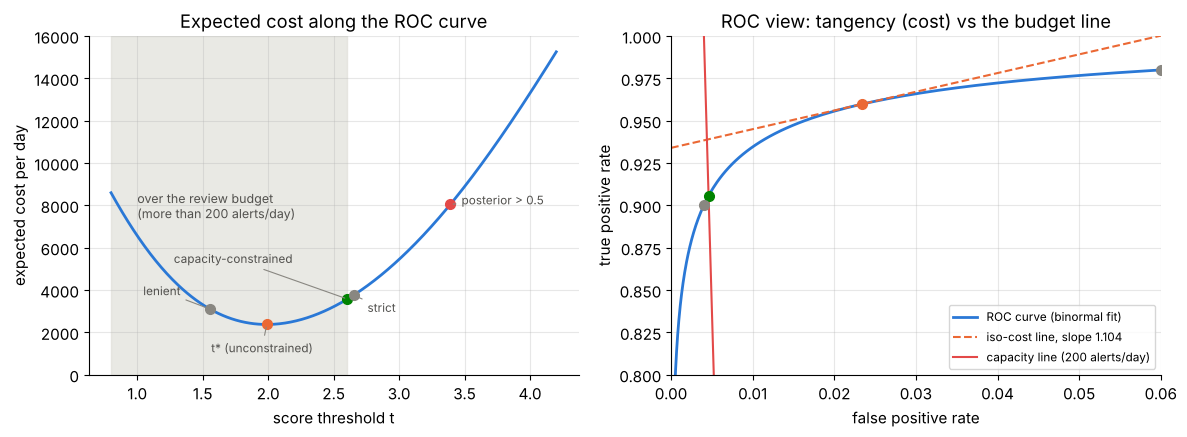

In [24]:
ts = np.linspace(0.8, 4.2, 400)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

ax = axes[0]
ax.plot(ts, cost_t(ts), color=BLUE, lw=2)
ax.axvspan(ts[0], t_cap, color=LIGHT, alpha=0.7)
ax.text(1.0, 7400, "over the review budget\n(more than 200 alerts/day)", color=INK2, fontsize=9)
for name, t, color, offset in [("t* (unconstrained)", t_star, ORANGE, (-40, -20)),
                               ("capacity-constrained", t_cap, GREEN, (-125, 26)),
                               ("lenient", t_len, MUTED, (-48, 10)), ("strict", t_str, MUTED, (10, -12)),
                               ("posterior > 0.5", t_half, RED, (8, 0))]:
    ax.plot(t, cost_t(t), "o", color=color, ms=7)
    ax.annotate(name, (t, cost_t(t)), xytext=offset, textcoords="offset points", fontsize=8.5, color=INK2,
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set(xlabel="score threshold t", ylabel="expected cost per day", title="Expected cost along the ROC curve",
       ylim=(0, 16000))

ax = axes[1]
tt = np.linspace(0.0, 6.0, 600)
ax.plot(fpr_t(tt), tpr_t(tt), color=BLUE, lw=2, label="ROC curve (binormal fit)")
slope_iso = (1 - PREV_PHISH) * C_FP_MAIL / (PREV_PHISH * C_FN_MAIL)     # iso-cost lines have this slope
fx = np.linspace(0, 0.06, 2)
ax.plot(fx, tpr_t(t_star) + slope_iso * (fx - fpr_t(t_star)), color=ORANGE, lw=1.5, ls="--",
        label=f"iso-cost line, slope {slope_iso:.3f}")
ty = np.linspace(0.8, 1.0, 2)
ax.plot((CAPACITY / N_MSG - PREV_PHISH * ty) / (1 - PREV_PHISH), ty, color=RED, lw=1.5,
        label="capacity line (200 alerts/day)")
for t, color in [(t_star, ORANGE), (t_cap, GREEN), (t_len, MUTED), (t_str, MUTED)]:
    ax.plot(fpr_t(t), tpr_t(t), "o", color=color, ms=7)
ax.set(xlim=(0, 0.06), ylim=(0.8, 1.0), xlabel="false positive rate", ylabel="true positive rate",
       title="ROC view: tangency (cost) vs the budget line")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

What the table and the two panels say:

- **Unconstrained optimum.** The expected cost is smallest at $t^{*} \approx 1.99$: about **2,376** units per day, far better than either validated threshold. But it quarantines about **579** messages a day, nearly three times the budget.
- **With the budget.** Raising the threshold lowers the alert volume, so the feasible thresholds are $t \ge t_{\text{cap}} \approx 2.605$ (the shaded region on the left is off-limits). To the right of $t^{*}$ the cost only increases, so the best feasible choice is the *smallest* feasible threshold: set $t$ so the queue is exactly full on average. That gives an expected cost of about **3,578** units, with sensitivity 0.906. It beats the validated strict threshold (3,759) because it spends the review budget completely instead of leaving 12.5 reviews per day unused.
- **The general rule:** if the unconstrained optimum fits in the budget, use it. If it does not, move the threshold just far enough to meet the budget.
- **The default 0.5 is a disaster here.** Quarantining only messages that are more likely phishing than not catches just 78% of phishing and costs about **8,051** units per day, more than three times the unconstrained optimum.

The right panel shows the same story geometrically. Rewrite $\text{cost}(t) = \text{const}$ as a line in ROC space:

$$
\text{TPR} = \text{const}' + \underbrace{\frac{(1-\pi)\,C_{FP}}{\pi\,C_{FN}}}_{m^{*} \,=\, 1.104}\;\text{FPR}.
$$

All operating points on such an **iso-cost line** have the same expected cost, and lines further up and to the left are cheaper. The cost-optimal operating point is where the ROC curve just *touches* the best iso-cost line, so the ROC slope there equals $m^{*}$. The capacity condition $\pi\,\text{TPR} + (1-\pi)\,\text{FPR} \le 200/N$ is the nearly vertical red line, and only points to its left are allowed. The capacity-constrained optimum is where the ROC curve crosses it.

> **Going deeper.** In the binormal model the slope of the ROC curve at threshold $t$ is $\frac{d\,\text{TPR}}{d\,\text{FPR}} = \frac{f_1(t)}{f_0(t)}$, the **likelihood ratio** of the score $t$ (here $f_1$ and $f_0$ are the score densities of the two classes). This holds for any ROC curve built from a continuous score. So the tangency condition says: the optimal threshold is the score whose likelihood ratio equals $m^{*} = \frac{1-\pi}{\pi} \cdot \frac{C_{FP}}{C_{FN}}$. The next subsection translates that into a statement about posteriors.

**Headroom for busy days.** Section 5.4 showed that the daily number of alerts is random (binomial). A threshold that fills the budget *on average* overflows the queue on roughly half of all days. If the team wants an overflow on at most one day in twenty, the requirement becomes $P(\text{alerts} > 200) \le 0.05$, a so-called **chance constraint**, and the threshold must rise a little further.

In [25]:
def overflow_prob(t):
    """P(more than CAPACITY alerts on one day): each message alerts with probability alerts_t(t) / N_MSG."""
    return stats.binom.sf(CAPACITY, N_MSG, alerts_t(t) / N_MSG)


t_safe = optimize.brentq(lambda t: overflow_prob(t) - 0.05, t_cap, 6, xtol=1e-10)
for name, t in [("fill the budget on average", t_cap), ("strict (validated)", t_str),
                ("overflow on <= 5% of days", t_safe)]:
    print(f"{name:<27s} t = {t:.3f} | expected alerts {alerts_t(t):5.1f} | P(overflow) {overflow_prob(t):.3f} | "
          f"sensitivity {tpr_t(t):.3f} | expected cost {cost_t(t):6.1f}")

fill the budget on average  t = 2.605 | expected alerts 200.0 | P(overflow) 0.481 | sensitivity 0.906 | expected cost 3577.9
strict (validated)          t = 2.652 | expected alerts 187.5 | P(overflow) 0.170 | sensitivity 0.900 | expected cost 3759.0
overflow on <= 5% of days   t = 2.690 | expected alerts 178.4 | P(overflow) 0.050 | sensitivity 0.895 | expected cost 3915.3


Filling the budget on average overflows on 48% of days. Limiting overflows to 5% of days requires $t \approx 2.69$ (about 178 expected alerts) and costs about $3{,}915 - 3{,}578 \approx 337$ extra units per day in missed phishing: the price of a reliable queue. Whether that price is worth paying is a management question (can the overflow wait until tomorrow?), but the numbers needed to answer it come straight from Bayes' rule and the binomial distribution.

### 5.6 The Bayes-optimal threshold on the posterior

Suppose that for one message you know the calibrated posterior $p = P(\text{phishing} \mid \mathbf{x})$, and you must choose between two actions. Each action's expected cost averages over the two possible truths:

| action | if phishing (prob. $p$) | if legitimate (prob. $1-p$) | expected cost |
|---|---|---|---|
| quarantine | $C_{TP}$ | $C_{FP}$ | $p\,C_{TP} + (1-p)\,C_{FP}$ |
| deliver | $C_{FN}$ | $C_{TN}$ | $p\,C_{FN} + (1-p)\,C_{TN}$ |

Quarantine exactly when the first expected cost is smaller:

$$
p\,C_{TP} + (1-p)\,C_{FP} < p\,C_{FN} + (1-p)\,C_{TN}
\;\Longleftrightarrow\;
(1-p)\,(C_{FP} - C_{TN}) < p\,(C_{FN} - C_{TP})
\;\Longleftrightarrow\;
p > p^{*} = \frac{C_{FP} - C_{TN}}{(C_{FP} - C_{TN}) + (C_{FN} - C_{TP})} .
$$

(The last step divides by the positive number $(C_{FP} - C_{TN}) + (C_{FN} - C_{TP})$, which assumes each mistake costs more than the corresponding correct decision.) With the usual convention $C_{TP} = C_{TN} = 0$:

$$
\boxed{\;p^{*} = \frac{C_{FP}}{C_{FP} + C_{FN}}\;}
$$

- The threshold depends only on the **ratio** of the costs, never on their units. The familiar 0.5 is the special case $C_{FP} = C_{FN}$.
- For the gateway, $p^{*} = 2/302 \approx 0.0066$: quarantine anything with more than a 0.66% chance of being phishing. That is barely above the 0.6% base rate, which is why the unconstrained optimum quarantines so many messages. The table above confirms that the posterior at $t^{*}$ is exactly $0.0066$: the ROC tangency condition and the posterior threshold are the same condition, because posterior odds = prior odds × likelihood ratio, and $\frac{\pi}{1-\pi} \times m^{*} = \frac{C_{FP}}{C_{FN}}$, which are exactly the odds of $p^{*}$.
- The rule is optimal for **each message separately**, so it also minimizes the total: no rule that looks only at $\mathbf{x}$ can have a lower expected cost.
- A capacity limit acts like an extra **charge $\lambda$ per alert** (a Lagrange multiplier, or "shadow price"): the threshold becomes $(C_{FP} + \lambda)/(C_{FP} + C_{FN})$. At the capacity-constrained optimum the posterior is $0.0506$, so $\lambda = 0.0506 \times 302 - 2 \approx 13.3$: under this budget, one analyst review is effectively worth about 13 cost units.

> **Common pitfall.** $p^{*}$ is a threshold on a **calibrated posterior in the deployment population**. Apply it to raw scores from a model trained on balanced data and you are effectively using a different threshold (in Section 4.6 the raw odds were inflated 99-fold). *Calibrate first, then threshold.* A related slip: the expected cost of *delivering* a message is $C_{FN}$ times the probability that the message **is phishing**, not times the model's confidence in whatever label it predicted.

The simulation below checks the formula with 200,000 cases whose posteriors $p$ are spread uniformly over $[0, 1]$ and whose labels are drawn with exactly those probabilities (perfect calibration). For a threshold $\tau$ the expected cost per case is then $C_{FN}\,\mathbb{E}[p\,;\,p \le \tau] + C_{FP}\,\mathbb{E}[1-p\,;\,p > \tau] = C_{FN}\tau^{2}/2 + C_{FP}(1-\tau)^{2}/2$, whose derivative vanishes exactly at $\tau = p^{*}$.

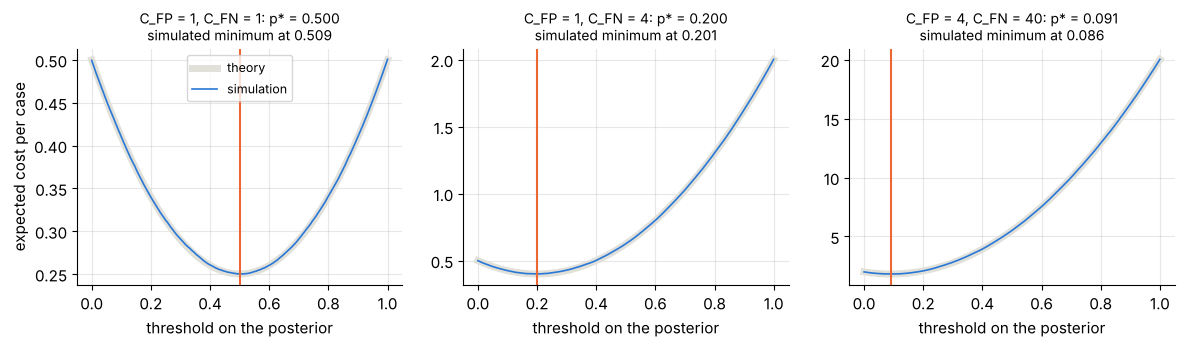

In [26]:
rng_cal = np.random.default_rng(SEED)
n_cases = 200_000
p_cal = rng_cal.random(n_cases)              # calibrated posteriors, spread uniformly over [0, 1]
y_cal = rng_cal.random(n_cases) < p_cal      # each case is positive with exactly its stated probability

order = np.argsort(p_cal)
p_sorted, y_sorted = p_cal[order], y_cal[order]
pos_below = np.concatenate([[0], np.cumsum(y_sorted)])    # positives at or below a threshold (missed)
neg_below = np.concatenate([[0], np.cumsum(~y_sorted)])   # negatives at or below a threshold (correctly let through)
grid = np.linspace(0, 1, 1001)
k_below = np.searchsorted(p_sorted, grid, side="right")   # number of cases at or below each threshold

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6))
for ax, (c_fp, c_fn) in zip(axes, [(1, 1), (1, 4), (4, 40)]):
    sim_cost = (c_fn * pos_below[k_below] + c_fp * (neg_below[-1] - neg_below[k_below])) / n_cases
    theory = c_fn * grid**2 / 2 + c_fp * (1 - grid) ** 2 / 2
    p_star = c_fp / (c_fp + c_fn)
    ax.plot(grid, theory, color=LIGHT, lw=5, label="theory")
    ax.plot(grid, sim_cost, color=BLUE, lw=1.2, label="simulation")
    ax.axvline(p_star, color=ORANGE, lw=1.5)
    ax.set_title(f"C_FP = {c_fp}, C_FN = {c_fn}: p* = {p_star:.3f}\nsimulated minimum at {grid[np.argmin(sim_cost)]:.3f}",
                 fontsize=10)
    ax.set_xlabel("threshold on the posterior")
axes[0].set_ylabel("expected cost per case")
axes[0].legend(fontsize=9)
plt.tight_layout()
plt.show()

In each panel the simulated cost curve follows the theoretical parabola, and its minimum sits at $p^{*}$ (orange line) up to sampling noise. Notice how **flat** the curves are near the minimum: a threshold slightly off $p^{*}$ costs very little extra, while a threshold far off (0.5 when $p^{*} = 0.09$) costs a lot.

✏️ **Exercise 6: choose a threshold under a budget.** Implement `expected_outcomes(n, prevalence, sens, spec, c_fn, c_fp)`, returning a dict with keys `"tp"`, `"fn"`, `"fp"`, `"tn"`, `"alerts"`, `"ppv"` and `"cost"` (expected values, with $C_{TP} = C_{TN} = 0$). Then implement `pick_threshold(candidates, n, prevalence, c_fn, c_fp, capacity)`, where `candidates` maps a name to a `(sens, spec)` pair. It must return the name of the cheapest candidate whose expected number of alerts fits within `capacity`, or `None` if no candidate fits.

In [27]:
# ✏️ Exercise 6: choose a threshold under a budget
def expected_outcomes(n, prevalence, sens, spec, c_fn, c_fp):
    """Expected tp, fn, fp, tn, alerts, ppv and cost for n cases."""
    # YOUR CODE HERE
    raise NotImplementedError


def pick_threshold(candidates, n, prevalence, c_fn, c_fp, capacity):
    """Name of the cheapest candidate with expected alerts <= capacity (None if there is none)."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    out = expected_outcomes(20_000, 0.006, 0.90, 0.996, c_fn=300, c_fp=2)
    want = {"tp": 108.0, "fn": 12.0, "fp": 79.52, "tn": 19_800.48, "alerts": 187.52, "ppv": 108 / 187.52, "cost": 3759.04}
    for k, v in want.items():
        assert k in out, f"missing key '{k}'"
        assert np.isclose(out[k], v), f"{k}: expected {v}, got {out[k]}"
    cands = {"lenient": (0.98, 0.94), "strict": (0.90, 0.996)}
    assert pick_threshold(cands, 20_000, 0.006, 300, 2, capacity=200) == "strict", "capacity 200 -> strict"
    assert pick_threshold(cands, 20_000, 0.006, 300, 2, capacity=2_000) == "lenient", "capacity 2000 -> lenient"
    assert pick_threshold(cands, 20_000, 0.006, 300, 2, capacity=100) is None, "no feasible candidate -> None"
    cands2 = {"a": (0.99, 0.90), "b": (0.80, 0.99), "c": (0.70, 0.999)}
    assert pick_threshold(cands2, 5_000, 0.02, 1_000, 10, capacity=200) == "b", "second scenario"


run_check("Exercise 6", _test)

⏳ Exercise 6: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def expected_outcomes(n, prevalence, sens, spec, c_fn, c_fp):
    pos, neg = n * prevalence, n * (1 - prevalence)
    tp, fn = pos * sens, pos * (1 - sens)            # sensitivity acts on the positives
    fp, tn = neg * (1 - spec), neg * spec            # FPR acts on the negatives
    return {"tp": tp, "fn": fn, "fp": fp, "tn": tn, "alerts": tp + fp,
            "ppv": tp / (tp + fp), "cost": c_fn * fn + c_fp * fp}

def pick_threshold(candidates, n, prevalence, c_fn, c_fp, capacity):
    best, best_cost = None, math.inf
    for name, (sens, spec) in candidates.items():
        out = expected_outcomes(n, prevalence, sens, spec, c_fn, c_fp)
        if out["alerts"] <= capacity and out["cost"] < best_cost:
            best, best_cost = name, out["cost"]
    return best
```
In the second scenario there are 100 positives and 4,900 negatives. Candidate "a" raises 99 + 490 = 589 alerts and is infeasible. "b" raises 80 + 49 = 129 alerts at a cost of $20 \times 1000 + 49 \times 10 = 20{,}490$, and "c" raises 74.9 alerts but costs $30 \times 1000 + 4.9 \times 10 = 30{,}049$. So "b" wins.
</details>

✏️ **Exercise 7: the general cost threshold.** Implement `bayes_threshold(c_fp, c_fn, c_tp=0.0, c_tn=0.0)`, the posterior probability above which raising an alarm has the lower expected cost, for a general cost matrix.

In [28]:
# ✏️ Exercise 7: the general cost threshold
def bayes_threshold(c_fp, c_fn, c_tp=0.0, c_tn=0.0):
    """Posterior threshold p* above which acting (alarm) beats not acting."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    assert np.isclose(bayes_threshold(2, 300), 2 / 302), "phishing costs"
    assert np.isclose(bayes_threshold(1, 1), 0.5), "symmetric costs"
    assert np.isclose(bayes_threshold(5, 20, c_tp=2, c_tn=1), 4 / 22), "general cost matrix"
    p = np.linspace(0, 1, 10_001)
    t = bayes_threshold(7, 30, c_tp=4, c_tn=0.5)
    act = p * 4 + (1 - p) * 7 < p * 30 + (1 - p) * 0.5           # brute-force comparison of expected costs
    assert abs(p[act].min() - t) < 2e-4, "threshold must match a brute-force comparison of expected costs"


run_check("Exercise 7", _test)

⏳ Exercise 7: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def bayes_threshold(c_fp, c_fn, c_tp=0.0, c_tn=0.0):
    regret_fp = c_fp - c_tn      # extra cost of alarming on a negative instead of staying quiet
    regret_fn = c_fn - c_tp      # extra cost of staying quiet on a positive instead of alarming
    return regret_fp / (regret_fp + regret_fn)
```
Only the *differences* $C_{FP} - C_{TN}$ and $C_{FN} - C_{TP}$ matter: they are the **regrets** of each mistake, the extra cost compared with the right decision for that case. Adding the same constant to both entries of a column (for example, a fixed review fee charged whatever the truth) changes nothing.
</details>

**Quick check.**
1. Suppose a missed phishing message cost 600 instead of 300. What is the new $p^{*}$, and does the cost-optimal score threshold move up or down?
2. Why can't the threshold be chosen from the precision and recall measured on the balanced validation set alone?
3. A second analyst doubles the review capacity to 400 messages per day. Which threshold is optimal now?

<details>
<summary>Answer</summary>

1. $p^{*} = 2/602 \approx 0.0033$, about half as large. A lower posterior threshold means a lower score threshold, so more messages are quarantined.
2. Expected costs need deployment *counts*, and those need the deployment prevalence: $\mathbb{E}[FP] = N(1-\pi)(1-c)$. Validation precision mixes the classes in the validation set's 50/50 proportions. Carry over sensitivity and specificity (or the whole ROC curve) and recombine them with $\pi = 0.006$.
3. The unconstrained optimum still needs about 579 alerts, more than 400, so the budget still binds: choose the threshold whose expected alert count is exactly 400. `optimize.brentq(lambda t: alerts_t(t) - 400, 0, 6)` gives $t \approx 2.19$, where `tpr_t` is about 0.946 and `cost_t` about 2,508 per day. The second analyst saves about 1,070 units per day.
</details>

## 6. Combining evidence: conditional independence and naive Bayes

Real decisions rarely rest on a single alarm. A fire watch combines satellites and ground sensors, a spam filter combines dozens of clues, and a doctor combines symptoms and tests. Bayes' rule handles any amount of evidence, but it needs the **joint** likelihood of everything observed, and that is where one powerful (and dangerous) assumption comes in.

### 6.1 The scenario: two smoke sensors

A forest district is divided into watch zones. In a given hour, a zone has a **1%** prior chance of a new ignition during the dry season. Two independent systems watch for smoke:

| sensor | sensitivity $P(\text{alarm} \mid \text{fire})$ | FPR $P(\text{alarm} \mid \text{no fire})$ | $\Lambda_+$ | $\Lambda_-$ |
|---|---|---|---|---|
| satellite hotspot detector (S) | 0.85 | 0.034 | $0.85 / 0.034 = 25$ | $0.15 / 0.966 \approx 0.155$ |
| ground smoke sensor (G) | 0.72 | 0.09 | $0.72 / 0.09 = 8$ | $0.28 / 0.91 \approx 0.308$ |

Sending a crew to check a zone costs **4** units when there is no fire (a wasted trip). Not sending one when there *is* a fire costs **40** units (the fire grows before anyone arrives). By Section 5.6 the crew should go whenever $P(\text{fire} \mid \text{evidence}) > p^{*} = 4/(4 + 40) = 1/11 \approx 0.0909$.

### 6.2 Conditional independence is not independence

Events $A$ and $B$ are **conditionally independent given $H$** if

$$
P(A \cap B \mid H) = P(A \mid H)\,P(B \mid H),
$$

and we usually need this for $H$ *and* for $\bar H$. For sensors, it means: *once you know whether there is a fire, one sensor's verdict tells you nothing more about the other's.* Their errors come from separate causes (orbit geometry and cloud cover for the satellite, wind direction and dust for the ground sensor).

Conditional independence does **not** make the two alarms independent. Both alarms are driven by the same fire, so they are strongly *dependent* overall. Using the law of total probability:

$$
P(S) = 0.85 \times 0.01 + 0.034 \times 0.99 = 0.04216, \qquad P(G) = 0.72 \times 0.01 + 0.09 \times 0.99 = 0.0963,
$$

$$
P(S \cap G) = 0.85 \times 0.72 \times 0.01 + 0.034 \times 0.09 \times 0.99 = 0.0091494 \;\gg\; P(S)\,P(G) \approx 0.00406 .
$$

Knowing that the satellite fired raises the chance that the ground sensor fires from $0.096$ to $P(G \mid S) = 0.0091494 / 0.04216 \approx 0.217$. The dependence flows *through* the hidden cause. Conditional independence says that the hidden cause is the **only** channel connecting them.

```
                fire? (hidden)
               /              \
       satellite alarm    ground alarm      <- no direct arrow between the two alarms
```

### 6.3 Combining two alarms: likelihood ratios multiply

Under conditional independence the joint likelihood factorizes, so in odds form

$$
\frac{P(H \mid S, G)}{P(\bar H \mid S, G)} = \frac{P(H)}{P(\bar H)} \times \frac{P(S \mid H)}{P(S \mid \bar H)} \times \frac{P(G \mid H)}{P(G \mid \bar H)} .
$$

Both sensors alarm: $\frac{1}{99} \times 25 \times 8 = \frac{200}{99}$, so $P(\text{fire} \mid S, G) = \frac{200}{299} \approx 0.669$. In log-odds the evidence simply **adds**:

$$
\underbrace{\ln\tfrac{1}{99}}_{-4.595} + \underbrace{\ln 25}_{+3.219} + \underbrace{\ln 8}_{+2.079} = +0.703, \qquad \sigma(0.703) \approx 0.669 .
$$

Each sensor alone is not convincing: the satellite alone gives odds $25/99$, i.e. $P = 25/124 \approx 0.202$, and the ground sensor alone gives $8/107 \approx 0.075$. Together they make a fire more likely than not. Silence counts too: if the satellite fires but the ground sensor stays quiet, the odds are $\frac{1}{99} \times 25 \times \frac{0.28}{0.91} = \frac{100}{1287}$, so $P = 100/1387 \approx 0.072$.

### 6.4 A decision for every alarm pattern

With two sensors there are four possible patterns. For each one the cell below computes how often it occurs, its posterior, and the expected cost of each action: dispatching costs $4\,(1 - p)$ in expectation (we pay only if there is no fire), holding costs $40\,p$.

In [29]:
PRIOR_FIRE = 0.01
SENSORS = {"satellite": (0.85, 0.034), "ground": (0.72, 0.09)}    # (sensitivity, false positive rate)
C_FP_FIRE, C_FN_FIRE = 4, 40                                     # wasted trip, unattended fire


def naive_posterior(prior, rates, observed):
    """Posterior P(H | observations), assuming conditionally independent sensors.

    rates: list of (sensitivity, fpr), observed: list of 0/1 verdicts, one per sensor."""
    odds = prior / (1 - prior)
    for (s, f), obs in zip(rates, observed):
        odds *= s / f if obs else (1 - s) / (1 - f)
    return odds / (1 + odds)


rates_list = list(SENSORS.values())
pattern_rows = []
for sat, gnd in [(1, 1), (1, 0), (0, 1), (0, 0)]:
    lik_fire = np.prod([s if o else 1 - s for (s, f), o in zip(rates_list, (sat, gnd))])
    lik_none = np.prod([f if o else 1 - f for (s, f), o in zip(rates_list, (sat, gnd))])
    p_pattern = PRIOR_FIRE * lik_fire + (1 - PRIOR_FIRE) * lik_none      # law of total probability
    post = naive_posterior(PRIOR_FIRE, rates_list, (sat, gnd))
    cost_go, cost_hold = C_FP_FIRE * (1 - post), C_FN_FIRE * post
    pattern_rows.append({"satellite": sat, "ground": gnd, "P(pattern)": p_pattern,
                         "LR product": lik_fire / lik_none, "P(fire | pattern)": post,
                         "E[cost] dispatch": cost_go, "E[cost] hold": cost_hold,
                         "decision": "dispatch" if cost_go < cost_hold else "hold"})
patterns = pd.DataFrame(pattern_rows)
display(patterns.round(4))
print(f"threshold p* = {C_FP_FIRE / (C_FP_FIRE + C_FN_FIRE):.4f}, satellite alarm with the ground sensor offline: "
      f"P(fire) = {naive_posterior(PRIOR_FIRE, rates_list[:1], [1]):.4f}")

,satellite,ground,P(pattern),LR product,P(fire | pattern),E[cost] dispatch,E[cost] hold,decision
0,1,1,0.0091,200.0000,0.6689,1.3244,26.7559,dispatch
1,1,0,0.0330,7.6923,0.0721,3.7116,2.8839,hold
2,0,1,0.0872,1.2422,0.0124,3.9504,0.4957,hold
3,0,0,0.8707,0.0478,0.0005,3.9981,0.0193,hold


threshold p* = 0.0909;  satellite alarm with the ground sensor offline: P(fire) = 0.2016


The optimal policy is: **dispatch only when both sensors alarm.** A satellite alarm with a silent ground sensor gives $P \approx 0.072 < 1/11$, so the crew stays put. Holding costs $40 \times 0.0721 \approx 2.88$ in expectation, dispatching $4 \times 0.9279 \approx 3.71$.

Compare this with the last line of output. If the ground sensor is **offline**, a satellite alarm alone gives $P \approx 0.202 > 1/11$, and the crew *should* go. A silent sensor is not the same as a missing sensor: silence carries a likelihood ratio of $0.308$, which pulls the odds down by a factor of about 3, while a missing reading carries no evidence at all (an LR of 1).

> **Common pitfall.** Treating a missing reading as a negative one ("the ground sensor didn't fire") or a negative reading as missing ("let's just use the satellite"). The first invents evidence, and the second throws evidence away.

### 6.5 Naive Bayes: the same idea for any number of features

With $d$ observations $x_1, \dots, x_d$ that are conditionally independent given the class $y$, the chain rule plus conditional independence give

$$
P(y \mid x_1, \dots, x_d) \;\propto\; P(y) \prod_{j=1}^{d} P(x_j \mid y),
\qquad
\operatorname{logit} P(y = 1 \mid \mathbf{x}) = \operatorname{logit} P(y = 1) + \sum_{j=1}^{d} \ln \frac{P(x_j \mid y = 1)}{P(x_j \mid y = 0)} .
$$

This is the **naive Bayes classifier**. Training it only requires estimating each one-dimensional $P(x_j \mid y)$, which is easy even with hundreds of features and little data. It is called *naive* because conditional independence rarely holds exactly. Spam filters, the classic application, treat every word as a separate clue.

The next cell simulates 400,000 zone-hours from the generative story (fire or not, then each sensor independently), and checks three things: that the alarms are *dependent* overall but *conditionally independent* given the truth, that the empirical fire rate within each pattern matches the exact posterior, and that scikit-learn's `BernoulliNB` (a naive Bayes model for 0/1 features) learns the same posteriors from the raw data.

In [30]:
rng_fire = np.random.default_rng(SEED)
n_cells = 400_000
fire = rng_fire.random(n_cells) < PRIOR_FIRE
sat_alarm = np.where(fire, rng_fire.random(n_cells) < 0.85, rng_fire.random(n_cells) < 0.034)
gnd_alarm = np.where(fire, rng_fire.random(n_cells) < 0.72, rng_fire.random(n_cells) < 0.09)

print("Overall:      P(G) = %.4f   P(G | S) = %.4f   <- dependent" % (gnd_alarm.mean(), gnd_alarm[sat_alarm].mean()))
quiet = ~fire
print("Given no fire: P(G) = %.4f   P(G | S) = %.4f   <- conditionally independent"
      % (gnd_alarm[quiet].mean(), gnd_alarm[quiet & sat_alarm].mean()))

X_alarm = np.c_[sat_alarm, gnd_alarm].astype(int)
nb_model = BernoulliNB().fit(X_alarm, fire.astype(int))   # default alpha=1 smoothing barely matters here
check_rows = []
for sat, gnd in [(1, 1), (1, 0), (0, 1), (0, 0)]:
    in_pattern = (sat_alarm == sat) & (gnd_alarm == gnd)
    check_rows.append({"satellite": sat, "ground": gnd, "zone-hours": int(in_pattern.sum()),
                       "exact posterior": naive_posterior(PRIOR_FIRE, rates_list, (sat, gnd)),
                       "simulated fire rate": fire[in_pattern].mean(),
                       "BernoulliNB": nb_model.predict_proba([[sat, gnd]])[0, 1]})
display(pd.DataFrame(check_rows).round(4))

Overall:      P(G) = 0.0964   P(G | S) = 0.2188   <- dependent
Given no fire: P(G) = 0.0901   P(G | S) = 0.0913   <- conditionally independent


,satellite,ground,zone-hours,exact posterior,simulated fire rate,BernoulliNB
0,1,1,3676,0.6689,0.6676,0.6707
1,1,0,13124,0.0721,0.0728,0.0724
2,0,1,34889,0.0124,0.0130,0.0129
3,0,0,348311,0.0005,0.0005,0.0005


All three columns agree to within sampling noise. Overall, a satellite alarm more than doubles the chance of a ground alarm, yet among fire-free zone-hours it changes nothing: dependence through a common cause, independence given that cause.

### 6.6 When the assumption fails: shared errors and double counting

Now suppose that in some hours a regional **haze** (smoke drifting in from a distant fire, dust, or farmers burning stubble) covers the district. Haze fools *both* sensors at once: during haze, with no local fire, the satellite alarms 50% of the time and the ground sensor 80% of the time. Haze is present in a fraction $h$ of fire-free hours. To keep each sensor's **overall** false-positive rate at exactly 0.034 and 0.09, their clear-weather FPRs must be lower:

$$
f_S^{\text{clear}} = \frac{0.034 - 0.5\,h}{1 - h}, \qquad f_G^{\text{clear}} = \frac{0.09 - 0.8\,h}{1 - h}.
$$

Each sensor's individual specification is unchanged, so a naive Bayes model built from the spec sheets computes the same posteriors as before. But the false alarms now arrive **together**: $P(S \cap G \mid \text{no fire}) = h \times 0.5 \times 0.8 + (1 - h)\, f_S^{\text{clear}} f_G^{\text{clear}}$, which no longer equals $0.034 \times 0.09$. The cell below computes the true posteriors for a range of haze levels, and checks the case $h = 0.05$ by simulation.

In [31]:
HAZE_S, HAZE_G = 0.5, 0.8          # alarm probabilities during haze, without a local fire


def true_posterior_haze(sat, gnd, h):
    """Exact P(fire | pattern) when a fraction h of fire-free hours are hazy (correlated false alarms)."""
    f_s, f_g = (0.034 - HAZE_S * h) / (1 - h), (0.09 - HAZE_G * h) / (1 - h)     # clear-weather FPRs
    lik_fire = (0.85 if sat else 0.15) * (0.72 if gnd else 0.28)
    lik_none = (h * (HAZE_S if sat else 1 - HAZE_S) * (HAZE_G if gnd else 1 - HAZE_G)
                + (1 - h) * (f_s if sat else 1 - f_s) * (f_g if gnd else 1 - f_g))
    return PRIOR_FIRE * lik_fire / (PRIOR_FIRE * lik_fire + (1 - PRIOR_FIRE) * lik_none)


# Monte Carlo at h = 0.05: simulate haze explicitly, then measure the fire rate per pattern.
h_demo = 0.05
rng_haze = np.random.default_rng(SEED + 7)
n_cells = 1_000_000
fire_h = rng_haze.random(n_cells) < PRIOR_FIRE
haze = ~fire_h & (rng_haze.random(n_cells) < h_demo)
p_s = np.where(fire_h, 0.85, np.where(haze, HAZE_S, (0.034 - HAZE_S * h_demo) / (1 - h_demo)))
p_g = np.where(fire_h, 0.72, np.where(haze, HAZE_G, (0.09 - HAZE_G * h_demo) / (1 - h_demo)))
s_h, g_h = rng_haze.random(n_cells) < p_s, rng_haze.random(n_cells) < p_g
print(f"overall FPRs in the simulation: satellite {s_h[~fire_h].mean():.4f}, ground {g_h[~fire_h].mean():.4f}")
haze_rows = []
for sat, gnd in [(1, 1), (1, 0), (0, 1), (0, 0)]:
    m = (s_h == sat) & (g_h == gnd)
    haze_rows.append({"satellite": sat, "ground": gnd, "naive Bayes": naive_posterior(PRIOR_FIRE, rates_list, (sat, gnd)),
                      "true (exact)": true_posterior_haze(sat, gnd, h_demo), "true (simulated)": fire_h[m].mean()})
display(pd.DataFrame(haze_rows).round(4))

overall FPRs in the simulation: satellite 0.0338, ground 0.0901


,satellite,ground,naive Bayes,true (exact),true (simulated)
0,1,1,0.6689,0.2319,0.2377
1,1,0,0.0721,0.1509,0.1530
2,0,1,0.0124,0.0154,0.0146
3,0,0,0.0005,0.0005,0.0005


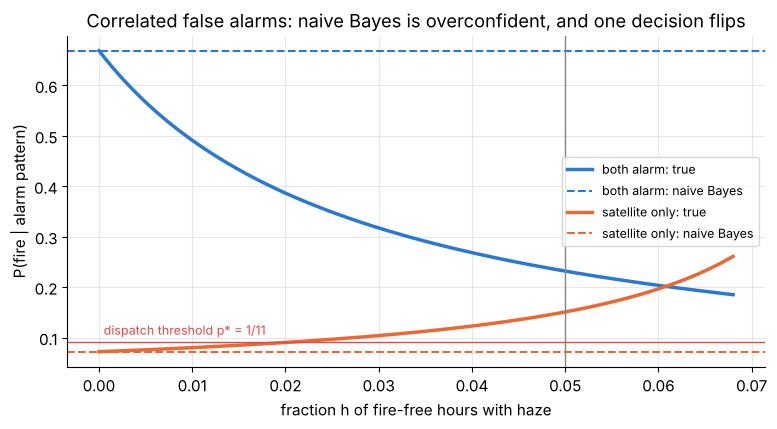

In [32]:
h_grid = np.linspace(0, 0.068, 200)          # h above 0.068 would need a negative clear-weather FPR
p_star_fire = C_FP_FIRE / (C_FP_FIRE + C_FN_FIRE)
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.plot(h_grid, [true_posterior_haze(1, 1, h) for h in h_grid], color=BLUE, lw=2.5, label="both alarm: true")
ax.axhline(naive_posterior(PRIOR_FIRE, rates_list, (1, 1)), color=BLUE, lw=1.5, ls="--", label="both alarm: naive Bayes")
ax.plot(h_grid, [true_posterior_haze(1, 0, h) for h in h_grid], color=ORANGE, lw=2.5, label="satellite only: true")
ax.axhline(naive_posterior(PRIOR_FIRE, rates_list, (1, 0)), color=ORANGE, lw=1.5, ls="--", label="satellite only: naive Bayes")
ax.axhline(p_star_fire, color=RED, lw=1)
ax.text(0.0005, p_star_fire + 0.015, "dispatch threshold p* = 1/11", color=RED, fontsize=9)
ax.axvline(h_demo, color=MUTED, lw=1)
ax.set(xlabel="fraction h of fire-free hours with haze", ylabel="P(fire | alarm pattern)",
       title="Correlated false alarms: naive Bayes is overconfident, and one decision flips")
ax.legend(fontsize=9, loc="center right")
plt.show()

Two lessons, one for each pair of curves:

- **Overconfidence.** At $h = 0.05$, naive Bayes reports $P(\text{fire} \mid \text{both alarm}) \approx 0.669$, but the truth is about $0.232$. Two alarms that tend to fail *together* are worth much less than two independent alarms, because the second one mostly repeats what the first already said. Here the decision survives (0.232 is still above 1/11), but the crew is told "probably a fire" when the honest answer is "probably haze".
- **A flipped decision.** For "satellite alarm, ground sensor quiet", naive Bayes says $0.072$ (hold), while the truth at $h = 0.05$ is about $0.151$ (dispatch). Under haze both sensors usually fire together, so a *lone* satellite alarm suggests clear weather, and in clear weather the satellite's false alarms are rarer, which makes a fire more plausible. A model that ignores the shared cause gets the direction of this reasoning wrong. The flip happens once haze affects only about 2% of fire-free hours (the orange curve crosses the red line near $h \approx 0.02$).

The extreme case of correlated errors is **double counting**: the *same* information entering the model twice. Suppose the satellite's alarm reaches the fire center through two data feeds (the raw hotspot product and a "fire alert" product derived from it), and both are fed to the model as separate sensors. The model then multiplies the likelihood ratio 25 twice:

$$
\frac{1}{99} \times 25 \times 25 = \frac{625}{99} \;\Rightarrow\; P = \frac{625}{724} \approx 0.863 \qquad\text{instead of}\qquad \frac{25}{124} \approx 0.202 .
$$

One alarm, reported twice, turns "probably not a fire" into "almost certainly a fire".

> **Key idea.** Naive Bayes is exact when the observations are conditionally independent given the hypothesis, and *overconfident* when they share causes of error. Before multiplying likelihood ratios, ask: **could the same disturbance fool both sensors?** Common culprits: shared weather, shared hardware or software, one sensor's output being derived from another's, and copies of the same record.

> **Going deeper.** With enough labeled data you can estimate the joint likelihoods $P(S, G \mid H)$ directly (four numbers per class) instead of multiplying marginals. With $d$ binary sensors the joint table has $2^d$ cells per class, which is exactly why the naive assumption is tempting. A middle ground is to model the shared cause explicitly as a hidden variable (here: haze), which leads to *Bayesian networks*. Discriminative models such as logistic regression also cope better with redundant features, because their weights are fitted jointly rather than one feature at a time.

✏️ **Exercise 8: naive Bayes with missing readings.** Implement `naive_bayes_posterior(prior, sens, fpr, observed)`, where `sens` and `fpr` are lists with one entry per sensor and `observed` holds `1` (alarm), `0` (quiet) or `None` (sensor offline, no information) for each sensor. Work in log-odds so that thousands of sensors neither overflow nor underflow.

In [33]:
# ✏️ Exercise 8: naive Bayes with missing readings
def naive_bayes_posterior(prior, sens, fpr, observed):
    """P(H | observations) for conditionally independent sensors, where None means 'no reading'."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    sens, fpr = [0.85, 0.72], [0.034, 0.09]
    assert np.isclose(naive_bayes_posterior(0.01, sens, fpr, [1, 1]), 200 / 299), "both alarms"
    assert np.isclose(naive_bayes_posterior(0.01, sens, fpr, [1, 0]), 100 / 1387), "satellite only, ground quiet"
    assert np.isclose(naive_bayes_posterior(0.01, sens, fpr, [0, 0]), 100 / 207307), "both quiet"
    assert np.isclose(naive_bayes_posterior(0.01, sens, fpr, [1, None]), 25 / 124), "ground sensor offline"
    assert np.isclose(naive_bayes_posterior(0.2, sens, fpr, [None, None]), 0.2), "no observations -> prior"
    # Stress tests: plain products of likelihoods or odds overflow or underflow on these long sensor lists.
    try:
        out = naive_bayes_posterior(0.3, [0.9] * 1000, [0.2] * 1000, [1] * 1000)
        assert np.isfinite(out) and out > 0.999999, f"1,000 alarms must not overflow: got {out}"
        out = naive_bayes_posterior(0.3, [0.9] * 1000 + [0.8] * 1000, [0.2] * 1000 + [0.1] * 1000,
                                    [1] * 1000 + [0] * 1000)
        assert np.isclose(out, 0.3), ("1,000 alarms (LR 9/2 each) and 1,000 quiet readings (LR 2/9 each) "
                                      f"cancel out, so the prior 0.3 must come back: got {out}")
    except ArithmeticError as err:          # e.g. ZeroDivisionError or OverflowError from a plain product
        raise AssertionError(f"long sensor lists must not overflow or underflow ({type(err).__name__}: {err})") from None


run_check("Exercise 8", _test)

⏳ Exercise 8: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def naive_bayes_posterior(prior, sens, fpr, observed):
    log_odds = math.log(prior / (1 - prior))
    for s, f, obs in zip(sens, fpr, observed):
        if obs is None:                      # offline sensor: likelihood ratio 1, nothing to add
            continue
        log_odds += math.log(s / f) if obs else math.log((1 - s) / (1 - f))
    return float(special.expit(log_odds))
```
Quiet sensors contribute $\ln \Lambda_- < 0$, offline sensors contribute nothing. For the "both quiet" case the odds are $\frac{1}{99} \times \frac{0.15}{0.966} \times \frac{0.28}{0.91} = \frac{100}{207207}$, so $P = 100/207307 \approx 0.00048$. In the stress tests, multiplying 1,000 likelihood ratios of 4.5 would give $4.5^{1000} \approx 10^{653}$, far beyond the largest float (about $10^{308}$), while the sum of their logarithms is only about 1,504.
</details>

**Quick check.**
1. Two conditionally independent sensors have $\Lambda_+ = 5$ and $\Lambda_+ = 4$, and the prior is 2%. Both alarm. What is the posterior?
2. Two sensors are conditionally independent given the fire status. Are their alarms independent events?
3. A third "sensor" turns out to be a relabeled copy of the satellite feed. What likelihood ratio should its alarm get in the naive Bayes product?

<details>
<summary>Answer</summary>

1. Odds $= \frac{2}{98} \times 5 \times 4 = \frac{40}{98}$, so $P = \frac{40}{138} \approx 0.29$.
2. No. Both respond to the same hidden cause, so one alarm makes the other more likely (Section 6.2). Conditional independence says only that, *once the cause is known*, they carry no further information about each other.
3. A likelihood ratio of 1 (equivalently, leave it out). Given the satellite's verdict, the copy adds nothing new, and multiplying by 25 again is double counting.
</details>

## 7. Decisions under uncertainty: expected utility and the value of information

Sections 5 and 6 chose between two actions (alarm or not). Real decisions often have more options, and one of the most important is *"find out more before deciding"*. This section develops the general machinery: expected utility, decision trees solved by backward induction, and the value of information.

### 7.1 Expected utility

Back to joint #217 of Section 1, flagged by the drone, so $q = P(\text{cracked} \mid \text{flag}) = 141/335 \approx 0.4209$. The bridge engineer has three options:

| action | if cracked | if sound | expected utility |
|---|---|---|---|
| **keep the lane open** (do nothing for now) | $-400$ (the joint may fail: emergency closure, repairs) | $0$ | $-400\,q$ |
| **reinforce now** (bolt on a temporary steel plate) | $-60$ | $-60$ | $-60$ |
| **probe first** with an ultrasonic probe (cost 5), then decide | ? | ? | to be computed |

A **utility** $U(a, h)$ scores the outcome of action $a$ when the true state is $h$. Here utilities are negative costs. The **expected utility** of an action averages over the uncertain state, using the current (posterior) beliefs:

$$
\mathrm{EU}(a) = \sum_{h} P(h \mid \text{evidence})\;U(a, h).
$$

A rational decision maker picks the action with the highest expected utility, which is the same as the lowest expected cost. Without probing:

$$
\mathrm{EU}(\text{open}) = -400 \times 0.4209 = -168.36, \qquad \mathrm{EU}(\text{reinforce}) = -60 .
$$

So reinforcing beats doing nothing. The two break even at $400\,q = 60$, i.e. $q = 0.15$: only a joint with less than a 15% chance of being cracked should stay open without further checks.

### 7.2 Decision trees and backward induction

The probe has sensitivity $P(T^{+} \mid \text{cracked}) = 0.93$ and specificity $P(T^{-} \mid \text{sound}) = 0.88$, and its errors are independent of the drone's once the joint's true state is fixed. A **decision tree** lays out the order of events: squares are decisions (you choose), circles are chance events (nature chooses), leaves carry utilities.

```
 [choose] -- keep open ---------- (cracked? q = 0.421) ---- cracked: -400  /  sound: 0
    |
    +------ reinforce ------------------------------------- -60
    |
    +------ probe (pay 5) -- (result?) -- T+ (prob 0.461) --> [choose] -- keep open:  (cracked? q+ = 0.849)
                                      |                              +-- reinforce: -60
                                      +-- T- (prob 0.539) --> [choose] -- keep open:  (cracked? q- = 0.055)
                                                                     +-- reinforce: -60
```

Solve the tree from the leaves back to the root (**backward induction**, or "rolling back"): at a chance node take the *expectation*, at a decision node take the *best* branch. Every number comes from tools you already have:

1. **Probability of each probe result** (law of total probability): $P(T^{+}) = 0.93 \times 0.4209 + 0.12 \times 0.5791 = 0.4609$, and $P(T^{-}) = 0.5391$.
2. **Posterior after each result** (Bayes): $q^{+} = 0.93 \times 0.4209 / 0.4609 = 0.8492$ and $q^{-} = 0.07 \times 0.4209 / 0.5391 = 0.0547$.
3. **Best action after each result:** after $T^{+}$, keeping open gives $-400 \times 0.8492 = -339.7$, so reinforce ($-60$). After $T^{-}$, keeping open gives $-400 \times 0.0547 = -21.9$, which beats $-60$, so keep open.
4. **Roll back to the chance node:** $0.4609 \times (-60) + 0.5391 \times (-21.86) = -27.66 - 11.79 = -39.44$.
5. **Subtract the probe's cost:** $\mathrm{EU}(\text{probe}) = -39.44 - 5 = -44.44$.

Probing first ($-44.44$) beats reinforcing right away ($-60$), so the optimal plan is: **probe first, and reinforce if the probe confirms a crack, otherwise keep the lane open.**

### 7.3 What is information worth? EVSI and EVPI

The **expected value of sample information** (EVSI) is how much better you can expect to do *because* you will see the probe result, before paying for it:

$$
\text{EVSI} = \underbrace{\sum_{r} P(r)\,\max_a \mathrm{EU}(a \mid r)}_{\text{decide after seeing the result}} \;-\; \underbrace{\max_a \mathrm{EU}(a)}_{\text{decide now}} = -39.44 - (-60) = 20.56 .
$$

A probe is worth buying when its cost is below its EVSI (here $5 < 20.56$). The **expected value of perfect information** (EVPI) is the same quantity for a flawless oracle that reveals the truth: you would reinforce exactly the cracked joints and leave the sound ones alone, so

$$
\text{EVPI} = \big[q \times (-60) + (1-q) \times 0\big] - (-60) = -25.25 + 60 = 34.75 .
$$

Since no real test can beat an oracle, $0 \le \text{EVSI} \le \text{EVPI}$ always. EVPI is a quick **upper bound**: a test that costs more than 34.75 is not worth considering, however accurate it is.

> **Key idea.** Information has value only because it can **change a decision**. If every possible test result led to the same action, the EVSI would be exactly zero, no matter how accurate the test. Before paying for data, ask: "Which result would make me act differently?"

> **Going deeper.** Why is $0 \le \text{EVSI} \le \text{EVPI}$? *Lower bound:* after seeing the result you could always ignore it and take the action that is best now, so $\mathbb{E}_r[\max_a \mathrm{EU}(a \mid r)] \ge \max_a \mathrm{EU}(a)$. *Upper bound:* for each result $r$, a single action used whatever the state cannot beat the best action chosen separately for each state, $\max_a \mathbb{E}[U(a, h) \mid r] \le \mathbb{E}[\max_a U(a, h) \mid r]$. Averaging over $r$ (the law of total expectation) gives $\mathbb{E}_r[\max_a \mathrm{EU}(a \mid r)] \le \mathbb{E}_h[\max_a U(a, h)]$, and subtracting $\max_a \mathrm{EU}(a)$ from both sides completes the argument.

The cell below checks the whole tree by brute force: it simulates two million joints, keeps the flagged ones, and applies each strategy to every joint.

In [34]:
U_OPEN_CRACKED, U_REINFORCE, PROBE_COST = -400.0, -60.0, 5.0
PROBE_SENS, PROBE_SPEC = 0.93, 0.88
q_flag = 141 / 335                                         # P(cracked | drone flag) from Section 3


def best_eu_now(q):
    """Expected utility of the better of 'keep open' and 'reinforce' when P(cracked) = q."""
    return np.maximum(U_OPEN_CRACKED * q, U_REINFORCE)


p_pos = PROBE_SENS * q_flag + (1 - PROBE_SPEC) * (1 - q_flag)       # P(T+)
q_pos = PROBE_SENS * q_flag / p_pos                                  # P(cracked | T+)
q_neg = (1 - PROBE_SENS) * q_flag / (1 - p_pos)                      # P(cracked | T-)
eu_after = p_pos * best_eu_now(q_pos) + (1 - p_pos) * best_eu_now(q_neg)
evsi = eu_after - best_eu_now(q_flag)
evpi = q_flag * U_REINFORCE - best_eu_now(q_flag)
print(f"P(T+) = {p_pos:.4f}, q+ = {q_pos:.4f}, q- = {q_neg:.4f}")
print(f"EU: open {U_OPEN_CRACKED * q_flag:.2f} | reinforce {U_REINFORCE:.2f} | probe {eu_after - PROBE_COST:.2f}"
      f"   EVSI = {evsi:.2f}, EVPI = {evpi:.2f}")

# Monte Carlo: simulate joints, keep the flagged ones, apply each strategy.
rng_tree = np.random.default_rng(SEED)
n = 2_000_000
cracked_j = rng_tree.random(n) < 0.03
flagged_j = np.where(cracked_j, rng_tree.random(n) < 0.94, rng_tree.random(n) < 0.04)
cf = cracked_j[flagged_j]                                            # truth for the flagged joints only
probe_pos = np.where(cf, rng_tree.random(cf.size) < PROBE_SENS, rng_tree.random(cf.size) < 1 - PROBE_SPEC)
strategies = {
    "keep open": np.where(cf, U_OPEN_CRACKED, 0.0),
    "reinforce": np.full(cf.size, U_REINFORCE),
    "probe, then reinforce only if T+": -PROBE_COST + np.where(probe_pos, U_REINFORCE, np.where(cf, U_OPEN_CRACKED, 0.0)),
    "perfect information (oracle)": np.where(cf, U_REINFORCE, 0.0),
}
display(pd.DataFrame({"simulated mean utility": {k: v.mean() for k, v in strategies.items()}}).round(2))
print(f"{cf.size:,} flagged joints, simulated P(cracked | flag) = {cf.mean():.4f}")

P(T+) = 0.4609, q+ = 0.8492, q- = 0.0547
EU: open -168.36 | reinforce -60.00 | probe -44.44   EVSI = 20.56, EVPI = 34.75


,simulated mean utility
keep open,-168.17
reinforce,-60.00
"probe, then reinforce only if T+",-44.45
perfect information (oracle),-25.23


133,871 flagged joints; simulated P(cracked | flag) = 0.4204


The simulated strategies reproduce the rolled-back values: $-168.4$ for keeping open, $-60$ for reinforcing, $-44.4$ for probing first, and $-25.2$ for the oracle. The gaps between the rows *are* the value of information: $-44.44 - (-60) = 15.56$ is the EVSI minus the probe's cost of 5, and $-25.25 - (-60) = 34.75$ is the EVPI.

### 7.4 When is probing worth it?

The answer depends on how suspicious the joint is to begin with. Repeat the rollback for every prior $q$ from 0 to 1:

- If $q$ is tiny, even a positive probe would not justify reinforcing, so the probe cannot change the decision: keep open, don't probe.
- If $q$ is large, even a negative probe would leave too much doubt: reinforce, don't probe.
- In between, the probe result can change the action, so its EVSI is positive. The probe *pays*, however, only where its EVSI also exceeds its price of 5, and that band is a little narrower: a result can change the decision for about $0.022 < q < 0.689$, while probing is worth its price only for about $0.038 < q < 0.624$ (both bands are computed below).

A result can change the decision when a positive probe would lift the belief above the break-even point 0.15 and a negative probe would drop it below. In odds form, with $\Lambda_+ = 0.93/0.12 = 7.75$ and $\Lambda_- = 0.07/0.88 \approx 0.0795$, that means $\frac{q}{1-q} > \frac{0.15/0.85}{7.75} \approx 0.0228$ and $\frac{q}{1-q} < \frac{0.15/0.85}{0.0795} \approx 2.22$, i.e. $0.022 < q < 0.689$. Inside this band the best plan after probing is "reinforce only on $T^{+}$", and "probe, then reinforce only on $T^{+}$" has expected utility $-5 - 60\,P(T^{+}) - 400\,P(\text{cracked}, T^{-}) = -12.2 - 76.6\,q$, a straight line. It beats keeping open when $-12.2 - 76.6\,q > -400\,q$, i.e. $q > 12.2/323.4 \approx 0.038$, and beats reinforcing when $-12.2 - 76.6\,q > -60$, i.e. $q < 47.8/76.6 \approx 0.624$.

a probe result can change the decision for 0.0223 < q < 0.6893   (EVSI > 0)
probing is optimal (EVSI > price of 5) for 0.0377 < q < 0.6240   (no-probe break-even point: q = 0.15)


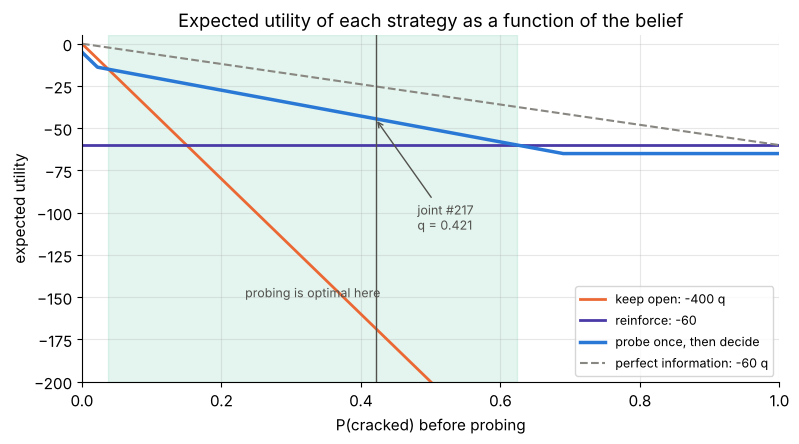

In [35]:
def eu_probe_once(q, cost=PROBE_COST):
    """Expected utility of 'probe once, then take the best action' when P(cracked) = q."""
    pp = PROBE_SENS * q + (1 - PROBE_SPEC) * (1 - q)          # never 0 or 1, so no division problems
    qp, qm = PROBE_SENS * q / pp, (1 - PROBE_SENS) * q / (1 - pp)
    return -cost + pp * best_eu_now(qp) + (1 - pp) * best_eu_now(qm)


band_lo = optimize.brentq(lambda q: eu_probe_once(q) - U_OPEN_CRACKED * q, 1e-6, 0.15)
band_hi = optimize.brentq(lambda q: eu_probe_once(q) - U_REINFORCE, 0.15, 0.99)
# A result changes the decision only if T+ lifts q above 0.15 and T- drops it below (odds form of Section 3.4).
flip_lo = from_odds(to_odds(0.15) / (PROBE_SENS / (1 - PROBE_SPEC)))
flip_hi = from_odds(to_odds(0.15) / ((1 - PROBE_SENS) / PROBE_SPEC))
print(f"a probe result can change the decision for {flip_lo:.4f} < q < {flip_hi:.4f}   (EVSI > 0)")
print(f"probing is optimal (EVSI > price of 5) for {band_lo:.4f} < q < {band_hi:.4f}   (no-probe break-even point: q = 0.15)")

q_grid = np.linspace(0, 1, 1001)
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(q_grid, U_OPEN_CRACKED * q_grid, color=ORANGE, lw=2, label="keep open: -400 q")
ax.plot(q_grid, np.full_like(q_grid, U_REINFORCE), color=VIOLET, lw=2, label="reinforce: -60")
ax.plot(q_grid, eu_probe_once(q_grid), color=BLUE, lw=2.5, label="probe once, then decide")
ax.plot(q_grid, U_REINFORCE * q_grid, color=MUTED, lw=1.5, ls="--", label="perfect information: -60 q")
ax.axvspan(band_lo, band_hi, color=AQUA, alpha=0.12)
ax.text((band_lo + band_hi) / 2, -150, "probing is optimal here", ha="center", color=INK2, fontsize=9)
ax.axvline(q_flag, color=INK2, lw=1)
ax.annotate("joint #217\nq = 0.421", xy=(q_flag, -44.44), xytext=(q_flag + 0.06, -110),
            arrowprops=dict(arrowstyle="->", color=INK2), fontsize=9, color=INK2)
ax.set(xlim=(0, 1), ylim=(-200, 5), xlabel="P(cracked) before probing",
       ylabel="expected utility", title="Expected utility of each strategy as a function of the belief")
ax.legend(fontsize=9, loc="lower right")
plt.show()

Reading the plot: the best you can do *without* the probe is the upper envelope of the orange and violet lines, a "roof" with its corner at $q = 0.15$. The blue curve rises above the roof only inside the shaded band, $0.038 < q < 0.624$, and it rises highest near the corner, where you are most unsure which action is right. That is the general pattern: **information is most valuable when you are close to indifferent between actions.** The dashed oracle line bounds every possible test from above, and its gap to the roof, also largest at the corner, is the EVPI.

### 7.5 Sequential testing: when to stop measuring

Suppose the probe can be repeated, each reading costing 5, with errors that are conditionally independent given the joint's state (for example, the probe is repositioned each time). After each reading the engineer can stop and act, or measure again. Let $V_k(q)$ be the best expected utility when at most $k$ more readings are allowed. Backward induction gives a **dynamic program**:

$$
V_0(q) = \max(-400\,q,\; -60), \qquad
V_k(q) = \max\Big(V_0(q),\; -5 + P(T^{+})\,V_{k-1}(q^{+}) + P(T^{-})\,V_{k-1}(q^{-})\Big),
$$

where $q^{\pm}$ are the Bayes updates of $q$ after each result. Today's posterior becomes the prior for the next reading, exactly as in Section 3.7.

In [36]:
def value_with_probes(q, k):
    """Best expected utility when at most k more conditionally independent probe readings are allowed."""
    q = np.asarray(q, dtype=float)
    stop_now = best_eu_now(q)
    if k == 0:
        return stop_now
    pp = PROBE_SENS * q + (1 - PROBE_SPEC) * (1 - q)
    qp, qm = PROBE_SENS * q / pp, (1 - PROBE_SENS) * q / (1 - pp)
    measure = -PROBE_COST + pp * value_with_probes(qp, k - 1) + (1 - pp) * value_with_probes(qm, k - 1)
    return np.maximum(stop_now, measure)


dp_rows = []
for k in [0, 1, 2, 3, 4, 5, 8]:
    gain = value_with_probes(q_grid, k) - best_eu_now(q_grid)
    keep_measuring = q_grid[gain > 1e-9]
    dp_rows.append({"max readings k": k, "V_k(0.421)": float(value_with_probes(q_flag, k)),
                    "measure while q in": "-" if k == 0 else f"({keep_measuring.min():.3f}, {keep_measuring.max():.3f})"})
display(pd.DataFrame(dp_rows).set_index("max readings k").round(2))

lr_probe_pos, lr_probe_neg = PROBE_SENS / (1 - PROBE_SPEC), (1 - PROBE_SENS) / PROBE_SPEC
print(f"each reading shifts the log-odds by ln({lr_probe_pos:.2f}) = {np.log(lr_probe_pos):+.3f} (T+) "
      f"or ln({lr_probe_neg:.4f}) = {np.log(lr_probe_neg):+.3f} (T-)")
for path in ["-", "--", "-+", "+"]:
    lrs = [lr_probe_pos if r == "+" else lr_probe_neg for r in path]
    print(f"  readings {path:<3s} -> P(cracked) = {from_odds(to_odds(q_flag) * np.prod(lrs)):.4f}")

,V_k(0.421),measure while q in
max readings k,,
0,-60.00,-
1,-44.44,"(0.038, 0.624)"
2,-41.49,"(0.023, 0.840)"
3,-39.36,"(0.022, 0.840)"
4,-39.36,"(0.021, 0.855)"
5,-38.94,"(0.021, 0.855)"
8,-38.87,"(0.021, 0.857)"


each reading shifts the log-odds by ln(7.75) = +2.048 (T+) or ln(0.0795) = -2.531 (T-)
  readings -   -> P(cracked) = 0.0547
  readings --  -> P(cracked) = 0.0046
  readings -+  -> P(cracked) = 0.3094
  readings +   -> P(cracked) = 0.8492


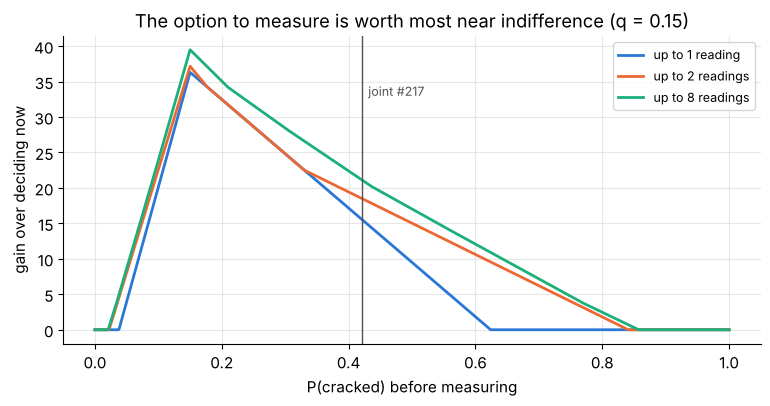

simulated mean utility -38.92 (dynamic program: -38.87); average number of readings 2.40
cracked but left open: 0.30% of flagged joints; sound but reinforced: 1.06%


In [37]:
fig, ax = plt.subplots(figsize=(9, 4))
for k, color in [(1, BLUE), (2, ORANGE), (8, AQUA)]:
    ax.plot(q_grid, value_with_probes(q_grid, k) - best_eu_now(q_grid), color=color, lw=2,
            label=f"up to {k} reading{'s' if k > 1 else ''}")
ax.axvline(q_flag, color=INK2, lw=1)
ax.text(q_flag + 0.01, 33, "joint #217", color=INK2, fontsize=9)
ax.set(xlabel="P(cracked) before measuring", ylabel="gain over deciding now",
       title="The option to measure is worth most near indifference (q = 0.15)")
ax.legend(fontsize=9)
plt.show()

# Monte Carlo: 400,000 flagged joints follow the optimal policy with up to 8 readings.
rng_seq = np.random.default_rng(SEED)
n_j, k_max = 400_000, 8
cracked_s = rng_seq.random(n_j) < q_flag
q_now = np.full(n_j, q_flag)
utility, n_read, active = np.zeros(n_j), np.zeros(n_j, int), np.ones(n_j, bool)
for k_left in range(k_max, 0, -1):
    uq, inv = np.unique(np.round(q_now, 12), return_inverse=True)            # only a few distinct beliefs occur
    active &= (value_with_probes(uq, k_left) - best_eu_now(uq))[inv] > 1e-9  # keep measuring?
    positive = np.where(cracked_s, rng_seq.random(n_j) < PROBE_SENS, rng_seq.random(n_j) < 1 - PROBE_SPEC)
    lr = np.where(positive, lr_probe_pos, lr_probe_neg)
    q_now = np.where(active, from_odds(to_odds(q_now) * lr), q_now)          # Bayes update for those who measured
    utility -= PROBE_COST * active
    n_read += active
keep_open = q_now < 0.15                                                     # final action: open iff -400 q > -60
utility += np.where(keep_open, np.where(cracked_s, U_OPEN_CRACKED, 0.0), U_REINFORCE)
print(f"simulated mean utility {utility.mean():.2f} (dynamic program: {float(value_with_probes(q_flag, k_max)):.2f}), "
      f"average number of readings {n_read.mean():.2f}")
print(f"cracked but left open: {np.mean(keep_open & cracked_s):.2%} of flagged joints, "
      f"sound but reinforced: {np.mean(~keep_open & ~cracked_s):.2%}")

What the dynamic program, the plot and the simulation show:

- **Diminishing returns.** The first reading raises the expected utility of joint #217 from $-60$ to $-44.44$. Allowing a second reading adds about $2.95$ and a third about $2.13$. After that the gains are tiny, and the value levels off near $-38.9$. The **value of an extra conditionally independent measurement** is the difference between consecutive rows, and it shrinks quickly.
- **A "keep measuring" band.** The optimal policy is: measure while the current belief lies inside the band, then act. With more readings allowed, the band widens (from about $(0.038, 0.624)$ to about $(0.021, 0.857)$), because a reading that does not settle things can be followed by another. In the plot, each curve is positive exactly on its band and peaks at $q = 0.15$, the belief at which keeping the lane open and reinforcing tie.
- **A walk in log-odds.** Each reading moves the log-odds by a fixed step, $+2.048$ for $T^{+}$ or $-2.531$ for $T^{-}$, so "measure while $q$ is in a band" means "keep walking while the log-odds stays between two boundaries". For joint #217, a negative first reading gives $q = 0.0547$, inside the band once a second reading is allowed. A second negative gives $0.0046$ (stop and keep the lane open), while a positive one gives $0.309$ (still undecided, so measure again).
- **Checked by simulation.** 400,000 simulated flagged joints that follow the optimal policy with up to eight readings average a utility of about $-38.9$, matching the dynamic program. They need about 2.4 readings each on average, and only about 0.3% of them end up cracked but left open.

> **Going deeper.** This "stop when the evidence leaves a band" structure is Abraham Wald's **sequential probability ratio test** (SPRT, 1945). Among all tests that achieve given error rates, it needs the fewest observations on average. It is used for clinical trials, A/B tests with early stopping, and industrial quality control.

> **Common pitfall.** Forgetting the cost of the test. A probe with an EVSI of 20.56 and a price of 5 improves the expected utility by 15.56, not 20.56. Conversely, a test whose price exceeds its EVSI should not be bought however accurate it is, and no test is worth more than the EVPI.

✏️ **Exercise 9: the value of a test.** Implement `value_of_test(q, u_risky_h, u_risky_not_h, u_safe, sens, spec, cost)` for a decision between a *risky* action (utility `u_risky_h` if the hypothesis $H$ is true, `u_risky_not_h` if it is false) and a *safe* action (utility `u_safe` either way). The test has the given sensitivity and specificity for detecting $H$, and `q` is the current $P(H)$. Return a dict with `"eu_no_test"` (best expected utility deciding now), `"eu_test"` (testing first, *net* of the cost), `"evsi"` (before subtracting the cost) and `"evpi"`.

The second test case is a software team deciding whether to ship a release tonight. If the release hides a critical bug (probability 0.10), shipping costs $-500$ (an outage). Otherwise shipping gains $+20$, and postponing is worth 0. A one-hour canary rollout to 1% of users costs 2 and catches a critical bug with sensitivity 0.90 and specificity 0.90.

In [38]:
# ✏️ Exercise 9: the value of a test
def value_of_test(q, u_risky_h, u_risky_not_h, u_safe, sens, spec, cost):
    """Return eu_no_test, eu_test (net of cost), evsi and evpi for a risky-vs-safe decision."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    out = value_of_test(141 / 335, -400, 0, -60, 0.93, 0.88, 5)
    want = {"eu_no_test": -60.0, "eu_test": -44.44059701, "evsi": 20.55940299, "evpi": 34.74626866}
    for k, v in want.items():
        assert k in out, f"missing key '{k}'"
        assert np.isclose(out[k], v), f"bridge, {k}: expected {v:.4f}, got {out[k]}"
    out = value_of_test(0.10, -500, 20, 0, 0.90, 0.90, 2)
    want = {"eu_no_test": 0.0, "eu_test": 9.2, "evsi": 11.2, "evpi": 18.0}
    for k, v in want.items():
        assert np.isclose(out[k], v), f"release, {k}: expected {v}, got {out[k]}"
    out = value_of_test(0.01, -400, 0, -60, 0.93, 0.88, 5)
    assert np.isclose(out["evsi"], 0.0), "a test that cannot change the decision has EVSI = 0"


run_check("Exercise 9", _test)

⏳ Exercise 9: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def value_of_test(q, u_risky_h, u_risky_not_h, u_safe, sens, spec, cost):
    def best(p):                                   # best expected utility when P(H) = p
        return max(p * u_risky_h + (1 - p) * u_risky_not_h, u_safe)
    eu_now = best(q)
    p_pos = sens * q + (1 - spec) * (1 - q)        # law of total probability
    q_pos = sens * q / p_pos                       # Bayes after a positive result
    q_neg = (1 - sens) * q / (1 - p_pos)           # Bayes after a negative result
    eu_informed = p_pos * best(q_pos) + (1 - p_pos) * best(q_neg)
    perfect = q * max(u_risky_h, u_safe) + (1 - q) * max(u_risky_not_h, u_safe)
    return {"eu_no_test": eu_now, "eu_test": eu_informed - cost,
            "evsi": eu_informed - eu_now, "evpi": perfect - eu_now}
```
For the release: shipping now is worth $0.1 \times (-500) + 0.9 \times 20 = -32$, so postponing (0) wins. The canary raises an alarm with probability $0.18$, after which $P(\text{bug}) = 0.5$ (postpone). After a clean canary $P(\text{bug}) = 0.01/0.82 \approx 0.0122$, and shipping is worth about $13.66$. So $\text{EVSI} = 0.82 \times 13.66 = 11.2$, and the canary, at a cost of 2, is well worth it. With perfect information you would ship exactly when there is no critical bug: $0.9 \times 20 = 18$.
</details>

**Quick check.**
1. A test's result can never change your decision. What is its EVSI?
2. For joint #217 the EVPI is 34.75. Would you pay 40 for a probe that is always right?
3. In a decision tree, why do we *average* at chance nodes but *maximize* at decision nodes?

<details>
<summary>Answer</summary>

1. Zero. If every result leads to the action you would take anyway, the informed plan and the uninformed plan are the same plan.
2. No. Perfect information improves the expected utility by 34.75, so paying 40 for it would leave you $40 - 34.75 = 5.25$ worse off on average than deciding now.
3. At a chance node nature picks the branch, so all you can do is weight each branch by its probability. At a decision node *you* pick the branch, using everything known at that moment, so you take the best one.
</details>

## 8. Beliefs about a count: updating a whole distribution

So far every hypothesis was yes/no: cracked or sound, phishing or legitimate, fire or no fire. Often the unknown is a **number**: how many machines are faulty, how many customers will churn, how many fields are infected. Bayes' rule works the same way, except that the prior and the posterior are now whole **probability distributions**, and decisions depend on more than a single "probability of yes".

### 8.1 The scenario and the language of discrete random variables

A farming cooperative manages a block of **four wheat fields**. Let $X$ be the number of fields infected with a fungal rust this week, so $X \in \{0, 1, 2, 3, 4\}$. Records from past seasons give the prior:

| $k$ (infected fields) | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| $P(X = k)$ | 0.40 | 0.25 | 0.20 | 0.10 | 0.05 |

A **random variable** is a number determined by chance, and a **discrete** one takes values in a list. Its distribution is described by the **probability mass function** (PMF) $p(k) = P(X = k)$, which is non-negative and sums to 1. Three summaries come up again and again:

- **Cumulative distribution function** (CDF): $F(k) = P(X \le k) = \sum_{j \le k} p(j)$, a staircase that climbs from 0 to 1. Tail questions use it: $P(X \ge 2) = 1 - F(1)$.
- **Expected value** (mean): $\mathbb{E}[X] = \sum_k k\,p(k)$, the balance point of the PMF.
- **Variance**: $\operatorname{Var}(X) = \mathbb{E}\big[(X - \mathbb{E}X)^2\big] = \mathbb{E}[X^2] - (\mathbb{E}[X])^2$, the average squared distance from the mean. The **standard deviation** $\sqrt{\operatorname{Var}(X)}$ is in the same units as $X$.

By hand for the prior:

| $k$ | $p(k)$ | $F(k)$ | $k\,p(k)$ | $k^2\,p(k)$ |
|---|---|---|---|---|
| 0 | 0.40 | 0.40 | 0 | 0 |
| 1 | 0.25 | 0.65 | 0.25 | 0.25 |
| 2 | 0.20 | 0.85 | 0.40 | 0.80 |
| 3 | 0.10 | 0.95 | 0.30 | 0.90 |
| 4 | 0.05 | 1.00 | 0.20 | 0.80 |
| **sum** | 1 | | $\mathbb{E}[X] = 1.15$ | $\mathbb{E}[X^2] = 2.75$ |

so $\operatorname{Var}(X) = 2.75 - 1.15^2 = 2.75 - 1.3225 = 1.4275$, the standard deviation is $\approx 1.195$ fields, and $P(X \ge 2) = 1 - 0.65 = 0.35$.

> **Common pitfall.** $\mathbb{E}[X^2]$ is **not** the variance, and $\mathbb{E}[X^2] \ne (\mathbb{E}[X])^2$ in general. Here $\mathbb{E}[X^2] = 2.75$, $(\mathbb{E}[X])^2 = 1.3225$, and the variance is their difference. Two more classic slips: averaging the *values* $0, \dots, 4$ without the probabilities (giving 2), and reading the CDF $F(1) = 0.65$ as $P(X = 1)$.

### 8.2 Updating a whole distribution

A satellite crop-health model issues a **block alert** when it sees stressed vegetation. The more fields are infected, the more likely an alert:

| $k$ | 0 | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|
| $P(\text{alert} \mid X = k)$ | 0.04 | 0.22 | 0.50 | 0.76 | 0.92 |

This row is a list of **likelihoods**, one per hypothesis $X = k$. It does *not* sum to 1 (it sums to 2.44), and it is not a distribution over $k$. The alert has just arrived. Bayes' rule with five hypotheses (Section 3.1) updates every value of $k$ at once:

$$
P(X = k \mid \text{alert}) = \frac{P(\text{alert} \mid X = k)\,P(X = k)}{\sum_{j=0}^{4} P(\text{alert} \mid X = j)\,P(X = j)} .
$$

| $k$ | prior | likelihood | prior × likelihood | posterior |
|---|---|---|---|---|
| 0 | 0.40 | 0.04 | 0.016 | $16/293 \approx 0.0546$ |
| 1 | 0.25 | 0.22 | 0.055 | $55/293 \approx 0.1877$ |
| 2 | 0.20 | 0.50 | 0.100 | $100/293 \approx 0.3413$ |
| 3 | 0.10 | 0.76 | 0.076 | $76/293 \approx 0.2594$ |
| 4 | 0.05 | 0.92 | 0.046 | $46/293 \approx 0.1570$ |
| **sum** | 1 | (2.44) | $P(\text{alert}) = 0.293$ | 1 |

The recipe is always the same: **multiply** prior by likelihood, **add up** the products to get the evidence $P(\text{alert})$, **divide** to normalize. The posterior mean is $\mathbb{E}[X \mid \text{alert}] = 667/293 \approx 2.28$ fields, up from 1.15. The same recipe with $P(\text{no alert} \mid X = k) = 1 - P(\text{alert} \mid X = k)$ gives the posterior after a quiet week, with mean $69/101 \approx 0.68$.

In [39]:
k_vals = np.arange(5)
prior_k = np.array([0.40, 0.25, 0.20, 0.10, 0.05])
lik_alert = np.array([0.04, 0.22, 0.50, 0.76, 0.92])

p_alert_k = np.sum(prior_k * lik_alert)                         # evidence, by total probability
post_alert = prior_k * lik_alert / p_alert_k
post_quiet = prior_k * (1 - lik_alert) / (1 - p_alert_k)


def pmf_stats(pmf):
    mean = np.sum(k_vals * pmf)
    second = np.sum(k_vals**2 * pmf)
    return {"E[X]": mean, "E[X^2]": second, "Var(X)": second - mean**2, "SD": np.sqrt(second - mean**2),
            "P(X >= 2)": pmf[2:].sum(), "P(X >= 3)": pmf[3:].sum()}


dists = {"prior": prior_k, "after alert": post_alert, "after quiet week": post_quiet}
display(pd.DataFrame({name: pmf_stats(p) for name, p in dists.items()}).round(4))
print(f"P(alert) = {p_alert_k:.3f}")
print("CDF after alert:", np.round(np.cumsum(post_alert), 4))
print("Check (law of total probability): P(alert) * post_alert + P(quiet) * post_quiet =",
      np.round(p_alert_k * post_alert + (1 - p_alert_k) * post_quiet, 4), "= prior")

,prior,after alert,after quiet week
E[X],1.1500,2.2765,0.6832
E[X^2],2.7500,6.3993,1.2376
Var(X),1.4275,1.2171,0.7709
SD,1.1948,1.1032,0.8780
P(X >= 2),0.3500,0.7577,0.1810
P(X >= 3),0.1500,0.4164,0.0396


P(alert) = 0.293
CDF after alert: [0.0546 0.2423 0.5836 0.843  1.    ]
Check (law of total probability): P(alert) * post_alert + P(quiet) * post_quiet = [0.4  0.25 0.2  0.1  0.05] = prior


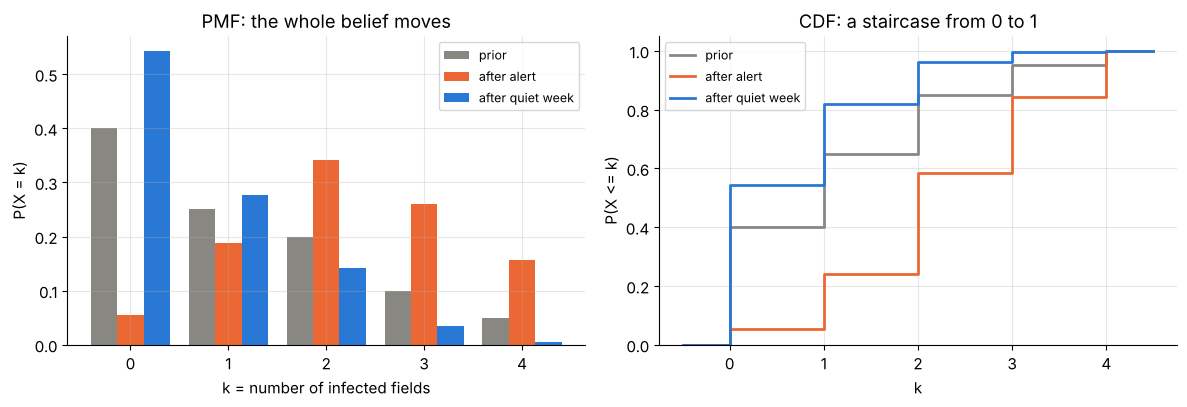

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
width = 0.27
for i, (name, pmf, color) in enumerate([("prior", prior_k, MUTED), ("after alert", post_alert, ORANGE),
                                         ("after quiet week", post_quiet, BLUE)]):
    axes[0].bar(k_vals + (i - 1) * width, pmf, width=width, color=color, label=name)
    axes[1].step(np.r_[-0.5, k_vals, 4.5], np.r_[0, np.cumsum(pmf), 1.0], where="post", color=color, lw=2, label=name)
axes[0].set(xlabel="k = number of infected fields", ylabel="P(X = k)", title="PMF: the whole belief moves")
axes[1].set(xlabel="k", ylabel="P(X <= k)", title="CDF: a staircase from 0 to 1", ylim=(0, 1.05))
for ax in axes:
    ax.set_xticks(k_vals)
    ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

The alert does not just "raise the probability of infection": it reshapes the entire distribution. Mass flows from $k = 0$ (0.40 to 0.05) toward $k = 2$ to $4$, and the probability of a bad week with at least three infected fields almost triples, from 0.15 to 0.42. After a quiet week the mass flows the other way. The check printed above shows that the two possible posteriors, weighted by how likely each is, **average back to the prior**: before the satellite reports, your *expected* posterior equals your prior. Evidence can move beliefs, but on average it moves them nowhere. You can often predict the *likely* direction: here the likely outcome, a quiet week (probability 0.707), lowers the expected number of infected fields a little, from 1.15 to 0.68, while the less likely alert raises it a lot, to 2.28. Weighted by their probabilities, the two moves cancel exactly: $0.707 \times 0.683 + 0.293 \times 2.277 = 0.483 + 0.667 = 1.15$.

### 8.3 Choosing a plan: expected cost under a whole distribution

The cooperative has three plans, with costs (in thousands) that depend on the unknown $k$:

| plan | cost $C(k)$ | $k = 0$ | 1 | 2 | 3 | 4 |
|---|---|---|---|---|---|---|
| **W**: wait, treat at harvest | $4k$ (yield lost on each infected field) | 0 | 4 | 8 | 12 | 16 |
| **S**: scout all fields, spot-treat | $2 + \min(k, 2) + 7\max(k - 2, 0)$ | 2 | 3 | 4 | 11 | 18 |
| **B**: blanket fungicide on all four fields | $6$ | 6 | 6 | 6 | 6 | 6 |

Plan S costs 2 for scouting plus 1 per infected field that the crew treats, but the crew can handle only two fields in time: each infected field beyond the second costs 7 as the rust spreads. The expected cost of a plan is the cost averaged over the PMF, $\mathbb{E}[C(X)] = \sum_k C(k)\,P(X = k)$. Under the prior:

$$
\mathbb{E}[C_S(X)] = 0.40 \times 2 + 0.25 \times 3 + 0.20 \times 4 + 0.10 \times 11 + 0.05 \times 18 = 0.8 + 0.75 + 0.8 + 1.1 + 0.9 = 4.35,
$$

while $\mathbb{E}[C_W(X)] = 4\,\mathbb{E}[X] = 4.6$ and $\mathbb{E}[C_B(X)] = 6$. Before the satellite reports, **scouting** is the best plan.

In [41]:
plans = {
    "W (wait)": lambda k: 4.0 * k,
    "S (scout + spot-treat)": lambda k: 2.0 + np.minimum(k, 2) + 7.0 * np.maximum(k - 2, 0),
    "B (blanket spray)": lambda k: np.full_like(k, 6.0, dtype=float),
}
cost_table = pd.DataFrame({belief: {plan: float(np.sum(cost(k_vals) * pmf)) for plan, cost in plans.items()}
                           for belief, pmf in dists.items()})
display(cost_table.round(4))
print("best plan:", {belief: cost_table[belief].idxmin() for belief in cost_table.columns})

,prior,after alert,after quiet week
W (wait),4.60,9.1058,2.7327
S (scout + spot-treat),4.35,7.7167,2.9547
B (blanket spray),6.00,6.0000,6.0000


best plan: {'prior': 'S (scout + spot-treat)', 'after alert': 'B (blanket spray)', 'after quiet week': 'W (wait)'}


The best plan depends on what the satellite says:

- **No report yet (prior):** S, expected cost 4.35.
- **After an alert:** S now expects $2261/293 \approx 7.72$ because the costly cases $k = 3, 4$ have become likely, and W expects $9.11$. **Blanket spraying** (6) wins.
- **After a quiet week:** **waiting** wins (2.73 versus 2.95 for scouting).

### 8.4 The plug-in trap: $\mathbb{E}[C(X)] \ne C(\mathbb{E}[X])$

A tempting shortcut: replace the uncertain $X$ by its mean and evaluate each plan there. After the alert, $\mathbb{E}[X \mid \text{alert}] \approx 2.28$, and

$$
C_S(2.2765) = 2 + 2 + 7 \times 0.2765 \approx 5.94 \;<\; 6 = C_B ,
$$

so the shortcut picks scouting. The correct expected cost of scouting is $7.72$, and blanket spraying is better. The shortcut **reverses the decision**.

The reason is the shape of $C_S$: it is **convex** (its slope jumps from 1 to 7 at $k = 2$). Plugging in the mean ignores the spread of $X$, in particular the 42% chance of three or more infected fields, exactly where $C_S$ is steep. **Jensen's inequality** makes this precise: for any convex function $C$, $\mathbb{E}[C(X)] \ge C(\mathbb{E}[X])$, with equality when $C$ is linear on the range of $X$. Plan W *is* linear, which is why $\mathbb{E}[4X] = 4\,\mathbb{E}[X]$ is exact for it.

> **Key idea.** When costs are nonlinear, decide with the **whole distribution**, not with a single summary such as the mean or the most likely value. Variance is not a nuisance statistic: it is where the expensive surprises live.

### 8.5 Decisions before vs after the evidence

Is the satellite worth subscribing to? Plan *before* knowing what it will report, by averaging over both possible reports (a small decision tree, exactly as in Section 7):

$$
\underbrace{0.293 \times 6}_{\text{alert} \,\to\, \text{B}} + \underbrace{0.707 \times 2.7327}_{\text{quiet} \,\to\, \text{W}} = 1.758 + 1.932 = 3.69 ,
$$

compared with 4.35 for scouting without it. So the alert service has $\text{EVSI} = 4.35 - 3.69 = 0.66$ (thousand) per week. With **perfect** knowledge of $k$ you would pick the cheapest plan for each $k$ (costs $0, 3, 4, 6, 6$), for an expected $0.40 \times 0 + 0.25 \times 3 + 0.20 \times 4 + 0.10 \times 6 + 0.05 \times 6 = 2.45$, so $\text{EVPI} = 4.35 - 2.45 = 1.90$. A field-by-field lab test would be worth at most 1.90 per week, whatever its accuracy.

The next cell verifies the posterior, the expected costs and the value of the alert by simulating a million weeks.

In [42]:
rng_crop = np.random.default_rng(SEED)
n_weeks = 1_000_000
x_sim = rng_crop.choice(5, size=n_weeks, p=prior_k)
alert_sim = rng_crop.random(n_weeks) < lik_alert[x_sim]

print(f"prior mean {x_sim.mean():.4f} (exact 1.15), variance {x_sim.var():.4f} (exact 1.4275), "
      f"P(alert) {alert_sim.mean():.4f} (exact 0.293)")
print("posterior PMF after alert (simulated):", np.round(np.bincount(x_sim[alert_sim], minlength=5) / alert_sim.sum(), 4))
print("posterior PMF after alert (exact):    ", np.round(post_alert, 4))
cost_sim = {name: cost(x_sim) for name, cost in plans.items()}
print(f"E[C_S | alert] simulated {cost_sim['S (scout + spot-treat)'][alert_sim].mean():.4f} (exact {2261 / 293:.4f})")
policy_cost = np.where(alert_sim, cost_sim["B (blanket spray)"], cost_sim["W (wait)"])   # alert -> B, quiet -> W
oracle_cost = np.minimum.reduce([c for c in cost_sim.values()])                         # best plan for the true k
print(f"weekly cost: always S {cost_sim['S (scout + spot-treat)'].mean():.4f} | follow the alert {policy_cost.mean():.4f} "
      f"| oracle {oracle_cost.mean():.4f}")

prior mean 1.1498 (exact 1.15), variance 1.4269 (exact 1.4275), P(alert) 0.2924 (exact 0.293)
posterior PMF after alert (simulated): [0.0538 0.1871 0.3418 0.2602 0.157 ]
posterior PMF after alert (exact):     [0.0546 0.1877 0.3413 0.2594 0.157 ]
E[C_S | alert] simulated 7.7248 (exact 7.7167)
weekly cost: always S 4.3492 | follow the alert 3.6877 | oracle 2.4500


The simulated posterior and costs match the exact ones to within sampling noise. Following the alert (spray after an alert, wait after a quiet week) costs about 3.69 per week instead of 4.35, and an oracle would bring it down to 2.45.

✏️ **Exercise 10: update and summarize a PMF.** Implement `posterior_pmf(prior, likelihood)`, which returns the normalized posterior PMF, and `pmf_summary(values, pmf)`, which returns the tuple `(mean, variance, cdf)` where `cdf` is a NumPy array of cumulative probabilities. Use $\operatorname{Var}(X) = \mathbb{E}[X^2] - (\mathbb{E}[X])^2$.

In [43]:
# ✏️ Exercise 10: update and summarize a PMF
def posterior_pmf(prior, likelihood):
    """Posterior PMF from a prior PMF and the likelihood of the evidence under each value."""
    # YOUR CODE HERE
    raise NotImplementedError


def pmf_summary(values, pmf):
    """Return (mean, variance, cdf) of a discrete distribution."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    prior = [0.40, 0.25, 0.20, 0.10, 0.05]
    lik = [0.04, 0.22, 0.50, 0.76, 0.92]
    post = posterior_pmf(prior, lik)
    assert np.allclose(post, np.array([16, 55, 100, 76, 46]) / 293), f"crop posterior: got {post}"
    mean, var, cdf = pmf_summary(range(5), prior)
    assert np.isclose(mean, 1.15) and np.isclose(var, 1.4275), f"prior mean/variance: got {(mean, var)}"
    assert np.allclose(cdf, [0.40, 0.65, 0.85, 0.95, 1.0]), f"prior CDF: got {cdf}"
    mean, var, _ = pmf_summary([10, 20, 30], [0.5, 0.3, 0.2])
    assert np.isclose(mean, 17.0) and np.isclose(var, 61.0), f"second PMF: got {(mean, var)}"
    assert np.allclose(posterior_pmf([0.5, 0.5], [0.3, 0.6]), [1 / 3, 2 / 3]), "two-point posterior"


run_check("Exercise 10", _test)

⏳ Exercise 10: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def posterior_pmf(prior, likelihood):
    joint = np.asarray(prior, float) * np.asarray(likelihood, float)   # multiply
    return joint / joint.sum()                                         # add up, divide

def pmf_summary(values, pmf):
    values, pmf = np.asarray(values, float), np.asarray(pmf, float)
    mean = float(np.sum(values * pmf))
    var = float(np.sum(values**2 * pmf) - mean**2)
    return mean, var, np.cumsum(pmf)
```
For the second test: $\mathbb{E}[X] = 5 + 6 + 6 = 17$, $\mathbb{E}[X^2] = 50 + 120 + 180 = 350$, so $\operatorname{Var}(X) = 350 - 289 = 61$.
</details>

✏️ **Exercise 11: the best plan under a distribution.** Implement `best_plan(values, pmf, plans)`, where `plans` maps a plan name to a cost function of a single value. Return `(name_of_cheapest_plan, dict_of_expected_costs)`. Do **not** plug in the mean.

In [44]:
# ✏️ Exercise 11: the best plan under a distribution
def best_plan(values, pmf, plans):
    """Return (cheapest plan name, {plan name: expected cost}) under the given PMF."""
    # YOUR CODE HERE
    raise NotImplementedError


def _test():
    crop_plans = {"W": lambda x: 4 * x, "S": lambda x: 2 + min(x, 2) + 7 * max(x - 2, 0), "B": lambda x: 6.0}
    name, costs = best_plan(range(5), [0.40, 0.25, 0.20, 0.10, 0.05], crop_plans)
    assert name == "S" and np.isclose(costs["S"], 4.35) and np.isclose(costs["W"], 4.6), f"prior: got {name}, {costs}"
    name, costs = best_plan(range(5), np.array([16, 55, 100, 76, 46]) / 293, crop_plans)
    assert name == "B" and np.isclose(costs["S"], 2261 / 293), f"after the alert: got {name}, {costs}"
    name, costs = best_plan([0, 1, 2, 3], [0.1, 0.2, 0.4, 0.3], {"cheap": lambda x: x**2, "flat": lambda x: 4.0})
    assert name == "flat" and np.isclose(costs["cheap"], 4.5), f"convex-cost scenario: got {name}, {costs}"


run_check("Exercise 11", _test)

⏳ Exercise 11: not implemented yet. Fill in the function and re-run this cell.


<details>
<summary><b>Solution</b> (try first!)</summary>

```python
def best_plan(values, pmf, plans):
    costs = {name: float(sum(p * cost(v) for v, p in zip(values, pmf))) for name, cost in plans.items()}
    return min(costs, key=costs.get), costs
```
The last test is Jensen's inequality in miniature: $\mathbb{E}[X] = 1.9$, so plugging in the mean gives $1.9^2 = 3.61 < 4$ and would pick "cheap", but $\mathbb{E}[X^2] = 0.2 + 1.6 + 2.7 = 4.5 > 4$.
</details>

**Quick check.**
1. $X$ equals 0 or 2, with probability 1/2 each. Compute $\mathbb{E}[X]$, $\mathbb{E}[X^2]$ and $\operatorname{Var}(X)$.
2. If the satellite raised an alert with the same probability 0.3 whatever the number of infected fields, what would the posterior after an alert be?
3. For which kind of cost function is plugging in the mean, $C(\mathbb{E}[X])$, always exact?

<details>
<summary>Answer</summary>

1. $\mathbb{E}[X] = 1$, $\mathbb{E}[X^2] = 0.5 \times 0 + 0.5 \times 4 = 2$, and $\operatorname{Var}(X) = 2 - 1^2 = 1$.
2. Exactly the prior. A likelihood that is the same for every hypothesis cancels in the normalization: an alert that is equally likely in every situation carries no information.
3. Linear (affine) costs $C(x) = a + bx$, because $\mathbb{E}[a + bX] = a + b\,\mathbb{E}[X]$ by linearity of expectation. Plan W in Section 8.3 is linear, and plan S is not.
</details>

## 9. Exam-style practice

Twelve multiple-choice questions in the style of olympiad and university exams. Each has exactly one correct option: when several options recommend the same action, only the one whose reasons and numbers are also all correct counts. Work them out on paper first (a 2×2 table of natural frequencies or a small decision tree is usually the fastest route), then open the answer. Every answer explains why the correct option is right **and** what mistake leads to each wrong option, because exam distractors are built from exactly those mistakes. A code cell at the end recomputes every number used in the answers.

---

**Q1. Leak alarms under a crew budget.** A water utility puts acoustic leak sensors on 8,000 pipe segments, and about 1.5% of segments leak in a given month. On a balanced validation set, threshold T1 has sensitivity 0.95 and specificity 0.92, and threshold T2 has sensitivity 0.85 and specificity 0.985. A missed leak costs 600, a needless dig costs 5, and the repair crew can inspect at most 260 segments per month. Which option recommends the right threshold with correct supporting numbers?

- **A.** T1, because its expected monthly cost (about 6,752) is lower.
- **B.** T1, because it raises only about 124 alerts, well within the budget, at an expected cost of about 3,648.
- **C.** T2: it raises about 220 alerts (within the budget) at an expected cost of about 11,391, with a precision of about 0.46.
- **D.** T2, because its precision is about 0.98.

<details>
<summary>Answer</summary>

**C.** There are $8000 \times 0.015 = 120$ leaking and $7{,}880$ intact segments.

| | TP | FN | FP | alerts | expected cost |
|---|---|---|---|---|---|
| T1 | $120 \times 0.95 = 114$ | 6 | $7880 \times 0.08 = 630.4$ | 744.4 | $6 \times 600 + 630.4 \times 5 = 6{,}752$ |
| T2 | $120 \times 0.85 = 102$ | 18 | $7880 \times 0.015 = 118.2$ | 220.2 | $18 \times 600 + 118.2 \times 5 = 11{,}391$ |

T1 is cheaper on paper but needs 744 inspections, nearly three times the budget, so it is infeasible. T2 fits (220.2 ≤ 260), and its precision is $102 / 220.2 \approx 0.463$.

- **A** ignores the capacity constraint, and the cheapest threshold is useless if the crew cannot follow up its alerts.
- **B** applies the false-positive rate to the wrong group: $120 \times 0.08 = 9.6$ "false positives" uses the *leaking* segments, but false positives can only come from the 7,880 intact ones.
- **D** names the right threshold for a wrong reason. It ignores the prior: $0.85 / (0.85 + 0.015) \approx 0.98$ is the precision on a balanced set, not at 1.5% prevalence.
</details>

---

**Q2. Precision does not travel.** A card-fraud model is tested on a balanced set (50% fraud) and reaches recall 0.86 and precision 0.93. In production, 0.2% of transactions are fraudulent, and the way fraud and normal transactions look is unchanged. What precision should the team expect in production?

- **A.** 0.93
- **B.** about 0.0019
- **C.** about 0.024
- **D.** about 0.026

<details>
<summary>Answer</summary>

**D.** On a balanced set the prior odds are 1, so the precision odds equal the likelihood ratio: $\Lambda_+ = 0.93 / 0.07 \approx 13.29$. (Equivalently, $\text{FPR} = 0.86 \times 0.07 / 0.93 \approx 0.0647$ and $\Lambda_+ = 0.86 / 0.0647$.) In production the prior odds are $0.002 / 0.998$, so the posterior odds are $13.29 \times 0.002 / 0.998 \approx 0.0266$, and the precision is $0.0266 / 1.0266 \approx 0.026$. About 39 of every 40 alerts will be false.

- **A** assumes precision transfers between datasets with different class balance. It does not (Section 4.5).
- **B** multiplies precision by prevalence, $0.93 \times 0.002$, which is not a probability of anything useful.
- **C** takes the false-positive rate to be $1 - \text{precision} = 0.07$. But $1 - \text{precision}$ is the false *discovery* rate $P(\text{normal} \mid \text{alert})$, and the FPR is $P(\text{alert} \mid \text{normal}) \approx 0.0647$.
</details>

---

**Q3. A camera trap after oversampling.** A camera-trap classifier for a rare lynx was trained on a dataset oversampled to 30% lynx images. For a new field image it outputs $P(\text{lynx}) = 0.95$. In the field only 2% of images contain a lynx. Assuming pure prior shift, what is the calibrated field probability?

- **A.** 0.95
- **B.** 0.475
- **C.** about 0.279
- **D.** 0.019

<details>
<summary>Answer</summary>

**B.** Correct the odds by the ratio of the prior odds: $\frac{0.95}{0.05} \times \frac{0.02 / 0.98}{0.30 / 0.70} = 19 \times \frac{1/49}{3/7} = 19 \times \frac{1}{21} = \frac{19}{21}$, so $p = \frac{19/21}{1 + 19/21} = \frac{19}{40} = 0.475$.

- **A** forgets the correction: the 0.95 is calibrated for a world where 30% of images contain a lynx.
- **C** assumes the training prevalence was 50% (odds $19 \times 0.02 / 0.98 \approx 0.388$). The effective training prior is the one the model actually saw, 30% here.
- **D** multiplies the probability by the new prevalence. Prior shift acts on the **odds**, not by rescaling the probability.
</details>

---

**Q4. A cost matrix with a nonzero true-positive cost.** An underwater robot inspects a ship's hull and, for each panel, decides whether to send a diver. A dive costs 3 whether or not the panel is corroded (so $C_{TP} = C_{FP} = 3$), missed corrosion costs 9 ($C_{FN} = 9$), and correctly skipping a healthy panel costs nothing. Above which posterior probability of corrosion should the robot send the diver?

- **A.** 1/3
- **B.** 1/4
- **C.** 1/2
- **D.** 3/4

<details>
<summary>Answer</summary>

**A.** Send the diver when $3p + 3(1 - p) < 9p + 0 \cdot (1-p)$, i.e. $3 < 9p$, i.e. $p > 1/3$. With the general formula, $p^{*} = \frac{C_{FP} - C_{TN}}{(C_{FP} - C_{TN}) + (C_{FN} - C_{TP})} = \frac{3}{3 + 6} = \frac{1}{3}$.

- **B** uses $C_{FP} / (C_{FP} + C_{FN}) = 3/12$, which silently assumes $C_{TP} = 0$. The dive is paid even when it finds corrosion, so the regret of a miss is $9 - 3 = 6$, not 9.
- **C** is the default threshold, correct only when the two regrets are equal.
- **D** is $C_{FN} / (C_{FP} + C_{FN})$, the formula upside down. Sanity check: a more expensive miss should make you act *more* readily, so it must *lower* the threshold.
</details>

---

**Q5. Two gearbox sensors.** A wind farm estimates that 5% of gearboxes are developing a fault. A vibration sensor detects faults with sensitivity 0.88 and false-positive rate 0.08, and an oil-debris sensor has sensitivity 0.60 and false-positive rate 0.05. Their errors are conditionally independent. Both sensors alarm on turbine 12. Stopping a healthy turbine costs 4, and running a faulty one costs 10. What are $P(\text{fault} \mid \text{both alarms})$ and the better action?

- **A.** about 0.99, so stop the turbine.
- **B.** about 0.874, so keep running, because stopping is expected to cost $4 \times 0.874 \approx 3.50$ and running only $10 \times 0.126 \approx 1.26$.
- **C.** about 0.874, so stop the turbine: stopping is expected to cost about 0.50 and running about 8.74.
- **D.** about 0.548, so stop the turbine.

<details>
<summary>Answer</summary>

**C.** The likelihood ratios are $0.88 / 0.08 = 11$ and $0.60 / 0.05 = 12$. Posterior odds $= \frac{0.05}{0.95} \times 11 \times 12 = \frac{132}{19}$, so $P = \frac{132}{151} \approx 0.874$. Stopping wastes money only if the gearbox is healthy: $4 \times (1 - 0.874) \approx 0.50$. Running is costly only if it is faulty: $10 \times 0.874 \approx 8.74$. Stop.

- **A** ignores the 5% prior: $\frac{0.88 \times 0.60}{0.88 \times 0.60 + 0.08 \times 0.05} \approx 0.99$ is the answer only if faults were as common as healthy gearboxes.
- **B** attaches each cost to the wrong probability: it weights the cost of stopping by $P(\text{fault})$ and the cost of running by $P(\text{healthy})$, the states in which each action is *right*, instead of the state in which that action is a mistake.
- **D** adds the likelihood ratios ($11 + 12 = 23$) instead of multiplying them. Under conditional independence, evidence multiplies in odds and adds in **log**-odds.
</details>

---

**Q6. Should the rover take a picture first?** A rover can drill at a site that contains organic material with probability 0.30. Drilling is worth +100 if organics are present and −30 (a wasted drill bit) if not, and not drilling is worth 0. Before deciding, the rover can take a spectral image, which costs 15 and detects organics with sensitivity 0.85 and specificity 0.80. What should it do?

- **A.** Image first, because the expected utility of "image, then decide" is 21.3, which beats 9.
- **B.** Do not drill, because organics are present with probability below 0.5.
- **C.** Image first, because the image result would change the drilling decision, and information that can change a decision is always worth buying.
- **D.** Drill now without imaging: the image's EVSI is about 12.3, less than its cost of 15.

<details>
<summary>Answer</summary>

**D.** Drilling now: $0.30 \times 100 + 0.70 \times (-30) = 9 > 0$, so drill. With the image: $P(\text{positive}) = 0.85 \times 0.30 + 0.20 \times 0.70 = 0.395$. After a positive image $P(\text{organics}) = 0.255 / 0.395 \approx 0.646$, and drilling is worth $\approx 53.9$. After a negative image $P = 0.045 / 0.605 \approx 0.074$, drilling is worth $\approx -20.3$, so do not drill (0). Rolling back: $0.395 \times 53.9 + 0.605 \times 0 = 21.3$. So $\text{EVSI} = 21.3 - 9 = 12.3 < 15$: imaging would lower the expected utility to $21.3 - 15 = 6.3$.

- **A** forgets to pay for the image: 21.3 is the expected utility *before* subtracting its cost.
- **B** uses the default 0.5 threshold. With these payoffs, drilling pays whenever $100q - 30(1-q) > 0$, i.e. $q > 3/13 \approx 0.23$.
- **C** is half right: the image *can* change the decision, which is why its EVSI is positive, but it is worth buying only if the EVSI exceeds its price.
</details>

---

**Q7. The value of a perfect forecast.** A vineyard can harvest now (value 70) or wait a week. Waiting yields 100 if the week stays dry (probability 0.75) and 20 if heavy rain arrives (probability 0.25). What is the expected value of perfect information about the weather?

- **A.** 22.5
- **B.** 12.5
- **C.** 20
- **D.** 92.5

<details>
<summary>Answer</summary>

**B.** Without a forecast: waiting is worth $0.75 \times 100 + 0.25 \times 20 = 80 > 70$, so wait (80). With a perfect forecast you wait when it will be dry (100) and harvest now when it will rain (70): $0.75 \times 100 + 0.25 \times 70 = 92.5$. $\text{EVPI} = 92.5 - 80 = 12.5$.

- **A** compares with the wrong baseline, harvesting now (70) instead of the best action without information (80).
- **C** is $0.25 \times (100 - 20)$, the spread between the two outcomes of *waiting*. But a forecast of rain does not turn 20 into 100. It lets you switch to harvesting (70), so the gain in that branch is $0.25 \times (70 - 20) = 12.5$.
- **D** is the expected value *with* perfect information, not the *value of* the information.
</details>

---

**Q8. Summarizing a PMF.** The number $X$ of delivery drones that need a battery swap at a depot in a given hour has the distribution $P(X = 0, 1, 2, 3) = 0.45, 0.32, 0.17, 0.06$. Which line is correct?

- **A.** $\mathbb{E}[X] = 0.84$, $\operatorname{Var}(X) \approx 0.834$, $P(X \le 1) = 0.77$
- **B.** $\mathbb{E}[X] = 0.84$, $\operatorname{Var}(X) = 1.54$, $P(X \le 1) = 0.77$
- **C.** $\mathbb{E}[X] = 1.5$, $\operatorname{Var}(X) = 1.25$, $P(X \le 1) = 0.5$
- **D.** $\mathbb{E}[X] = 0.84$, $\operatorname{Var}(X) \approx 0.834$, $P(X \le 1) = 0.32$

<details>
<summary>Answer</summary>

**A.** $\mathbb{E}[X] = 0.32 + 0.34 + 0.18 = 0.84$, $\mathbb{E}[X^2] = 0.32 + 0.68 + 0.54 = 1.54$, and $\operatorname{Var}(X) = 1.54 - 0.84^2 = 1.54 - 0.7056 = 0.8344$. Also $P(X \le 1) = 0.45 + 0.32 = 0.77$.

- **B** reports $\mathbb{E}[X^2]$ as the variance and forgets to subtract $(\mathbb{E}[X])^2$.
- **C** averages the four values $0, 1, 2, 3$ as if they were equally likely, ignoring the PMF.
- **D** reads $P(X = 1)$ instead of the cumulative $P(X \le 1)$.
</details>

---

**Q9. Mites in the apiary.** A beekeeper has four hives. Let $X$ be the number infested with mites, with prior $P(X = 0, 1, 2, 3, 4) = 0.45, 0.30, 0.13, 0.08, 0.04$. An acoustic hive monitor raises an alarm with probability $0.06, 0.40, 0.60, 0.80, 0.95$ for $X = 0, 1, 2, 3, 4$. Plan I (inspect each hive, treat the infested ones) costs $2 + 3X$, and plan T (treat all four hives) costs 7 whatever $X$ is. The alarm sounds. Which option recommends the right plan with a correct justification?

- **A.** Plan I, because its expected cost is $2 + 3 \times 0.96 = 4.88 < 7$.
- **B.** Plan I, because the most likely value after the alarm is $X = 1$, where plan I costs $5 < 7$.
- **C.** Plan T, because $\mathbb{E}[X \mid \text{alarm}] \approx 2.78$, so plan I would cost about 10.33.
- **D.** Plan T, because $\mathbb{E}[X \mid \text{alarm}] \approx 1.90$, so plan I is expected to cost about 7.69.

<details>
<summary>Answer</summary>

**D.** Prior × likelihood: $0.027, 0.120, 0.078, 0.064, 0.038$, which sum to $P(\text{alarm}) = 0.327$. Posterior: $0.0826, 0.3670, 0.2385, 0.1957, 0.1162$, with mean $\mathbb{E}[X \mid \text{alarm}] = (0.120 + 2 \times 0.078 + 3 \times 0.064 + 4 \times 0.038) / 0.327 = 0.620 / 0.327 \approx 1.896$. Plan I's cost is linear in $X$, so $\mathbb{E}[2 + 3X] = 2 + 3 \times 1.896 \approx 7.69 > 7$. Treat all hives.

- **A** uses the prior mean 0.96 and ignores the alarm. That was the right analysis *before* the alarm.
- **B** decides with the posterior **mode**. Although $X = 1$ is the single most likely value, there is a 55% chance that two or more hives are infested, and the decision must weigh all of them.
- **C** normalizes the likelihoods $0.06, 0.40, 0.60, 0.80, 0.95$ as if they were a posterior, which drops the prior. The decision happens to be right, but the reasoning and the numbers are wrong.
</details>

---

**Q10. One flag, counted twice.** On a social platform, 5% of user-reported posts actually break the rules. A moderation classifier flags rule-breaking posts with likelihood ratio $\Lambda_+ = 12$. Because of a pipeline bug, each post is scored twice, and the two (identical) flags are combined as if they were independent evidence. For a post flagged in this way, what is the correct probability that it breaks the rules?

- **A.** about 0.883
- **B.** 0.60
- **C.** about 0.387
- **D.** about 0.774

<details>
<summary>Answer</summary>

**C.** Two copies of the same output carry the information of one flag. Odds $= \frac{0.05}{0.95} \times 12 \approx 0.632$, so $P \approx 0.632 / 1.632 \approx 0.387$.

- **A** is what the buggy pipeline reports: it multiplies by 12 twice (odds $\approx 7.58$). This is double counting (Section 6.6).
- **B** multiplies the *probability* by the likelihood ratio, $0.05 \times 12$. Likelihood ratios multiply **odds**. With a larger ratio this shortcut would even exceed 1.
- **D** doubles the correct posterior. Probabilities of the same event do not add up across repeated looks.
</details>

---

**Q11. Overnight staffing.** A hospital lab receives $X$ urgent samples overnight, with $P(X = 0, 1, 2, 3, 4) = 0.1, 0.2, 0.4, 0.2, 0.1$. The regular night shift handles two samples, and each extra sample costs 25 in overtime. Plan N (no extra staff) costs $25 \max(X - 2, 0)$. Plan S (schedule an on-call technician for 6) handles one more sample, so it costs $6 + 25 \max(X - 3, 0)$. Which option names the better plan with the correct expected costs?

- **A.** Plan N: the expected number of samples is 2, which the regular shift handles at no extra cost.
- **B.** Plan S: expected costs are 8.5 for S and 10 for N.
- **C.** Plan N: its expected cost is $25 \times P(X > 2) = 7.5$, below the 8.5 of plan S.
- **D.** Plan S: expected costs are 6 for S and 10 for N.

<details>
<summary>Answer</summary>

**B.** $\mathbb{E}[C_N] = 25 \times (1 \times 0.2 + 2 \times 0.1) = 25 \times 0.4 = 10$ and $\mathbb{E}[C_S] = 6 + 25 \times (1 \times 0.1) = 8.5$. Plan S is cheaper.

- **A** plugs the mean into a nonlinear cost: $C_N(\mathbb{E}[X]) = C_N(2) = 0$, but $\mathbb{E}[C_N(X)] = 10$. Overtime happens in the upper tail, which the mean hides (Jensen's inequality).
- **C** counts each overflow night once, but on a night with 4 samples there are **two** extra samples: $\mathbb{E}[\max(X - 2, 0)] = 0.4$, not $P(X > 2) = 0.3$.
- **D** reaches the right plan with a wrong number: plan S can still overflow (when $X = 4$), which adds $25 \times 0.1 = 2.5$.
</details>

---

**Q12. Three tests on a well.** Before testing, a well has a 10% chance of being contaminated. Three conditionally independent field tests are run, with these results and likelihood ratios: test 1 positive ($\Lambda = 4$), test 2 negative ($\Lambda = 0.5$), test 3 positive ($\Lambda = 6$). What is the posterior probability of contamination?

- **A.** about 0.571
- **B.** 0.400
- **C.** about 0.538
- **D.** about 0.253

<details>
<summary>Answer</summary>

**A.** Posterior odds $= \frac{0.1}{0.9} \times 4 \times 0.5 \times 6 = \frac{12}{9} = \frac{4}{3}$, so $P = \frac{4/3}{1 + 4/3} = \frac{4}{7} \approx 0.571$. The order of the tests does not matter.

- **B** uses only the last test (odds $6/9$), throwing away the first two results. Sequential updating must carry the posterior forward as the next prior.
- **C** adds the likelihood ratios ($4 + 0.5 + 6 = 10.5$) instead of multiplying them.
- **D** averages the three single-test posteriors ($0.308, 0.053, 0.400$). Posteriors from separate pieces of evidence are not averaged. Their likelihood ratios are multiplied.
</details>

---

The cell below recomputes every number quoted in the answers above. Run it after you have tried the questions.

In [45]:
def odds_post(prior, *lrs):
    """Posterior probability from a prior and any number of likelihood ratios."""
    return from_odds(to_odds(prior) * np.prod(lrs))


for name, (s, c) in {"T1": (0.95, 0.92), "T2": (0.85, 0.985)}.items():
    d = deployment_counts(8000, 0.015, s, c)
    print(f"Q1 {name}: alerts {d['TP'] + d['FP']:.1f}, cost {600 * d['FN'] + 5 * d['FP']:.0f}, PPV {d['TP'] / (d['TP'] + d['FP']):.4f}")
print(f"Q2 production precision: {odds_post(0.002, 0.93 / 0.07):.4f}")
print(f"Q3 field probability: {shift_prior_probs(0.95, 0.30, 0.02):.4f}")
print(f"Q4 threshold: {(3 - 0) / ((3 - 0) + (9 - 3)):.4f}")
p5 = odds_post(0.05, 0.88 / 0.08, 0.60 / 0.05)
print(f"Q5 P(fault) = {p5:.4f}, E[cost] stop {4 * (1 - p5):.2f}, run {10 * p5:.2f}")
pp6 = 0.85 * 0.30 + 0.20 * 0.70                          # P(positive image)
q6_pos, q6_neg = 0.255 / pp6, 0.045 / (1 - pp6)            # P(organics | image result)
eu_img = pp6 * max(130 * q6_pos - 30, 0) + (1 - pp6) * max(130 * q6_neg - 30, 0)   # drill is worth 100q - 30(1-q)
print(f"Q6 EU now {0.3 * 100 - 0.7 * 30:.1f}, EU with image {eu_img:.1f}, EVSI {eu_img - 9:.1f}")
print(f"Q7 EVPI = {0.75 * 100 + 0.25 * 70 - max(0.75 * 100 + 0.25 * 20, 70):.1f}")
pmf8 = np.array([0.45, 0.32, 0.17, 0.06])
m8 = np.sum(np.arange(4) * pmf8)
print(f"Q8 mean {m8:.2f}, variance {np.sum(np.arange(4)**2 * pmf8) - m8**2:.4f}, P(X <= 1) {pmf8[:2].sum():.2f}")
post9 = np.array([0.45, 0.30, 0.13, 0.08, 0.04]) * np.array([0.06, 0.40, 0.60, 0.80, 0.95])   # unnormalized
mean9 = np.sum(np.arange(5) * post9) / post9.sum()
print(f"Q9 P(alarm) {post9.sum():.4f}, posterior {np.round(post9 / post9.sum(), 4)}, E[X | alarm] {mean9:.4f}, "
      f"plan I {2 + 3 * mean9:.2f}")
print(f"Q10 P(breaks the rules) = {odds_post(0.05, 12):.4f}")
pmf11, x11 = np.array([0.1, 0.2, 0.4, 0.2, 0.1]), np.arange(5)
print(f"Q11 E[C_N] {np.sum(pmf11 * 25 * np.maximum(x11 - 2, 0)):.1f}, E[C_S] {np.sum(pmf11 * (6 + 25 * np.maximum(x11 - 3, 0))):.1f}")
print(f"Q12 P(contaminated) = {odds_post(0.1, 4, 0.5, 6):.4f}")

Q1 T1: alerts 744.4, cost 6752, PPV 0.1531
Q1 T2: alerts 220.2, cost 11391, PPV 0.4632
Q2 production precision: 0.0259
Q3 field probability: 0.4750
Q4 threshold: 0.3333
Q5 P(fault) = 0.8742; E[cost] stop 0.50, run 8.74
Q6 EU now 9.0, EU with image 21.3, EVSI 12.3
Q7 EVPI = 12.5
Q8 mean 0.84, variance 0.8344, P(X <= 1) 0.77
Q9 P(alarm) 0.3270, posterior [0.0826 0.367  0.2385 0.1957 0.1162], E[X | alarm] 1.8960, plan I 7.69
Q10 P(breaks the rules) = 0.3871
Q11 E[C_N] 10.0, E[C_S] 8.5
Q12 P(contaminated) = 0.5714


## 10. Summary and going further

### 10.1 Cheat sheet

| idea | formula | remember |
|---|---|---|
| conditional probability | $P(A \mid B) = P(A \cap B) / P(B)$ | shrink the world to $B$, then count |
| multiplication rule | $P(A \cap B) = P(A)\,P(B \mid A) = P(B)\,P(A \mid B)$ | chain rule for longer sequences |
| total probability | $P(E) = \sum_i P(E \mid H_i)\,P(H_i)$ | a weighted average over a partition |
| Bayes' theorem | $P(H \mid E) = \dfrac{P(E \mid H)\,P(H)}{\sum_j P(E \mid H_j)\,P(H_j)}$ | posterior ∝ likelihood × prior |
| odds form | $O(H \mid E) = O(H) \times \Lambda(E)$, with $O = p/(1-p)$ | the population sets the prior odds, the sensor sets $\Lambda$ |
| log-odds form | $\operatorname{logit} P(H \mid E) = \operatorname{logit} P(H) + \ln \Lambda(E)$ | evidence adds up |
| likelihood ratios of a test | $\Lambda_+ = s / (1 - c)$, $\;\Lambda_- = (1 - s) / c$ | silence is evidence too |
| PPV and NPV | $\text{PPV} = \dfrac{s\pi}{s\pi + (1-c)(1-\pi)}$, $\;\text{NPV} = \dfrac{c(1-\pi)}{c(1-\pi) + (1-s)\pi}$ | rare events: $\text{PPV} \approx \pi \Lambda_+$ |
| what transfers to a new prevalence | sensitivity, specificity, FPR, FNR, ROC curve | PPV, NPV, accuracy and F1 do **not** |
| prior-shift correction | $\operatorname{logit} p_d = \operatorname{logit} p_t - \operatorname{logit}\pi_t + \operatorname{logit}\pi_d$ | an intercept shift for logistic regression |
| expected deployment counts | $\mathbb{E}[TP] = N\pi s$, $\mathbb{E}[FN] = N\pi(1-s)$, $\mathbb{E}[FP] = N(1-\pi)(1-c)$ | each rate multiplies **its own** group |
| expected cost and alert volume | $C_{FN}\,\mathbb{E}[FN] + C_{FP}\,\mathbb{E}[FP]$, and $\;N[\pi s + (1-\pi)(1-c)] \le$ capacity | if the cost optimum is infeasible, fill the budget exactly |
| Bayes-optimal threshold | $p^{*} = \dfrac{C_{FP} - C_{TN}}{(C_{FP} - C_{TN}) + (C_{FN} - C_{TP})}$, usually $\dfrac{C_{FP}}{C_{FP} + C_{FN}}$ | needs **calibrated** deployment probabilities |
| ROC tangency | optimal slope $= \Lambda(t^{*}) = \dfrac{1-\pi}{\pi} \cdot \dfrac{C_{FP}}{C_{FN}}$ | same condition as $p^{*}$ |
| naive Bayes | $O(H \mid E_1, \dots, E_d) = O(H) \prod_j \Lambda(E_j)$ | only under conditional independence, and never count evidence twice |
| expected utility | $\mathrm{EU}(a) = \sum_h P(h \mid \text{evidence})\,U(a, h)$ | solve trees backwards: average at chance nodes, maximize at decisions |
| value of information | $\text{EVSI} = \mathbb{E}_r\big[\max_a \mathrm{EU}(a \mid r)\big] - \max_a \mathrm{EU}(a) \le \text{EVPI}$ | buy a test only if its price is below its EVSI |
| discrete random variable | $\mathbb{E}[X] = \sum_k k\,p(k)$, $\;\operatorname{Var}(X) = \mathbb{E}[X^2] - (\mathbb{E}[X])^2$, $\;F(k) = P(X \le k)$ | $\mathbb{E}[X^2]$ is not the variance |
| updating a distribution | $P(X = k \mid E) \propto P(E \mid X = k)\,P(X = k)$ | multiply, add up, divide |
| Jensen's inequality | $\mathbb{E}[C(X)] \ge C(\mathbb{E}[X])$ for convex $C$ | never plug the mean into a nonlinear cost |

### 10.2 Takeaways

1. **An alarm is evidence, not a verdict.** Its meaning depends on the base rate: a detector with 94% sensitivity and 96% specificity was right only 42% of the time it fired on bridge joints, and a "95%/95%" detector would be right only 16% of the time at 1% prevalence.
2. **Rates conditioned on the truth travel, and rates conditioned on the alarm do not.** Carry sensitivity and specificity from a balanced validation set into deployment, then recompute precision with Bayes' rule, and correct predicted probabilities for the new prior.
3. **Count before you calculate.** A 2×2 table of natural frequencies for an imaginary population makes most Bayes problems mechanical.
4. **Odds and log-odds make evidence modular.** Prior odds times likelihood ratios, and in log-odds, every independent observation is a fixed push up or down.
5. **Decide with costs, not with accuracy or precision.** Expected cost ranks thresholds. The Bayes-optimal rule thresholds a calibrated posterior at $p^{*} = C_{FP}/(C_{FP} + C_{FN})$, and capacity limits move the threshold to where the budget is exactly used.
6. **Check independence before multiplying.** Correlated sensors and duplicated records make naive Bayes overconfident, and can even reverse decisions.
7. **Information is worth what it changes.** EVSI is positive only when some result would change your action, it never exceeds EVPI, and the price of the test must be subtracted.
8. **Keep the whole distribution.** Posterior PMFs, not single numbers, drive good decisions when costs are nonlinear.

### 10.3 An exam checklist for Bayes and decision questions

- **Prior:** what is the base rate *in the population where the decision is made*? (Not the validation set's.)
- **Likelihoods:** for each rate, which group is it conditioned on? Sensitivity and specificity look from the truth to the alarm, and PPV and NPV look from the alarm to the truth.
- **Combine:** natural frequencies, or prior odds × likelihood ratios. Multiply ratios only for conditionally independent evidence, and use each piece of evidence once.
- **Decide:** list the actions, the states and the costs, compute each action's expected cost with **posterior** probabilities, respect constraints such as capacity, and subtract the cost of any test before comparing.
- **Count variables:** compute the PMF, then average costs over it, and check $\mathbb{E}[X^2]$ vs $\operatorname{Var}(X)$ and PMF vs CDF.
- **Sanity check:** posteriors between 0 and 1, posteriors for all hypotheses summing to 1, $0 \le \text{EVSI} \le \text{EVPI}$, and a Monte Carlo simulation when in doubt.

### 10.4 Going further

- Joseph K. Blitzstein and Jessica Hwang, *Introduction to Probability* (2nd ed.), especially the chapters on conditional probability and on discrete random variables. The accompanying course materials are free at [Stat 110](https://projects.iq.harvard.edu/stat110/home).
- Gerd Gigerenzer and Ulrich Hoffrage, ["How to improve Bayesian reasoning without instruction: Frequency formats"](https://doi.org/10.1037/0033-295X.102.4.684), *Psychological Review*, 1995: the natural-frequency experiments of Section 3.3.
- Tom Fawcett, ["An introduction to ROC analysis"](https://doi.org/10.1016/j.patrec.2005.10.010), *Pattern Recognition Letters*, 2006: ROC curves, iso-performance lines and cost-based operating points.
- Marco Saerens, Patrice Latinne and Christine Decaestecker, ["Adjusting the outputs of a classifier to new a priori probabilities: a simple procedure"](https://doi.org/10.1162/089976602753284446), *Neural Computation*, 2002: prior-shift correction and estimating an unknown deployment prior with EM.
- Abraham Wald, ["Sequential tests of statistical hypotheses"](https://doi.org/10.1214/aoms/1177731118), *Annals of Mathematical Statistics*, 1945: the sequential probability ratio test behind Section 7.5.
- Kevin P. Murphy, [*Probabilistic Machine Learning: An Introduction*](https://probml.github.io/pml-book/book1.html), the chapter on decision theory: Bayes-optimal decisions, ROC and precision-recall curves, and the value of information.
- Stuart Russell and Peter Norvig, [*Artificial Intelligence: A Modern Approach*](https://aima.cs.berkeley.edu/), the chapters on making simple decisions (utility theory, decision networks, the value of information) and on Bayesian networks.
- scikit-learn user guide: [Naive Bayes](https://scikit-learn.org/stable/modules/naive_bayes.html), [Probability calibration](https://scikit-learn.org/stable/modules/calibration.html), and [Tuning the decision threshold for class prediction](https://scikit-learn.org/stable/modules/classification_threshold.html), which includes cost-sensitive threshold tuning.